In [13]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
import pandas as pd
import warnings
import geopandas as gpd
import matplotlib.pyplot as plt
import glob
import os
import geopandas as gpd
import matplotlib.pyplot as plt
import glob
import os
from shapely.geometry import LineString, MultiLineString
warnings.filterwarnings('ignore', category=RuntimeWarning)

# train
python -u main.py train_multi --config configs/scoring_rule_multi_fdc.yml --gpu 0

# evaluate (after training completes)
python -u main.py evaluate_multi --config configs/scoring_rule_multi_fdc.yml --gpu 0

# NWM v3.0 retrospective is on AWS S3

In [ ]:
import xarray as xr
import numpy as np
import pandas as pd

def get_nwm_conus_daily(start, end, bucket='s3://noaa-nwm-retrospective-3-0-pds/CONUS/zarr/chrtout.zarr'):
    """
    Pull daily-mean NWM v3.0 retrospective streamflow for all gaged CONUS reaches.
    Returns wide-format DataFrame: Time index, USGS gage_id columns, streamflow (m3/s).
    """
    ds = xr.open_zarr(bucket, storage_options={'anon': True})
    streamflow = ds['streamflow'].sel(time=slice(start, end))
    daily = streamflow.resample(time='1D').mean().compute()

    gage_ids = np.char.strip(daily['gage_id'].values.astype(str))
    mask = gage_ids != ''
    gaged = daily.isel(feature_id=mask).assign_coords(gage_id=('feature_id', gage_ids[mask]))

    df = gaged.to_dataframe()['streamflow'].reset_index()
    lookup = pd.Series(gaged['gage_id'].values, index=gaged['feature_id'].values, name='gage_id')
    df['gage_id'] = df['feature_id'].map(lookup)

    wide = df.pivot_table(index='time', columns='gage_id', values='streamflow', aggfunc='mean')
    wide.index.name = 'Time'
    return wide

NWM_CONUS_Retrospect = get_nwm_conus_daily('2000-01-01', '2020-01-08')
NWM_CONUS_Retrospect



import glob
import pandas as pd

D = "/bighome/hdagne1/NeuralNGEN/data/nwm_conus_daily"
files = sorted(glob.glob(f"{D}/daily_*.parquet"))
print(len(files), "yearly files")

wide = pd.concat([pd.read_parquet(f) for f in files]).sort_index()
wide = wide.T.groupby(level=0).mean().T        # merge any gage that appears on more than one reach
wide.index = pd.to_datetime(wide.index)
wide.index.name = "Time"
wide = wide.loc["2000-01-01":"2020-01-08"]     # same window as the job

NWM_CONUS_Retrospect = wide                    # rows = daily dates, columns = USGS gage IDs, values = m3/s
print(NWM_CONUS_Retrospect.shape)
print(NWM_CONUS_Retrospect.index.min(), NWM_CONUS_Retrospect.index.max())
# NWM_CONUS_Retrospect.to_parquet(f"{D}/NWM_CONUS_Retrospect_daily.parquet")   # optional: save the merged table


In [ ]:
import glob, os
import pandas as pd

D = "/bighome/hdagne1/low-flow-thresholds-conus/USGS_Streamflow_Data/streamflow_retro_1979_2023_90"
START, END = "2000-01-01", "2020-01-08"            # same window as NWM
files = sorted(glob.glob(f"{D}/*.parquet"))
print(len(files), "gauge files")

def read_one(f, verbose=False):
    df = pd.read_parquet(f)
    if not isinstance(df.index, pd.DatetimeIndex):
        dcol = next(c for c in df.columns if any(k in c.lower() for k in ("date", "time")))
        df = df.set_index(pd.to_datetime(df[dcol]))
    num = df.select_dtypes("number")
    vcol = next((c for c in num.columns
                 if any(k in c.lower() for k in ("discharge", "streamflow", "flow", "00060", "value"))),
                num.columns[0])
    s = df[vcol].astype(float)
    idx = pd.DatetimeIndex(s.index)
    s.index = (idx.tz_localize(None) if idx.tz is not None else idx).normalize()
    s = s.groupby(level=0).mean()                  # one value per day
    if "cfs" in vcol.lower():                      # convert to m3/s like NWM
        s = s * 0.0283168
    if verbose:
        print("columns:", list(df.columns), "| using:", vcol, "| m3/s conversion:", "cfs" in vcol.lower())
    return s.rename(os.path.basename(f)[:-len(".parquet")])

read_one(files[0], verbose=True)                   # check this printout first

USGS_Daily = pd.concat([read_one(f) for f in files], axis=1).sort_index()
USGS_Daily = USGS_Daily.loc[START:END]
USGS_Daily.index.name = "Time"
print(USGS_Daily.shape, USGS_Daily.index.min(), USGS_Daily.index.max())

common = USGS_Daily.columns.intersection(NWM_CONUS_Retrospect.columns)
print("gauges in both USGS and NWM:", len(common))
USGS_Daily = USGS_Daily.dropna(axis=1)
USGS_CONUS = USGS_Daily.copy()

3723 gauge files
columns: ['site_no', 'monitoring_location_id', 'datetime', 'discharge_cfs', 'qualifier', 'approval_status', 'parameter_code', 'statistic_id', 'unit_of_measure', 'time_series_id', 'last_modified', 'source_api'] | using: discharge_cfs | m3/s conversion: True
(7313, 3723) 2000-01-01 00:00:00 2020-01-08 00:00:00
gauges in both USGS and NWM: 3547


,01010000,01010500,01011000,01013500,01014000,01015800,01017000,01018500,01019000,01021000,...,50056400,50061800,50065500,50067000,50071000,50092000,50112500,50124200,50138000,50144000
Time,,,,,,,,,,,,,,,,,,,,,
2000-01-01,18.689088,39.926688,24.069280,30.582144,113.267200,20.104928,36.811840,26.900960,3.624550,67.677152,...,0.622970,0.821187,1.472474,0.368118,1.897226,1.019405,0.339802,0.410594,2.690096,6.852666
2000-01-02,18.405920,39.643520,23.361360,28.599968,110.435520,19.538592,35.396000,26.844326,3.624550,57.199936,...,0.566336,0.906138,4.672272,0.481386,1.217622,0.934454,0.311485,0.382277,2.576829,6.682765
2000-01-03,18.264336,39.360352,24.352448,28.033632,107.603840,19.085523,33.980160,26.844326,3.624550,54.651424,...,0.651286,4.700589,4.757222,1.330890,3.398016,1.330890,0.311485,0.382277,2.548512,6.626131
2000-01-04,22.511856,48.138560,25.485120,27.410662,116.098880,18.462554,32.564320,26.929277,9.372861,59.182112,...,0.764554,2.803363,2.746730,0.962771,6.937616,1.274256,0.311485,0.382277,2.690096,6.541181
2000-01-05,25.201952,56.633600,23.786112,27.099178,124.593920,18.207702,31.714816,23.219776,13.280579,66.544480,...,1.529107,2.435245,1.812275,0.481386,2.293661,3.681184,0.339802,0.382277,3.936035,6.456230
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-01-04,24.182547,43.324704,24.210864,32.847488,123.178080,20.048294,32.564320,26.051456,18.264336,75.889024,...,0.441742,1.008078,2.888314,0.713583,2.200215,1.384692,0.080420,0.368118,4.898806,8.523357
2020-01-05,23.417994,41.908864,24.040963,31.431648,119.780064,19.680176,31.714816,26.023139,18.264336,73.906848,...,0.258249,0.722078,2.520195,0.608811,1.500790,0.934454,0.048422,0.265612,3.228115,8.268506
2020-01-06,22.625123,40.493024,23.786112,30.298976,116.665216,19.312058,30.865312,25.966506,18.264336,70.225664,...,0.266178,0.925959,2.596651,0.625801,1.851919,0.883484,0.059465,0.260231,3.029898,7.985338


# The Big Picture of NWM Performance:

NWM gages: 8660
USGS gages: 3200
Common gages: 3058
['01010000', '01010500', '01011000', '01013500', '01014000', '01015800', '01017000', '01018500', '01019000', '01021000', '01022500', '01030500', '01031500', '01034500', '01038000', '01042500', '01046500', '01047000', '01049500', '01052500']
(7313, 3058) (7313, 3058)
(3058, 6)
Gages with valid KGE: 3055
Gages with NaN KGE (zero variance/no overlap): 3
               KGE          NSE         PBIAS         RMSE            r  \
count  3055.000000  3057.000000   3057.000000  3057.000000  3055.000000   
mean     -0.195104   -10.384913     69.949829    40.727986     0.714537   
std       5.431648   229.125063    531.196524   145.986708     0.180354   
min    -143.915395 -7511.525823   -100.000000     0.009847    -0.399929   
25%       0.213244     0.099254    -12.853389     3.855428     0.644347   
50%       0.578592     0.470610      0.928706    10.953792     0.773171   
75%       0.730544     0.647852     25.010656    30.430586     0.83698

/local/tmp/ipykernel_1978824/1183167176.py:155: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


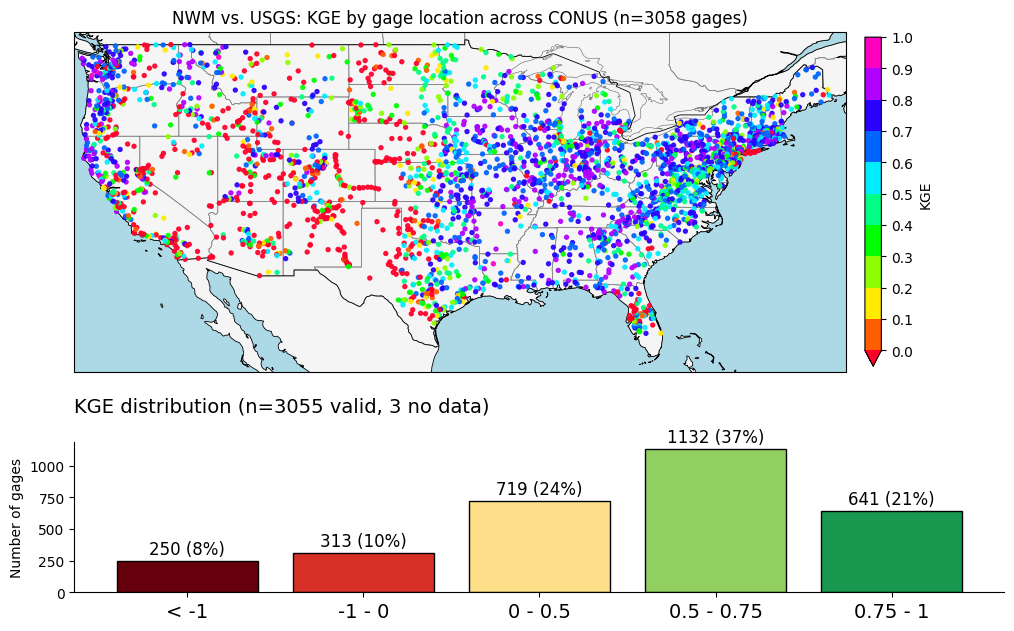

In [41]:
NWM_CONUS_Retrospect = NWM_CONUS_Retrospect.copy()
common_gages = NWM_CONUS_Retrospect.columns.intersection(USGS_CONUS.columns)

print(f"NWM gages: {len(NWM_CONUS_Retrospect.columns)}")
print(f"USGS gages: {len(USGS_CONUS.columns)}")
print(f"Common gages: {len(common_gages)}")

print(common_gages.tolist()[:20])  # preview first 20

NWM_common = NWM_CONUS_Retrospect[common_gages]
USGS_common = USGS_CONUS[common_gages]

print(NWM_common.shape, USGS_common.shape)

def kge(sim, obs):
    mask = sim.notna() & obs.notna()
    sim, obs = sim[mask], obs[mask]
    if len(sim) < 2 or obs.std() == 0 or sim.std() == 0 or obs.mean() == 0:
        return np.nan
    r = np.corrcoef(sim, obs)[0, 1]
    if np.isnan(r):
        return np.nan
    alpha = sim.std() / obs.std()
    beta = sim.mean() / obs.mean()
    return 1 - np.sqrt((r - 1)**2 + (alpha - 1)**2 + (beta - 1)**2)

def nse(sim, obs):
    mask = sim.notna() & obs.notna()
    sim, obs = sim[mask], obs[mask]
    denom = np.sum((obs - obs.mean())**2)
    if len(sim) < 2 or denom == 0:
        return np.nan
    return 1 - np.sum((sim - obs)**2) / denom

def pbias(sim, obs):
    mask = sim.notna() & obs.notna()
    sim, obs = sim[mask], obs[mask]
    if len(sim) < 2 or obs.sum() == 0:
        return np.nan
    return 100 * (sim.sum() - obs.sum()) / obs.sum()

def rmse(sim, obs):
    mask = sim.notna() & obs.notna()
    sim, obs = sim[mask], obs[mask]
    if len(sim) < 2:
        return np.nan
    return np.sqrt(np.mean((sim - obs)**2))

def correlation(sim, obs):
    mask = sim.notna() & obs.notna()
    sim, obs = sim[mask], obs[mask]
    if len(sim) < 2 or sim.std() == 0 or obs.std() == 0:
        return np.nan
    return np.corrcoef(sim, obs)[0, 1]

# ---------------------------------------------------------------
NWM_common, USGS_common = NWM_common.align(USGS_common, join='inner', axis=0)

results = []
for gage in common_gages:
    sim = NWM_common[gage]
    obs = USGS_common[gage]
    results.append({
        'gage_id': gage,
        'KGE': kge(sim, obs),
        'NSE': nse(sim, obs),
        'PBIAS': pbias(sim, obs),
        'RMSE': rmse(sim, obs),
        'r': correlation(sim, obs),
        'n_obs': (sim.notna() & obs.notna()).sum()
    })

metrics_df = pd.DataFrame(results).set_index('gage_id')

print(metrics_df.shape)
print(f"Gages with valid KGE: {metrics_df['KGE'].notna().sum()}")
print(f"Gages with NaN KGE (zero variance/no overlap): {metrics_df['KGE'].isna().sum()}")
print(metrics_df.describe())
print(metrics_df.sort_values('KGE', ascending=False).head(10))
# ---------------------------------------------------------------
# 1. Get gage coordinates from NWM zarr metadata
# ---------------------------------------------------------------


ds = xr.open_zarr('s3://noaa-nwm-retrospective-3-0-pds/CONUS/zarr/chrtout.zarr',
                   storage_options={'anon': True})

gage_ids = np.char.strip(ds['gage_id'].values.astype(str))
lats = ds['latitude'].values
lons = ds['longitude'].values

coord_lookup = pd.DataFrame({'gage_id': gage_ids, 'lat': lats, 'lon': lons})
coord_lookup = coord_lookup[coord_lookup['gage_id'] != '']

# ---------------------------------------------------------------
# 2. Merge coordinates onto metrics
# ---------------------------------------------------------------
metrics_geo = metrics_df.reset_index().merge(coord_lookup, on='gage_id', how='left')

# ---------------------------------------------------------------
# 3. Classify KGE into bins (KGE max is 1, so no upper clip bin needed)
# ---------------------------------------------------------------
bins = [-np.inf, -1, 0, 0.5, 0.75, 1]
labels = ['< -1', '-1 - 0', '0 - 0.5', '0.5 - 0.75', '0.75 - 1']
colors = ['#67000d', '#d73027', '#fee08b', '#91cf60', '#1a9850']

metrics_geo['KGE_bin'] = pd.cut(metrics_geo['KGE'], bins=bins, labels=labels)
n_nodata = metrics_geo['KGE'].isna().sum()
n_total = len(metrics_geo)
bin_counts = metrics_geo['KGE_bin'].value_counts().reindex(labels)

# scaled colorbar: 10 bins of 0.1, values below VMIN go to the extend="min" arrow
from matplotlib.colors import BoundaryNorm
VMIN, VMAX, NBINS = 0, 1, 10
CMAP = plt.get_cmap("gist_rainbow")
levels = np.linspace(VMIN, VMAX, NBINS + 1)
norm = BoundaryNorm(levels, CMAP.N, extend="min")

# ---------------------------------------------------------------
# 4. Combined figure: map on top, vertical bar chart below
# ---------------------------------------------------------------
fig = plt.figure(figsize=(12, 8))
gs = gridspec.GridSpec(2, 1, height_ratios=[3, 1], hspace=0.05)


ax_map = fig.add_subplot(gs[0], projection=ccrs.PlateCarree())
ax_bar = fig.add_subplot(gs[1])

ax_map.add_feature(cfeature.LAND, facecolor='whitesmoke')
ax_map.add_feature(cfeature.OCEAN, facecolor='lightblue')
ax_map.add_feature(cfeature.STATES, edgecolor='gray', linewidth=0.5)
ax_map.add_feature(cfeature.COASTLINE, linewidth=0.6)
ax_map.add_feature(cfeature.BORDERS, linewidth=0.6)

sc = ax_map.scatter(metrics_geo['lon'], metrics_geo['lat'], c=metrics_geo['KGE'],
                     cmap=CMAP, norm=norm, s=8, alpha=0.9,
                     transform=ccrs.PlateCarree(), zorder=5)

ax_map.set_extent([-125, -66, 24, 50], crs=ccrs.PlateCarree())
cb = plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=CMAP), ax=ax_map, label='KGE',
                  shrink=0.73, pad=0.02, extend="min", ticks=levels)
cb.set_ticklabels([f"{x:.1f}" for x in levels])
ax_map.set_title(f'NWM vs. USGS: KGE by gage location across CONUS (n={n_total} gages)', loc='center')

ax_bar.bar(labels, bin_counts.values, color=colors, edgecolor='black')
for i, v in enumerate(bin_counts.values):
    ax_bar.text(i, v + max(bin_counts.values)*0.02, f'{v} ({100*v/n_total:.0f}%)',
                ha='center', va='bottom', fontsize=12)

ax_bar.set_ylabel('Number of gages')
ax_bar.set_title(f'KGE distribution (n={n_total-n_nodata} valid, {n_nodata} no data)\n', fontsize=14, loc='left')
ax_bar.tick_params(axis='x', rotation=0, labelsize=14)
ax_bar.spines['top'].set_visible(False)
ax_bar.spines['right'].set_visible(False)
plt.tight_layout()
# plt.savefig('kge_spatial_map_with_summary.png', dpi=150)
plt.show()

# # ---------------------------------------------------------------
# # 5. Print summary table too, for reference/reporting
# # ---------------------------------------------------------------
# summary = bin_counts.to_frame('n_gages')
# summary['pct'] = 100 * summary['n_gages'] / n_total
# print(summary)
# print(f"\nTotal gages: {n_total}")
# print(f"No data (NaN KGE): {n_nodata}")

# What ngiab_data_cli gives us:

In [42]:
import geopandas as gpd
import xarray as xr
import pandas as pd
import glob
import os

GAGES =['04087170', '07289000', '08167500', '06730200', '02110400']

base_dir = '/scratch/hdagne1/Docker/gages_conus'

all_series = {}

for gage in GAGES:
    gage_dir = os.path.join(base_dir, f'gage-{gage}')

    # find the subset geopackage
    gpkg_files = glob.glob(os.path.join(gage_dir, 'config', '*.gpkg'))
    if not gpkg_files:
        print(f"{gage}: no geopackage found, skipping")
        continue
    gpkg_path = gpkg_files[0]

    # find the outlet nexus tied to this gage
    try:
        flow_attrs = gpd.read_file(gpkg_path, layer='flowpath-attributes')
        gage_row = flow_attrs[flow_attrs['gage'] == gage]
        if gage_row.empty:
            # fallback: sometimes gage id stored without leading zeros or as gage_nex_id
            gage_row = flow_attrs[flow_attrs['gage_nex_id'].notna()]
        if gage_row.empty:
            print(f"{gage}: no gage match found in flowpath-attributes, skipping")
            continue
        outlet_id = gage_row.iloc[0]['id']  # e.g. 'wb-483128'
        outlet_feature_id = int(outlet_id.replace('wb-', ''))
    except Exception as e:
        print(f"{gage}: error finding outlet ({e})")
        continue

    # find the troute output file
    troute_files = glob.glob(os.path.join(gage_dir, 'outputs', 'troute', '*.nc'))
    if not troute_files:
        print(f"{gage}: no troute output found, skipping")
        continue

    try:
        ds = xr.open_dataset(troute_files[0])
        flow = ds['flow'].sel(feature_id=outlet_feature_id).to_dataframe()['flow']
        all_series[gage] = flow
        print(f"{gage}: extracted {len(flow)} timesteps at feature_id {outlet_feature_id}")
    except Exception as e:
        print(f"{gage}: error extracting flow ({e})")

# combine into one dataframe: Time index, gage columns
NGEN_CONUS_Simulated = pd.DataFrame(all_series)
NGEN_CONUS_Simulated.index.name = 'Time'

print(NGEN_CONUS_Simulated.shape)
print(NGEN_CONUS_Simulated.head())

04087170: no geopackage found, skipping
07289000: no geopackage found, skipping
08167500: no geopackage found, skipping
06730200: no geopackage found, skipping
02110400: no geopackage found, skipping
(0, 0)
Empty DataFrame
Columns: []
Index: []


# Selected Gages:

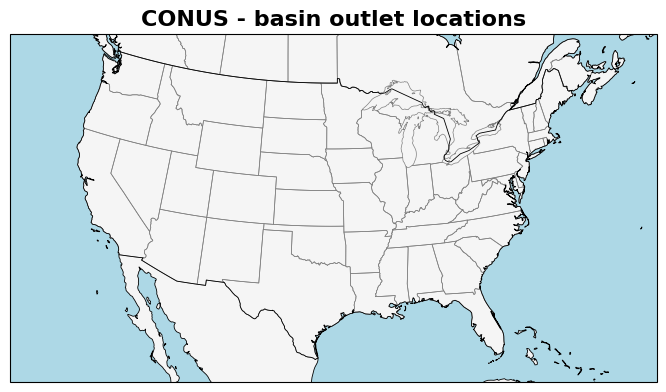

In [ ]:
import os
import glob
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from shapely.geometry import LineString, MultiLineString
from pyproj import Transformer

base_dir = '/scratch/hdagne1/Docker/gages_conus'

GAGES = [ '08167500', '06730200','04087170', '07289000', '02110400']

def get_outlet_point(geom):
    if isinstance(geom, LineString):
        return geom.coords[-1]
    elif isinstance(geom, MultiLineString):
        last_line = list(geom.geoms)[-1]
        return last_line.coords[-1]
    return None

def get_outlet_latlon(gpkg_path, gage, flowpaths, src_crs):
    flow_attrs = gpd.read_file(gpkg_path, layer='flowpath-attributes')
    gage_row = flow_attrs[flow_attrs['gage'] == gage]
    if gage_row.empty:
        return None
    outlet_id = gage_row.iloc[0]['id']
    outlet_geom = flowpaths[flowpaths['id'] == outlet_id]
    if outlet_geom.empty:
        return None
    line = outlet_geom.geometry.iloc[0]
    point = get_outlet_point(line)
    if point is None:
        return None
    transformer = Transformer.from_crs(src_crs, "EPSG:4326", always_xy=True)
    lon, lat = transformer.transform(point[0], point[1])
    return lon, lat

def plot_basin_panel(ax, gage):
    gpkg_files = glob.glob(os.path.join(base_dir, f'gage-{gage}', 'config', '*.gpkg'))
    if not gpkg_files:
        ax.set_visible(False)
        return None
    gpkg_path = gpkg_files[0]

    divides = gpd.read_file(gpkg_path, layer='divides')
    flowpaths = gpd.read_file(gpkg_path, layer='flowpaths')

    divides.plot(ax=ax, facecolor='none', edgecolor='gray', linewidth=0.35)
    flowpaths.plot(ax=ax, color='blue', linewidth=0.8)

    outlet_latlon = None
    try:
        outlet_latlon = get_outlet_latlon(gpkg_path, gage, flowpaths, divides.crs)
        flow_attrs = gpd.read_file(gpkg_path, layer='flowpath-attributes')
        gage_row = flow_attrs[flow_attrs['gage'] == gage]
        if not gage_row.empty:
            outlet_id = gage_row.iloc[0]['id']
            outlet_geom = flowpaths[flowpaths['id'] == outlet_id]
            if not outlet_geom.empty:
                line = outlet_geom.geometry.iloc[0]
                pt = get_outlet_point(line)
                if pt:
                    ax.plot(pt[0], pt[1], '*', color='red', markersize=10, zorder=5)
    except Exception as e:
        print(f"{gage}: could not mark outlet ({e})")

    ax.set_aspect('equal')
    ax.set_title(f'gage-{gage}', fontsize=14, fontweight='bold')
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_edgecolor('black')
        spine.set_linewidth(0.5)
    ax.set_xticks([])
    ax.set_yticks([])

    return outlet_latlon

# ---------------------------------------------------------------
# 2 x 3 grid: panel 0 = CONUS map, panels 1-5 = individual basins
# ---------------------------------------------------------------
fig = plt.figure(figsize=(20, 12))

gage_locations = {}

# --- first pass: collect outlet locations for CONUS map ---
for gage in GAGES:
    gpkg_files = glob.glob(os.path.join(base_dir, f'gage-{gage}', 'config', '*.gpkg'))
    if not gpkg_files:
        continue
    gpkg_path = gpkg_files[0]
    divides = gpd.read_file(gpkg_path, layer='divides')
    flowpaths = gpd.read_file(gpkg_path, layer='flowpaths')
    try:
        loc = get_outlet_latlon(gpkg_path, gage, flowpaths, divides.crs)
        if loc:
            gage_locations[gage] = loc
    except Exception as e:
        print(f"{gage}: could not get location ({e})")

# --- panel 1: CONUS basemap ---
ax_map = fig.add_subplot(2, 3, 1, projection=ccrs.LambertConformal())
ax_map.set_extent([-125, -66.5, 24, 50], crs=ccrs.PlateCarree())

ax_map.add_feature(cfeature.LAND, facecolor='whitesmoke')
ax_map.add_feature(cfeature.OCEAN, facecolor='lightblue')
ax_map.add_feature(cfeature.STATES, edgecolor='gray', linewidth=0.5)
ax_map.add_feature(cfeature.COASTLINE, linewidth=0.6)
ax_map.add_feature(cfeature.BORDERS, linewidth=0.6)

for gage, (lon, lat) in gage_locations.items():
    ax_map.plot(lon, lat, '*', color='red', markersize=10,
                transform=ccrs.PlateCarree(), zorder=5)
    ax_map.text(lon + 0.5, lat + 0.5, gage, fontsize=12, fontweight='bold',
                transform=ccrs.PlateCarree(), zorder=6)

ax_map.set_title('CONUS - basin outlet locations', fontsize=16, fontweight='bold')

# --- panels 2-6: individual basins ---
for i, gage in enumerate(GAGES):
    ax = fig.add_subplot(2, 3, i + 2)
    plot_basin_panel(ax, gage)

plt.tight_layout()
plt.savefig('/scratch/hdagne1/Docker/Notebook/basins_conus_2x3.png', dpi=150, bbox_inches='tight')
# print("Saved to /scratch/hdagne1/Docker/Notebook/basins_conus_2x3.png")

# ngen Framework:

In [ ]:
import os
import glob
import xarray as xr
import geopandas as gpd
import pandas as pd

base_dir = '/scratch/hdagne1/Docker/gages_conus'

GAGES = ['04087170', '07289000', '08167500', '06730200', '02110400']

def get_ngen_outlet_feature_id(gage):
    gpkg_files = glob.glob(os.path.join(base_dir, f'gage-{gage}', 'config', '*.gpkg'))
    if not gpkg_files:
        return None
    flow_attrs = gpd.read_file(gpkg_files[0], layer='flowpath-attributes')
    gage_row = flow_attrs[flow_attrs['gage'] == gage]
    if gage_row.empty:
        return None
    outlet_id = gage_row.iloc[0]['id']
    return int(outlet_id.replace('wb-', ''))

def get_ngen_daily(gage):
    feature_id = get_ngen_outlet_feature_id(gage)
    if feature_id is None:
        print(f"{gage}: no outlet feature_id found")
        return None

    troute_files = glob.glob(os.path.join(base_dir, f'gage-{gage}', 'outputs', 'troute', '*.nc'))
    if not troute_files:
        print(f"{gage}: no troute output found")
        return None

    ds = xr.open_dataset(troute_files[0])
    flow = ds['flow'].sel(feature_id=feature_id)
    daily = flow.resample(time='1D').mean().to_dataframe()['flow']
    daily.index = pd.to_datetime(daily.index)
    ds.close()
    return daily

ngen_series = {}
for gage in GAGES:
    s = get_ngen_daily(gage)
    if s is not None:
        ngen_series[gage] = s
        print(f"{gage}: extracted ({len(s)} days)")

NGEN_CONUS_Simulated = pd.DataFrame(ngen_series)
NGEN_CONUS_Simulated.index.name = 'Time'

print(NGEN_CONUS_Simulated.shape)
print(NGEN_CONUS_Simulated.head())

04087170: extracted (8401 days)
07289000: extracted (8401 days)
08167500: extracted (8401 days)
06730200: extracted (8401 days)
02110400: extracted (8401 days)
(8401, 5)
             04087170  07289000    08167500   06730200  02110400
Time                                                            
2000-01-01   3.845765  0.561264   34.228737  27.094925  4.216012
2000-01-02   8.291618  0.665423  172.178421  13.234547  0.246713
2000-01-03  18.420816  0.616404   85.107719   4.752703  0.040925
2000-01-04  27.603647  6.281729   39.531025   1.885650  0.016734
2000-01-05  19.091917  1.170578   20.851719   0.764569  1.220856


# Ngen, NWM and USGS comparison:

    gage   model         NSE        KGE  PBIAS (%)         RMSE  Correlation
06730200 NextGen  -27.880127  -4.296560 270.113572    14.639466     0.597529
06730200     NWM   -5.810704  -1.699351 190.579459     7.109216     0.775444
07289000 NextGen   -4.149878  -0.620372 -99.978434 24648.515664     0.207295
07289000     NWM    0.884191   0.917079   3.513442  3696.260884     0.943069
08167500 NextGen -286.865689 -17.055771 894.761175    91.378284     0.596948
08167500     NWM    0.558624   0.640724 -13.444953     3.578097     0.869532
Saved scatter plots
Saved flow duration curves
Saved residual plots
Saved monthly seasonal comparison


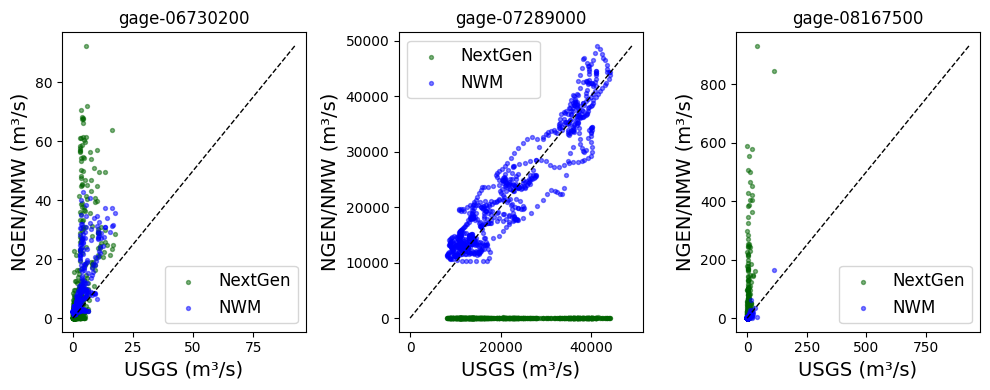

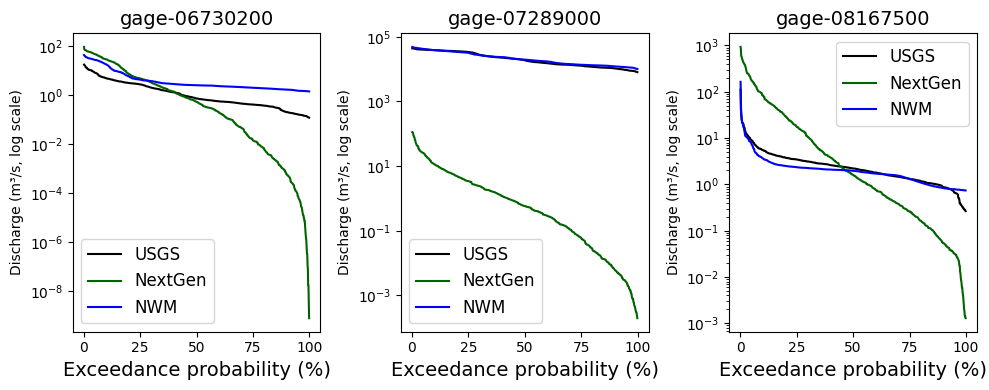

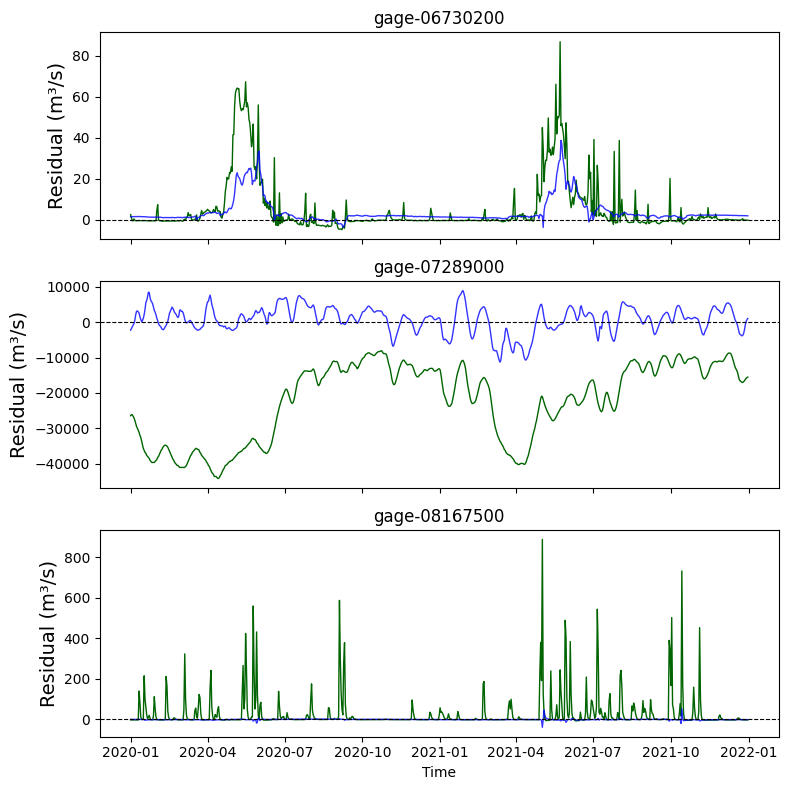

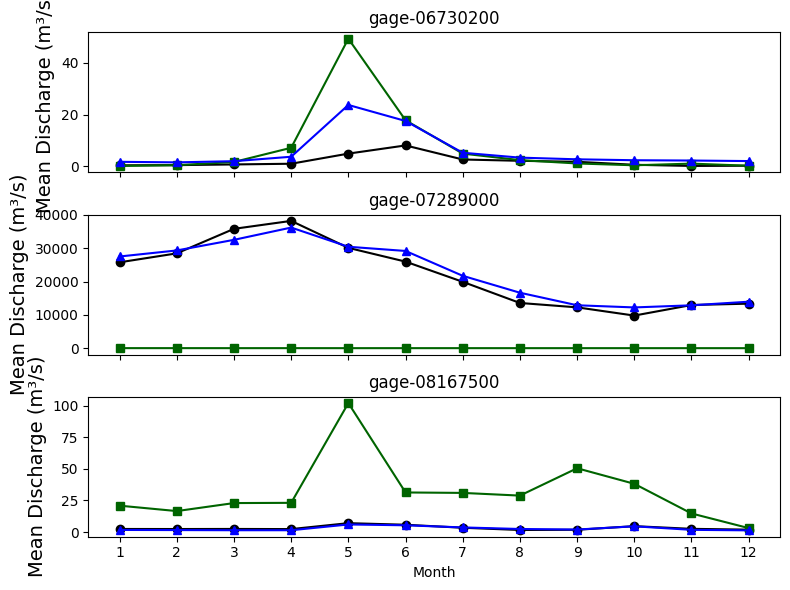

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

common_gages = ['06730200', '07289000', '08167500']
START = '2020-01-01'
END = '2021-12-31'

# ---------------------------------------------------------------
# 1. Performance metrics
# ---------------------------------------------------------------
def nse(obs, sim):
    obs, sim = obs.align(sim, join='inner')
    mask = obs.notna() & sim.notna()
    obs, sim = obs[mask], sim[mask]
    return 1 - np.sum((obs - sim)**2) / np.sum((obs - obs.mean())**2)

def kge(obs, sim):
    obs, sim = obs.align(sim, join='inner')
    mask = obs.notna() & sim.notna()
    obs, sim = obs[mask], sim[mask]
    r = np.corrcoef(obs, sim)[0, 1]
    alpha = sim.std() / obs.std()
    beta = sim.mean() / obs.mean()
    return 1 - np.sqrt((r-1)**2 + (alpha-1)**2 + (beta-1)**2)

def pbias(obs, sim):
    obs, sim = obs.align(sim, join='inner')
    mask = obs.notna() & sim.notna()
    obs, sim = obs[mask], sim[mask]
    return 100 * np.sum(sim - obs) / np.sum(obs)

def rmse(obs, sim):
    obs, sim = obs.align(sim, join='inner')
    mask = obs.notna() & sim.notna()
    obs, sim = obs[mask], sim[mask]
    return np.sqrt(np.mean((sim - obs)**2))

def correlation(obs, sim):
    obs, sim = obs.align(sim, join='inner')
    mask = obs.notna() & sim.notna()
    obs, sim = obs[mask], sim[mask]
    return np.corrcoef(obs, sim)[0, 1]

metrics_rows = []
for gage in common_gages:
    usgs_s = USGS_CONUS[gage].loc[START:END]
    ngen_s = NGEN_CONUS_Simulated[gage].loc[START:END]
    nwm_s = NWM_CONUS_Retrospect_2000_2022_daily[gage].loc[START:END]

    for model_name, sim_s in [('NextGen', ngen_s), ('NWM', nwm_s)]:
        metrics_rows.append({
            'gage': gage,
            'model': model_name,
            'NSE': nse(usgs_s, sim_s),
            'KGE': kge(usgs_s, sim_s),
            'PBIAS (%)': pbias(usgs_s, sim_s),
            'RMSE': rmse(usgs_s, sim_s),
            'Correlation': correlation(usgs_s, sim_s)
        })

metrics_df = pd.DataFrame(metrics_rows)
print(metrics_df.to_string(index=False))
metrics_df.to_csv('/scratch/hdagne1/Docker/Notebook/performance_metrics.csv', index=False)

# ---------------------------------------------------------------
# 2. Scatter plots: observed vs simulated (1:1 line)
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(10, 4))

for i, gage in enumerate(common_gages):
    ax = axes[i]
    usgs_s = USGS_CONUS[gage].loc[START:END]
    ngen_s = NGEN_CONUS_Simulated[gage].loc[START:END]
    nwm_s = NWM_CONUS_Retrospect_2000_2022_daily[gage].loc[START:END]

    ax.scatter(usgs_s, ngen_s.reindex(usgs_s.index), s=8, alpha=0.5, color='darkgreen', label='NextGen')
    ax.scatter(usgs_s, nwm_s.reindex(usgs_s.index), s=8, alpha=0.5, color='blue', label='NWM')

    max_val = max(usgs_s.max(), ngen_s.max(), nwm_s.max())
    ax.plot([0, max_val], [0, max_val], 'k--', linewidth=1)

    ax.set_xlabel('USGS (m³/s)', fontsize=14)
    ax.set_ylabel('NGEN/NMW (m³/s)', fontsize=14)
    ax.set_title(f'gage-{gage}')
    ax.legend(fontsize=12, ncols=1)

plt.tight_layout()
plt.savefig('/scratch/hdagne1/Docker/Notebook/scatter_obs_vs_sim.png', dpi=150, bbox_inches='tight')
print("Saved scatter plots")

# ---------------------------------------------------------------
# 3. Flow duration curves (log-scale, sorted exceedance)
# ---------------------------------------------------------------
def flow_duration_curve(series):
    sorted_vals = series.dropna().sort_values(ascending=False).values
    exceedance = np.arange(1, len(sorted_vals) + 1) / (len(sorted_vals) + 1) * 100
    return exceedance, sorted_vals

fig, axes = plt.subplots(1, 3, figsize=(10, 4))

for i, gage in enumerate(common_gages):
    ax = axes[i]
    usgs_s = USGS_CONUS[gage].loc[START:END]
    ngen_s = NGEN_CONUS_Simulated[gage].loc[START:END]
    nwm_s = NWM_CONUS_Retrospect_2000_2022_daily[gage].loc[START:END]

    for label, series, color in [('USGS', usgs_s, 'black'), ('NextGen', ngen_s, 'darkgreen'), ('NWM', nwm_s, 'blue')]:
        exc, vals = flow_duration_curve(series)
        ax.plot(exc, vals, label=label, color=color, linewidth=1.5)

    ax.set_yscale('log')
    ax.set_xlabel('Exceedance probability (%)', fontsize=14)
    ax.set_ylabel('Discharge (m³/s, log scale)')
    ax.set_title(f'gage-{gage}', fontsize=14)
    ax.legend(fontsize=12, ncols=1)

plt.tight_layout()
plt.savefig('/scratch/hdagne1/Docker/Notebook/flow_duration_curves.png', dpi=150, bbox_inches='tight')
print("Saved flow duration curves")

# ---------------------------------------------------------------
# 4. Residuals over time (sim - obs)
# ---------------------------------------------------------------
fig, axes = plt.subplots(3, 1, figsize=(8, 8), sharex=True)

for i, gage in enumerate(common_gages):
    ax = axes[i]
    usgs_s = USGS_CONUS[gage].loc[START:END]
    ngen_s = NGEN_CONUS_Simulated[gage].loc[START:END].reindex(usgs_s.index)
    nwm_s = NWM_CONUS_Retrospect_2000_2022_daily[gage].loc[START:END].reindex(usgs_s.index)

    ax.plot(usgs_s.index, ngen_s - usgs_s, label='NextGen - USGS', color='darkgreen', linewidth=1)
    ax.plot(usgs_s.index, nwm_s - usgs_s, label='NWM - USGS', color='blue', linewidth=1, alpha=0.8)
    ax.axhline(0, color='black', linewidth=0.8, linestyle='--')

    ax.set_ylabel('Residual (m³/s)', fontsize=14)
    ax.set_title(f'gage-{gage}')
    # ax.legend(fontsize=12, ncols=2)

axes[-1].set_xlabel('Time')
plt.tight_layout()
plt.savefig('/scratch/hdagne1/Docker/Notebook/residuals_over_time.png', dpi=150, bbox_inches='tight')
print("Saved residual plots")

# ---------------------------------------------------------------
# 5. Monthly boxplot comparison (seasonal performance)
# ---------------------------------------------------------------
fig, axes = plt.subplots(3, 1, figsize=(8, 6), sharex=True)

for i, gage in enumerate(common_gages):
    ax = axes[i]
    usgs_s = USGS_CONUS[gage].loc[START:END]
    ngen_s = NGEN_CONUS_Simulated[gage].loc[START:END].reindex(usgs_s.index)
    nwm_s = NWM_CONUS_Retrospect_2000_2022_daily[gage].loc[START:END].reindex(usgs_s.index)

    monthly_df = pd.DataFrame({
        'month': usgs_s.index.month,
        'USGS': usgs_s.values,
        'NextGen': ngen_s.values,
        'NWM': nwm_s.values
    })
    monthly_means = monthly_df.groupby('month').mean()

    ax.plot(monthly_means.index, monthly_means['USGS'], label='USGS', color='black', marker='o')
    ax.plot(monthly_means.index, monthly_means['NextGen'], label='NextGen', color='darkgreen', marker='s')
    ax.plot(monthly_means.index, monthly_means['NWM'], label='NWM', color='blue', marker='^')

    ax.set_ylabel('Mean Discharge (m³/s)', fontsize=14)
    ax.set_title(f'gage-{gage}')
    ax.set_xticks(range(1, 13))
    # ax.legend(fontsize=12, ncols=1)

axes[-1].set_xlabel('Month')
plt.tight_layout()
plt.savefig('/scratch/hdagne1/Docker/Notebook/monthly_seasonal_comparison.png', dpi=150, bbox_inches='tight')
print("Saved monthly seasonal comparison")

# Neuralhydrology vs NeuralNGEN:

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

nh = pd.read_csv(
    "/scratch/hdagne1/Docker/neuralhydrology/runs/nh_aorc_full8_elev_88basin_1508_190532/test/model_epoch005/test_metrics.csv",
    dtype={"basin": str}
)
ngen = pd.read_csv(
    "/scratch/hdagne1/Docker/NeuralNGEN/runs/persistent_88basin/test_metrics_neuralngen.csv",
    dtype={"basin": str}
)

fig, axes = plt.subplots(1, 2, figsize=(8, 5))
labels = ["neuralhydrology", "NeuralNGEN"]
colors = ["#B04C9F", "#52DD67"]

for ax, metric in zip(axes, ["NSE", "KGE"]):
    data = [nh[metric].dropna(), ngen[metric].dropna()]
    bp = ax.boxplot(data, labels=labels)

    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_title(metric)
    ax.grid(axis="y", alpha=0.3)
    ax.set_ylim(-0.5, 1)

# plt.suptitle("Test-period NSE / KGE: neuralhydrology vs NeuralNGEN (88 basins)")
plt.tight_layout()
# plt.savefig("metrics_boxplot_comparison.png", dpi=150)
plt.show()

# print("=== neuralhydrology ===")
# print(nh[["NSE", "KGE"]].describe())
# print("\n=== NeuralNGEN ===")
# print(ngen[["NSE", "KGE"]].describe())

In [ ]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

nh = pd.read_csv(
    "/scratch/hdagne1/Docker/neuralhydrology/runs/nh_aorc_full8_elev_88basin_1508_190532/test/model_epoch005/test_metrics.csv",
    dtype={"basin": str}
)
with open(
    "/scratch/hdagne1/Docker/neuralhydrology/runs/nh_aorc_full8_elev_88basin_1508_190532/test/model_epoch005/test_results.p",
    "rb"
) as f:
    nh_results = pickle.load(f)
with open(
    "/scratch/hdagne1/Docker/NeuralNGEN/runs/persistent_88basin/test_predictions_neuralngen.p",
    "rb"
) as f:
    ngen_preds = pickle.load(f)

freq = list(nh_results[list(nh_results.keys())[0]].keys())[0]
obs_var, sim_var = "QObs(mm/h)_obs", "QObs(mm/h)_sim"

WINDOW_START = "2024-01-01"
WINDOW_END = "2024-05-31"

common_basins = set(nh["basin"]) & set(ngen_preds["preds"].keys()) & set(nh_results.keys())
nh_common = nh[nh["basin"].isin(common_basins)].sort_values("NSE", ascending=False).reset_index(drop=True)
picks = {
    "Best": nh_common.iloc[0],
    "Median": nh_common.iloc[len(nh_common) // 2],
    "Worst": nh_common.iloc[-1],
}

fig, axes = plt.subplots(len(picks), 1, figsize=(13, 11), sharex=False)
for ax, (label, row) in zip(axes, picks.items()):
    basin = row["basin"]

    # neuralhydrology series, restricted to window
    ds = nh_results[basin][freq]["xr"]
    nh_df = pd.DataFrame({
        "date": pd.to_datetime(ds["date"].values),
        "obs": ds[obs_var].values.squeeze(),
        "sim_nh": ds[sim_var].values.squeeze(),
    }).set_index("date")
    nh_df = nh_df.loc[WINDOW_START:WINDOW_END]

    # NeuralNGEN series: flatten, dedup by date (filler can repeat samples), restrict to window
    ngen_dates = pd.to_datetime(np.concatenate(ngen_preds["dates"][basin]))
    ngen_sim = np.concatenate(ngen_preds["preds"][basin])
    ngen_df = pd.DataFrame({"date": ngen_dates, "sim_ngen": ngen_sim})
    ngen_df = ngen_df.drop_duplicates(subset="date").set_index("date").sort_index()
    ngen_df = ngen_df.loc[WINDOW_START:WINDOW_END]

    # one shared date axis
    ax.plot(nh_df.index, nh_df["obs"], color="green", linewidth=1.5, label="Observed")
    ax.plot(nh_df.index, nh_df["sim_nh"], color="#090DE6", linewidth=2.5, alpha=0.85, label="neuralhydrology")
    ax.plot(ngen_df.index, ngen_df["sim_ngen"], color="#DD8452", linewidth=2.5, alpha=0.85, label="NeuralNGEN")

    ax.set_title(f"{label} basin {basin}  (neuralhydrology NSE={row['NSE']:.3f})")
    ax.set_ylabel("QObs (mm/h)")
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Date")
plt.tight_layout()
# plt.savefig("hydrographs_comparison.png", dpi=150)
plt.show()

# Upstream contributing catchments vs Outlet:
# "Contributing subcatchment correlation with USGS outlet streamflow, as a function of drainage area and static physical attributes (elevation, slope, vegetation productivity)

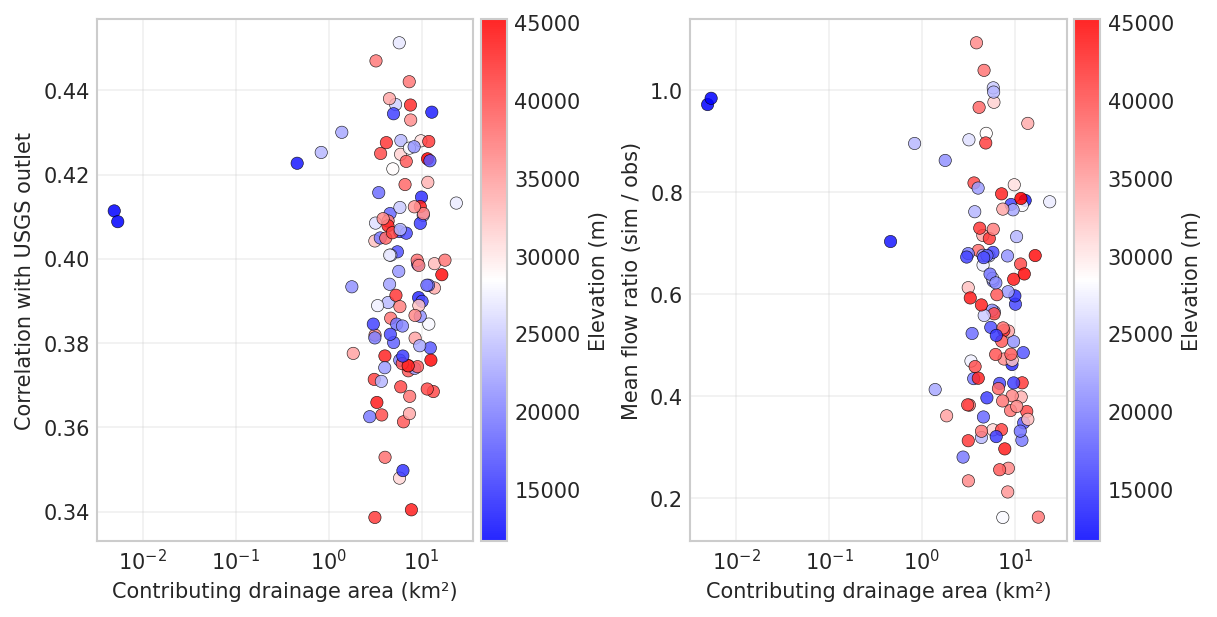

In [ ]:
import sys
import sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

sys.path.insert(0, "/scratch/hdagne1/Docker/NeuralNGEN")
from src.dataset.multi_gauge_batcher import GaugeHandle
from src.models.catchment_lstm import CatchmentLSTM

GAUGE_ID = "01031500"
SCENARIO = "fdc"
TEST_START = "2022-01-01"

GAUGES_ROOT = "/scratch/hdagne1/Docker/Data/CAMELS_US_ngiab_full"
STREAMFLOW_DIR = "/scratch/hdagne1/Docker/Data/CAMELS_US/hourly/usgs_streamflow"

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# ---------- Load checkpoint first -- it carries its own training config
# (dynamic_inputs, static_attributes, in the exact order the model expects) ----------
ckpt_path = Path(f"/scratch/hdagne1/Docker/NeuralNGEN/runs/scoring_rule_multi_{SCENARIO}/model_final.pt")
ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
train_cfg = ckpt["config"]
dynamic_inputs = train_cfg["dynamic_inputs"]
static_attributes = train_cfg["static_attributes"]

# ---------- Forcings, static attributes, catchment IDs, time index (current loader) ----------
handle = GaugeHandle(GAUGE_ID, GAUGES_ROOT, STREAMFLOW_DIR, dynamic_inputs, static_attributes)
cids = handle.catchment_ids
time_index = handle.time_index
n_catchments = handle.n_catchments

test_mask = time_index >= pd.Timestamp(TEST_START)
test_idx = np.where(test_mask)[0]

# full dynamic array for the test period (via lazy window read, whole test span at once)
dyn_full, _ = handle.get_window(int(test_idx.min()), int(test_idx.max()) + 1)  # (n_catchments, T_test, n_dyn)

# ---------- USGS observed streamflow, test period ----------
obs_test = handle.q_obs.values[test_idx]

# ---------- Run inference over the test period ----------
dyn_norm = (dyn_full - ckpt["dyn_mean"]) / ckpt["dyn_std"]
stat_norm = (handle.static - ckpt["stat_mean"]) / ckpt["stat_std"]

model = CatchmentLSTM(
    dynamic_size=len(dynamic_inputs), static_size=len(static_attributes),
    hidden_size=train_cfg.get("hidden_size", 64), num_layers=train_cfg.get("num_layers", 2),
)
model.load_state_dict(ckpt["model_state"])
model.to(device)
model.eval()

dyn_t = torch.tensor(dyn_norm, dtype=torch.float32, device=device)
stat_t = torch.tensor(stat_norm, dtype=torch.float32, device=device)

chunk_size = 2000
preds_chunks = []
with torch.no_grad():
    for start in range(0, dyn_t.shape[1], chunk_size):
        end = min(start + chunk_size, dyn_t.shape[1])
        pred_chunk = model(dyn_t[:, start:end, :], stat_t)
        preds_chunks.append(pred_chunk.cpu().numpy())
pred_norm = np.concatenate(preds_chunks, axis=1)  # (n_catchments, T_test)

# de-normalize using THIS gauge's own q_stats (per-gauge dict in the multi-gauge checkpoint)
q_mean, q_std = ckpt["q_stats"][GAUGE_ID]
pred_physical = pred_norm * q_std + q_mean

# ---------- Per-catchment area (via sqlite3 -- NOT geopandas, which crashes on
# geometry-bearing layers like 'divides' in this environment) ----------
gauge_root = Path(GAUGES_ROOT) / f"gage-{GAUGE_ID}"
gpkg_path = next((gauge_root / "config").glob("*_subset.gpkg"))
conn = sqlite3.connect(str(gpkg_path))
cur = conn.cursor()
cur.execute("SELECT divide_id, areasqkm FROM divides")
area_lookup = {row[0]: row[1] for row in cur.fetchall()}
conn.close()
areas = np.array([area_lookup.get(cid, np.nan) for cid in cids])

elev_idx = static_attributes.index("mean.elevation")
elevation = handle.static[:, elev_idx]

# ---------- Per-catchment diagnostic metrics vs the USGS outlet series ----------
correlations = np.full(n_catchments, np.nan)
mean_ratios = np.full(n_catchments, np.nan)

obs_series = obs_test.copy()
obs_mask_full = ~np.isnan(obs_series)

for i in range(n_catchments):
    sim = pred_physical[i, :]
    mask = obs_mask_full & ~np.isnan(sim)
    if mask.sum() < 100:
        continue

    sim_valid = sim[mask]
    obs_valid_i = obs_series[mask]

    if np.std(sim_valid) > 0 and np.std(obs_valid_i) > 0:
        correlations[i] = np.corrcoef(sim_valid, obs_valid_i)[0, 1]

    if np.nanmean(obs_valid_i) != 0:
        mean_ratios[i] = np.nanmean(sim_valid) / np.nanmean(obs_valid_i)

# ---------- 1x2 diagnostic panel ----------
fig, axes = plt.subplots(1, 2, figsize=(8, 4), dpi=150, constrained_layout=True)

panels = [
    (axes[0], correlations, "Correlation with USGS outlet", elevation, "Elevation (m)"),
    (axes[1], mean_ratios, "Mean flow ratio (sim / obs)", elevation, "Elevation (m)"),
]

for ax, y, ylabel, color_by, color_label in panels:
    valid = ~np.isnan(y) & ~np.isnan(areas)
    sc = ax.scatter(areas[valid], y[valid], c=color_by[valid], cmap="bwr", s=35,
                     edgecolor="k", linewidth=0.3, alpha=0.85)
    ax.set_xlabel("Contributing drainage area (km²)")
    ax.set_ylabel(ylabel)
    ax.set_xscale("log")
    ax.grid(alpha=0.3)
    fig.colorbar(sc, ax=ax, label=color_label, pad=0.02)

# plt.savefig("catchment_outlet_relationship_diagnostics.png", dpi=150)
plt.show()

mean.elevation: min=11697.000000, max=45220.730469
mean.slope: min=61.903297, max=85.116600
mode.Expon: min=1.000000, max=7.000000


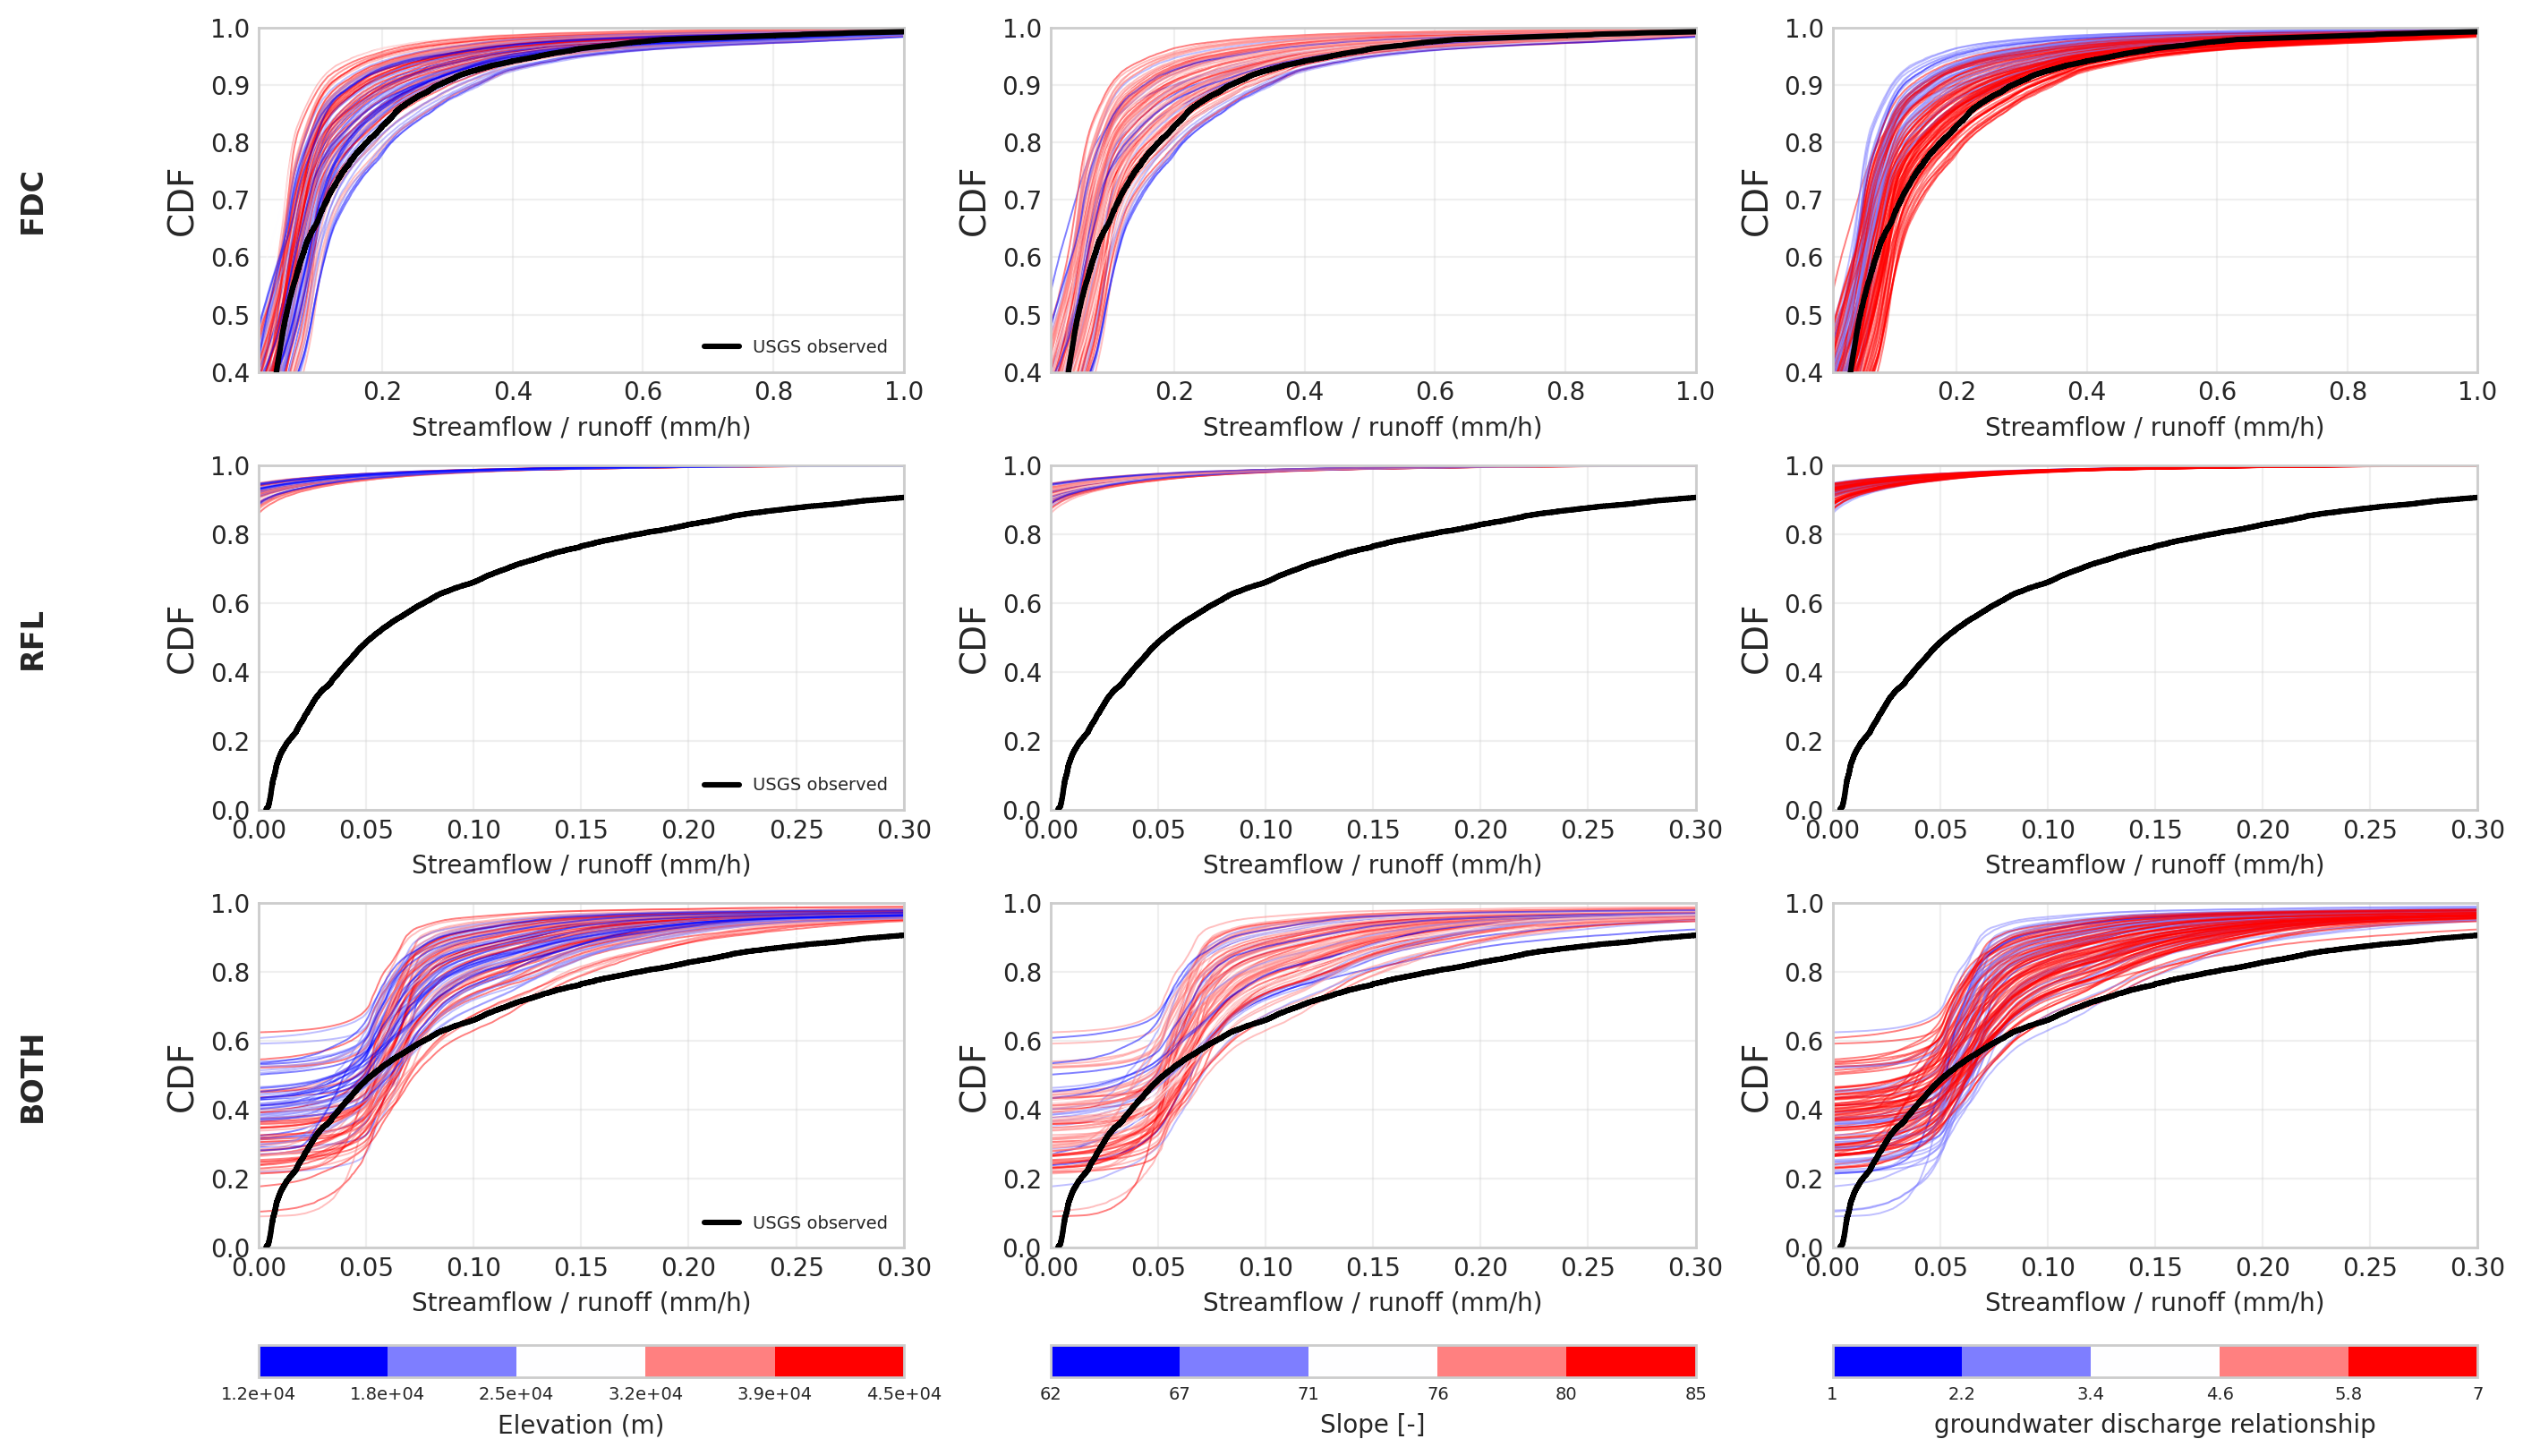

In [ ]:
import sys
import sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker

sys.path.insert(0, "/scratch/hdagne1/Docker/NeuralNGEN")
from src.dataset.multi_gauge_batcher import GaugeHandle
from src.models.catchment_lstm import CatchmentLSTM

try:
    from mintpy.objects.colors import ColormapExt
    cmap = ColormapExt("bwr").colormap
except ImportError:
    print("mintpy not available, falling back to standard 'bwr' colormap")
    cmap = plt.get_cmap("bwr")

GAUGE_ID = "01031500"
SCENARIOS = ["fdc", "rfl", "both"]
ATTRIBUTES = ["mean.elevation", "mean.slope", "mode.Expon"]
ATTRIBUTE_LABELS = ["Elevation (m)", "Slope [-]", "groundwater discharge relationship"]
TEST_START = "2022-01-01"

GAUGES_ROOT = "/scratch/hdagne1/Docker/Data/CAMELS_US_ngiab_full"
STREAMFLOW_DIR = "/scratch/hdagne1/Docker/Data/CAMELS_US/hourly/usgs_streamflow"

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# ---------- Load one checkpoint just to get dynamic_inputs/static_attributes
# (all three scenarios were trained with the same feature set/order) ----------
ref_ckpt = torch.load(f"/scratch/hdagne1/Docker/NeuralNGEN/runs/scoring_rule_multi_fdc/model_final.pt",
                       map_location=device, weights_only=False)
train_cfg = ref_ckpt["config"]
dynamic_inputs = train_cfg["dynamic_inputs"]
static_attributes = train_cfg["static_attributes"]

# ---------- Forcings, static attributes, catchment IDs, time index (same for all scenarios) ----------
handle = GaugeHandle(GAUGE_ID, GAUGES_ROOT, STREAMFLOW_DIR, dynamic_inputs, static_attributes)
cids = handle.catchment_ids
time_index = handle.time_index
n_catchments = handle.n_catchments
stat = handle.static

test_mask = time_index >= pd.Timestamp(TEST_START)
test_idx = np.where(test_mask)[0]
dyn_full, _ = handle.get_window(int(test_idx.min()), int(test_idx.max()) + 1)

# ---------- Discrete (interval-based) bin edges per color-by variable ----------
def make_boundary_norm(values, n_bins=5):
    vmin, vmax = np.nanmin(values), np.nanmax(values)
    if vmin == vmax:
        pad = 0.5 if vmin == 0 else abs(vmin) * 0.05
        vmin, vmax = vmin - pad, vmax + pad
    edges = np.linspace(vmin, vmax, n_bins + 1)
    return mcolors.BoundaryNorm(edges, cmap.N)

# ---------- Color-by attribute arrays + interval-based norms, computed once ----------
attribute_arrays = [stat[:, static_attributes.index(a)] for a in ATTRIBUTES]
for arr, name in zip(attribute_arrays, ATTRIBUTES):
    print(f"{name}: min={np.nanmin(arr):.6f}, max={np.nanmax(arr):.6f}")
attribute_norms = [make_boundary_norm(a) for a in attribute_arrays]

# ---------- USGS observed streamflow, test period (same for all scenarios) ----------
obs_test = handle.q_obs.values[test_idx]
obs_valid = obs_test[~np.isnan(obs_test)]
obs_sorted = np.sort(obs_valid)
obs_cdf = np.arange(1, obs_sorted.size + 1) / obs_sorted.size

# ---------- Plot: 3 rows (scenarios) x 3 cols (attributes), CDF only ----------
fig, axes = plt.subplots(3, 3, figsize=(14, 8), dpi=200, constrained_layout=True)

for row, scenario in enumerate(SCENARIOS):
    ckpt_path = Path(f"/scratch/hdagne1/Docker/NeuralNGEN/runs/scoring_rule_multi_{scenario}/model_final.pt")
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)

    dyn_norm = (dyn_full - ckpt["dyn_mean"]) / ckpt["dyn_std"]
    stat_norm = (stat - ckpt["stat_mean"]) / ckpt["stat_std"]

    model = CatchmentLSTM(
        dynamic_size=len(dynamic_inputs), static_size=len(static_attributes),
        hidden_size=ckpt["config"].get("hidden_size", 64), num_layers=ckpt["config"].get("num_layers", 2),
    )
    model.load_state_dict(ckpt["model_state"])
    model.to(device)
    model.eval()

    dyn_t = torch.tensor(dyn_norm, dtype=torch.float32, device=device)
    stat_t = torch.tensor(stat_norm, dtype=torch.float32, device=device)

    chunk_size = 2000
    preds_chunks = []
    with torch.no_grad():
        for start in range(0, dyn_t.shape[1], chunk_size):
            end = min(start + chunk_size, dyn_t.shape[1])
            pred_chunk = model(dyn_t[:, start:end, :], stat_t)
            preds_chunks.append(pred_chunk.cpu().numpy())
    pred_norm = np.concatenate(preds_chunks, axis=1)  # (G, n_test_time)

    q_mean, q_std = ckpt["q_stats"][GAUGE_ID]
    pred_physical = pred_norm * q_std + q_mean

    all_finite = pred_physical[np.isfinite(pred_physical)]
    pooled = np.concatenate([all_finite, obs_valid])
    xmin, xmax = np.nanmin(pooled), np.nanmax(pooled)
    xpad = (xmax - xmin) * 0.02 if xmax > xmin else 0.1

    catchment_cdfs = []
    for i in range(n_catchments):
        vals = pred_physical[i, :]
        vals = vals[~np.isnan(vals)]
        if vals.size == 0:
            catchment_cdfs.append(None)
            continue
        vals_sorted = np.sort(vals)
        cdf = np.arange(1, vals_sorted.size + 1) / vals_sorted.size
        catchment_cdfs.append((vals_sorted, cdf))

    for col, (color_by, color_label, norm) in enumerate(zip(attribute_arrays, ATTRIBUTE_LABELS, attribute_norms)):
        ax = axes[row, col]

        for i in range(n_catchments):
            if catchment_cdfs[i] is None:
                continue
            vals_sorted, cdf = catchment_cdfs[i]
            color = cmap(norm(color_by[i]))
            ax.plot(vals_sorted, cdf, color=color, linewidth=0.7, alpha=0.5)

        ax.plot(obs_sorted, obs_cdf, color="black", linewidth=2.2, label="USGS observed", zorder=10)
        ax.set_xlabel("Streamflow / runoff (mm/h)")
        ax.set_ylabel("CDF", fontsize=14)
        ax.grid(alpha=0.3)
        ax.set_xlim(xmin - xpad, xmax + xpad)
        if col == 0:
            ax.legend(loc="lower right", fontsize=7)

        row_xlims = {0: (0.01, 1.0), 1: (0, 0.3), 2: (0, 0.3)}
        row_ylims = {0: (0.4, 1), 1: (0, 1), 2: (0, 1)}
        ax.set_xlim(*row_xlims[row])
        ax.set_ylim(*row_ylims[row])

        if row == len(SCENARIOS) - 1:
            sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
            sm.set_array([])
            cbar = fig.colorbar(sm, ax=axes[:, col], label=color_label, pad=0.02, orientation="horizontal")
            cbar.ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.2g}"))
            cbar.ax.tick_params(labelsize=7)

for row, scenario in enumerate(SCENARIOS):
    axes[row, 0].annotate(scenario.upper(), xy=(-0.35, 0.5), xycoords="axes fraction",
                           fontsize=12, fontweight="bold", ha="center", va="center", rotation=90)

# plt.savefig("scenario_attribute_grid_cdf.png", dpi=150)
plt.show()

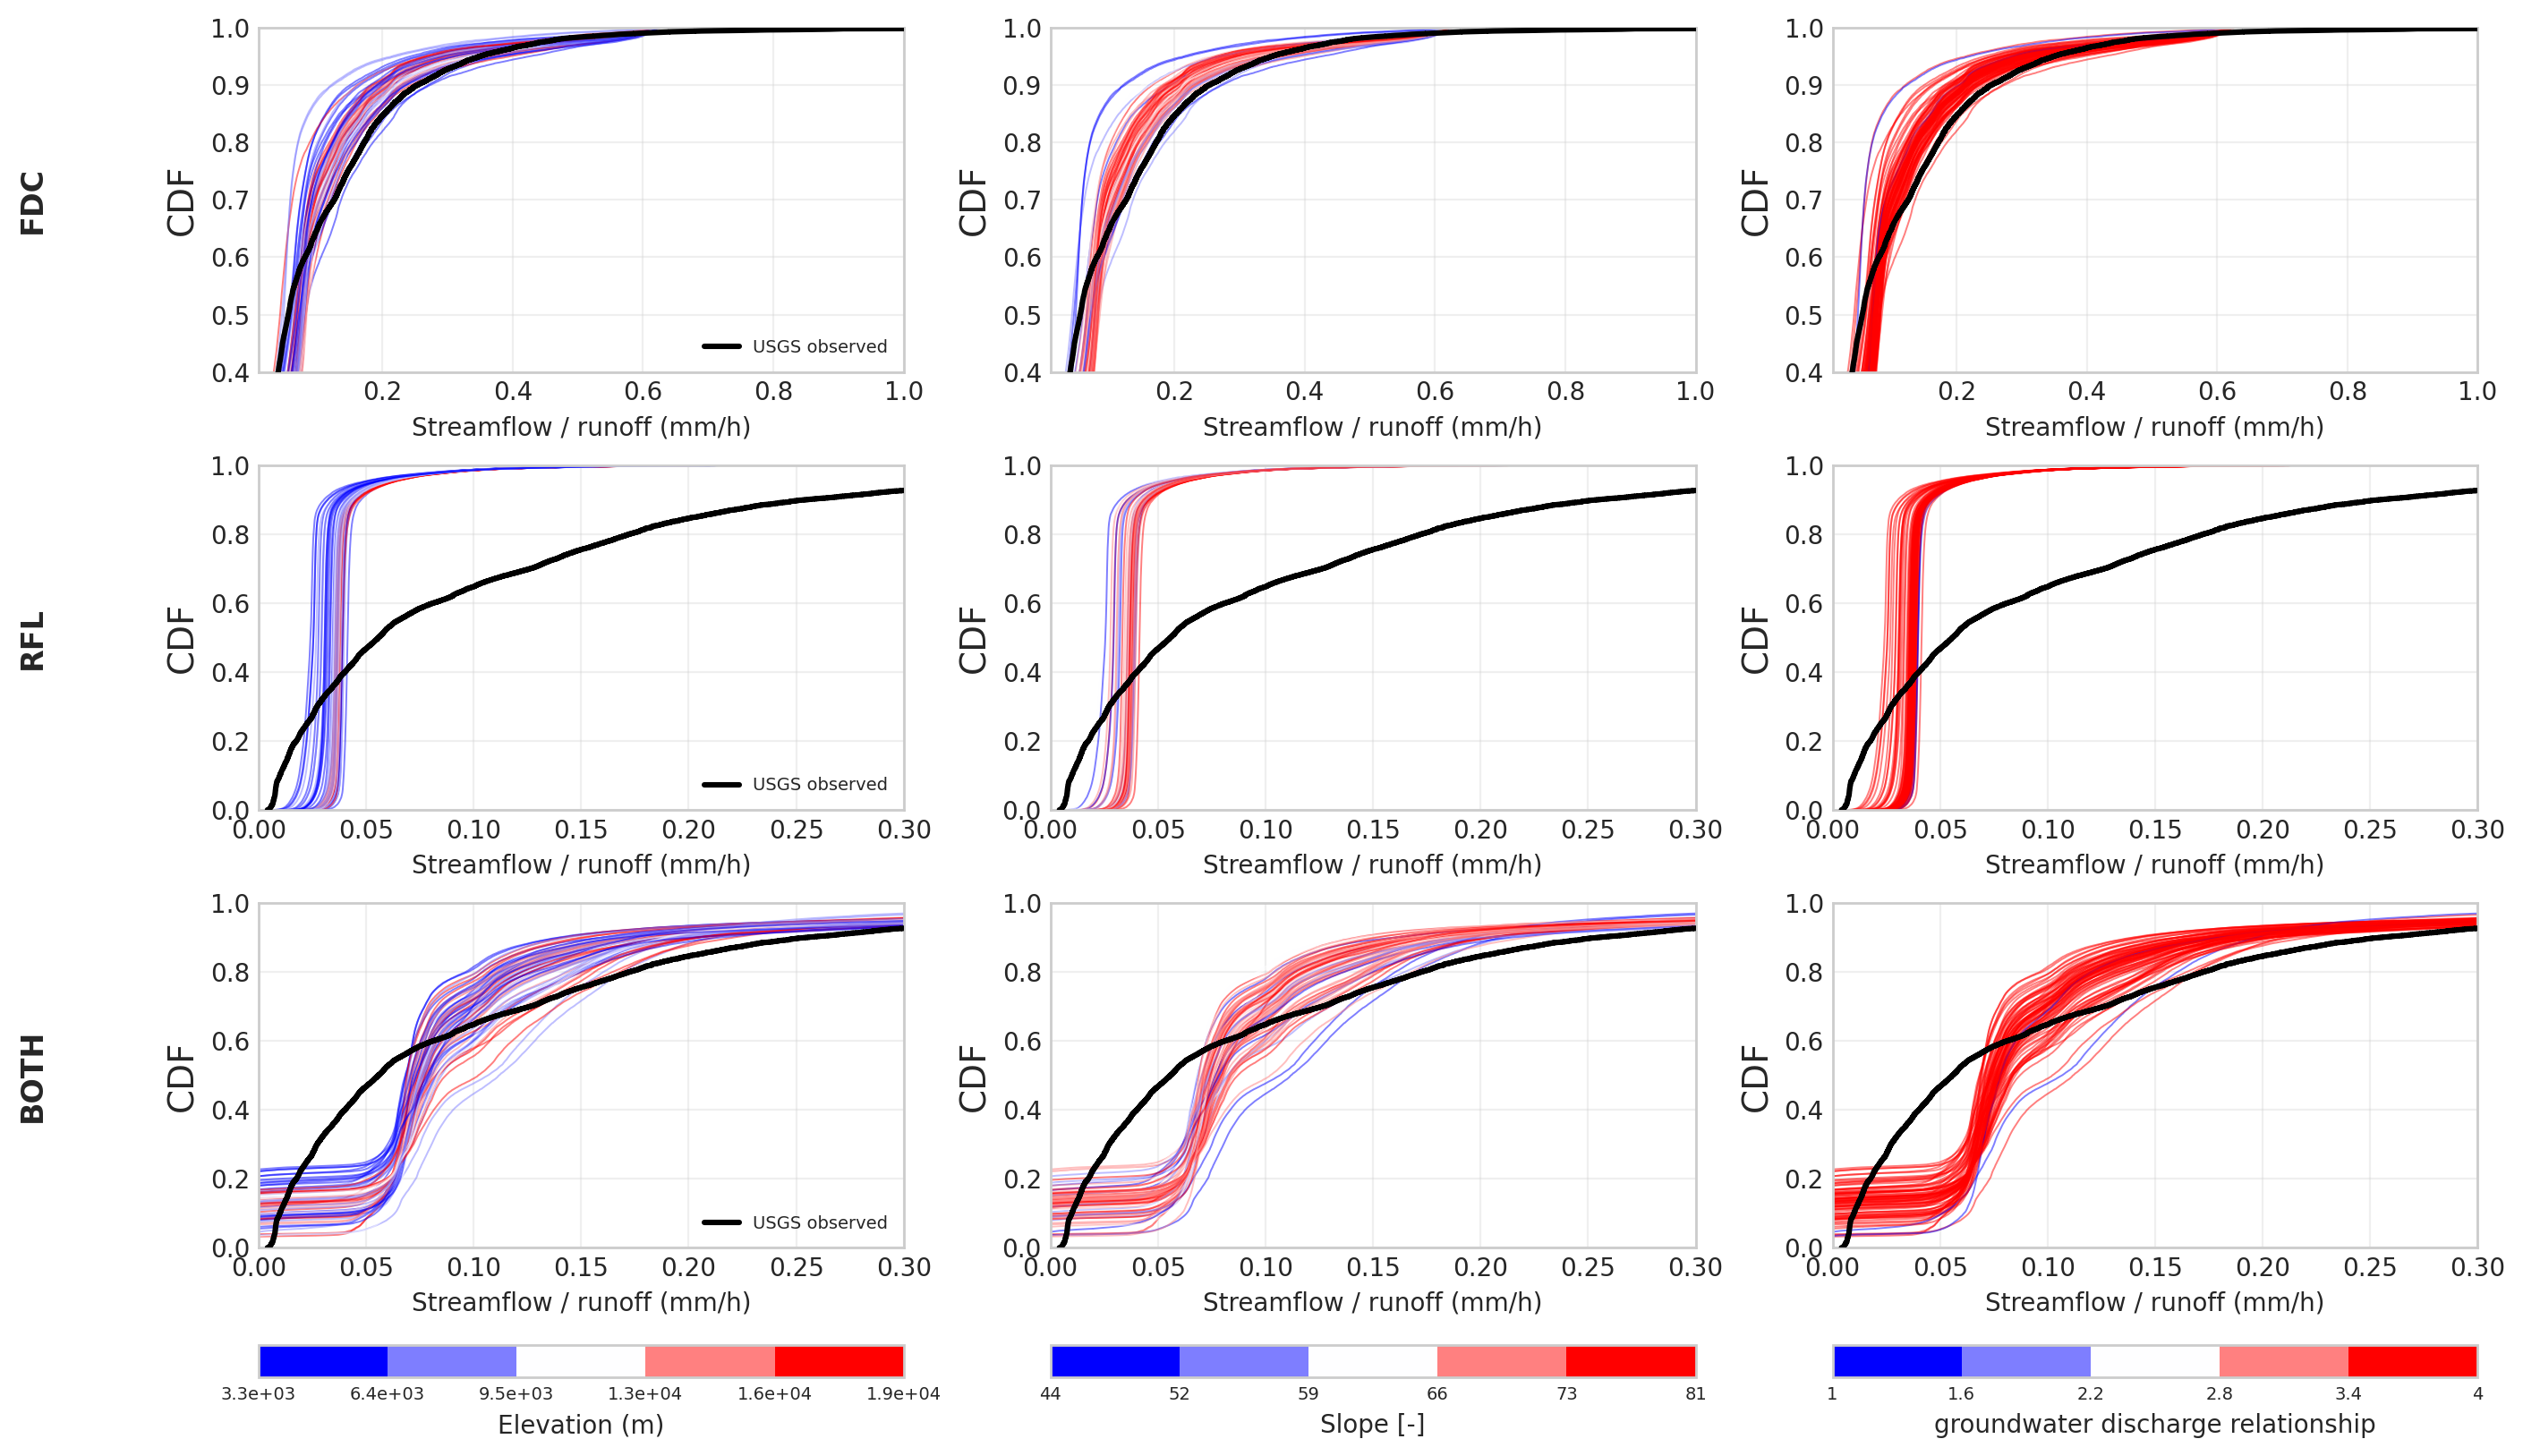

In [ ]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker
from mintpy.objects.colors import ColormapExt

sys.path.insert(0, "/scratch/hdagne1/Docker/NeuralNGEN")
from src.dataset.gauge_catchment_dataset import build_gauge_dataset
from src.models.catchment_lstm import CatchmentLSTM

GAUGE_ID = "01022500"
SCENARIOS = ["fdc", "rfl", "both"]  # matches actual checkpoint dirs: runs/scoring_rule_multi_{scenario}
ATTRIBUTES = ["mean.elevation", "mean.slope", "mode.Expon"]
ATTRIBUTE_LABELS = ["Elevation (m)", "Slope [-]", "groundwater discharge relationship"]
TEST_START = "2022-01-01"

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

gauge_root = Path(f"/scratch/hdagne1/Docker/Data/CAMELS_US_ngiab_full/gage-{GAUGE_ID}")

# ---------- Load GMT colormap ----------
cmap_obj = ColormapExt('bwr')
cmap = cmap_obj.colormap


def make_boundary_norm(values, n_bins=5):
    vmin, vmax = np.nanmin(values), np.nanmax(values)
    if vmin == vmax:
        pad = 0.5 if vmin == 0 else abs(vmin) * 0.05
        vmin, vmax = vmin - pad, vmax + pad
    edges = np.linspace(vmin, vmax, n_bins + 1)
    return mcolors.BoundaryNorm(edges, cmap.N)


# ---------- USGS observed streamflow, test period (same for all scenarios) ----------
q_path = Path(f"/scratch/hdagne1/Docker/Data/CAMELS_US/hourly/usgs_streamflow/{GAUGE_ID}-usgs-hourly.csv")
q_obs_full = pd.read_csv(q_path, parse_dates=["date"]).set_index("date")["QObs(mm/h)"]

fig, axes = plt.subplots(3, 3, figsize=(14, 8), dpi=200, constrained_layout=True)

for row, scenario in enumerate(SCENARIOS):
    ckpt_path = Path(f"/scratch/hdagne1/Docker/NeuralNGEN/runs/scoring_rule_multi_{scenario}/model_final.pt")
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
    train_cfg = ckpt["config"]

    # each checkpoint carries its own dynamic_inputs/static_attributes -- build
    # per-scenario rather than assuming a fixed shared list (real risk tonight:
    # scenarios can genuinely have different attribute counts if retrained
    # inconsistently, so don't assume they match)
    dyn, stat, cids, time_index = build_gauge_dataset(
        gauge_root, train_cfg["dynamic_inputs"], train_cfg["static_attributes"]
    )
    n_catchments, n_time, n_dyn = dyn.shape

    missing_attrs = [a for a in ATTRIBUTES if a not in train_cfg["static_attributes"]]
    if missing_attrs:
        print(f"WARNING: scenario={scenario} checkpoint is missing attributes {missing_attrs} "
              f"(this checkpoint's static_attributes: {train_cfg['static_attributes']}). Skipping row.")
        for col in range(3):
            axes[row, col].set_visible(False)
        continue

    test_mask = time_index >= pd.Timestamp(TEST_START)
    test_idx = np.where(test_mask)[0]

    q_obs = q_obs_full.reindex(time_index)
    obs_test = q_obs.values[test_idx]
    obs_valid = obs_test[~np.isnan(obs_test)]
    obs_sorted = np.sort(obs_valid)
    obs_cdf = np.arange(1, obs_sorted.size + 1) / obs_sorted.size

    attribute_arrays = [stat[:, train_cfg["static_attributes"].index(a)] for a in ATTRIBUTES]
    attribute_norms = [make_boundary_norm(a) for a in attribute_arrays]

    dyn_norm = (dyn - ckpt["dyn_mean"]) / ckpt["dyn_std"]
    stat_norm = (stat - ckpt["stat_mean"]) / ckpt["stat_std"]

    model = CatchmentLSTM(
        dynamic_size=n_dyn, static_size=stat.shape[1],
        hidden_size=train_cfg.get("hidden_size", 64), num_layers=train_cfg.get("num_layers", 2),
    )
    model.load_state_dict(ckpt["model_state"])
    model.to(device)
    model.eval()

    dyn_t = torch.tensor(dyn_norm[:, test_idx, :], dtype=torch.float32, device=device)
    stat_t = torch.tensor(stat_norm, dtype=torch.float32, device=device)

    chunk_size = 2000
    preds_chunks = []
    with torch.no_grad():
        for start in range(0, dyn_t.shape[1], chunk_size):
            end = min(start + chunk_size, dyn_t.shape[1])
            pred_chunk = model(dyn_t[:, start:end, :], stat_t)
            preds_chunks.append(pred_chunk.cpu().numpy())
    pred_norm = np.concatenate(preds_chunks, axis=1)
    q_mean, q_std = ckpt["q_stats"][GAUGE_ID] if isinstance(ckpt["q_stats"], dict) and GAUGE_ID in ckpt["q_stats"] else (ckpt["q_mean"], ckpt["q_std"])
    pred_physical = pred_norm * q_std + q_mean

    all_finite = pred_physical[np.isfinite(pred_physical)]
    pooled = np.concatenate([all_finite, obs_valid])
    xmin, xmax = np.nanmin(pooled), np.nanmax(pooled)
    xpad = (xmax - xmin) * 0.02 if xmax > xmin else 0.1

    catchment_cdfs = []
    for i in range(n_catchments):
        vals = pred_physical[i, :]
        vals = vals[~np.isnan(vals)]
        if vals.size == 0:
            catchment_cdfs.append(None)
            continue
        vals_sorted = np.sort(vals)
        cdf = np.arange(1, vals_sorted.size + 1) / vals_sorted.size
        catchment_cdfs.append((vals_sorted, cdf))

    for col, (color_by, color_label, norm) in enumerate(zip(attribute_arrays, ATTRIBUTE_LABELS, attribute_norms)):
        ax = axes[row, col]

        for i in range(n_catchments):
            if catchment_cdfs[i] is None:
                continue
            vals_sorted, cdf = catchment_cdfs[i]
            color = cmap(norm(color_by[i]))
            ax.plot(vals_sorted, cdf, color=color, linewidth=0.7, alpha=0.5)

        ax.plot(obs_sorted, obs_cdf, color="black", linewidth=2.2, label="USGS observed", zorder=10)
        ax.set_xlabel("Streamflow / runoff (mm/h)")
        ax.set_ylabel("CDF", fontsize=14)
        ax.grid(alpha=0.3)
        ax.set_xlim(xmin - xpad, xmax + xpad)
        if col == 0:
            ax.legend(loc="lower right", fontsize=7)

        row_xlims = {0: (0.01, 1.0), 1: (0, 0.3), 2: (0, 0.3)}
        row_ylims = {0: (0.4, 1), 1: (0, 1), 2: (0, 1)}
        ax.set_xlim(*row_xlims[row])
        ax.set_ylim(*row_ylims[row])

        if row == len(SCENARIOS) - 1:
            sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
            sm.set_array([])
            cbar = fig.colorbar(sm, ax=axes[:, col], label=color_label, pad=0.02, orientation='horizontal')
            cbar.ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.2g}'))
            cbar.ax.tick_params(labelsize=7)

for row, scenario in enumerate(SCENARIOS):
    axes[row, 0].annotate(scenario.upper(), xy=(-0.35, 0.5), xycoords="axes fraction",
                           fontsize=12, fontweight="bold", ha="center", va="center", rotation=90)

# plt.savefig("scenario_attribute_grid_cdf.png", dpi=150)
plt.show()

In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt
# import matplotlib.colors as mcolors
# from mintpy.objects.colors import ColormapExt

# # ---------- Static attribute indices ----------
# elev_idx = static_attributes.index("mean.elevation")
# slope_idx = static_attributes.index("mean.slope")
# vcmx25_idx = static_attributes.index("mean.vcmx25")

# elevation = stat[:, elev_idx]
# slope = stat[:, slope_idx]
# vcmx25 = stat[:, vcmx25_idx]

# color_factors = [
#     (elevation, "Elevation (m)"),
#     (slope, "Slope"),
#     (vcmx25, "Max carboxylation rate (vcmx25)"),
# ]

# # ---------- Load GMT colormap ----------
# cmap_obj = ColormapExt('bwr')
# cmap = cmap_obj.colormap

# # ---------- Diagnostic: check for degenerate (constant-value) attributes ----------
# for arr, name in [(elevation, "elevation"), (slope, "slope"), (vcmx25, "vcmx25")]:
#     print(f"{name}: min={np.nanmin(arr):.6f}, max={np.nanmax(arr):.6f}")

# # ---------- Discrete bin edges per color-by variable, safe against constant arrays ----------
# def make_boundary_norm(values, n_bins=8):
#     vmin, vmax = np.nanmin(values), np.nanmax(values)
#     if vmin == vmax:
#         pad = 0.5 if vmin == 0 else abs(vmin) * 0.05
#         vmin, vmax = vmin - pad, vmax + pad
#     edges = np.linspace(vmin, vmax, n_bins + 1)
#     return mcolors.BoundaryNorm(edges, cmap.N)

# # ---------- Plot: 1 row, one panel per factor, correlation as the metric ----------
# fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), dpi=150, constrained_layout=True)

# for ax, (color_by, color_label) in zip(axes, color_factors):
#     valid = ~np.isnan(correlations)
#     norm = make_boundary_norm(color_by[valid])
#     sc = ax.scatter(areas[valid], correlations[valid], c=color_by[valid], cmap=cmap, norm=norm,
#                      s=35, edgecolor="k", linewidth=0.3, alpha=0.85)
#     ax.set_xlabel("Contributing drainage area (km²)")
#     ax.set_ylabel("Correlation with USGS outlet")
#     ax.set_xscale("log")
#     ax.grid(alpha=0.3)
#     fig.colorbar(sc, ax=ax, label=color_label, pad=0.02)

# # fig.suptitle(f"Basin {GAUGE_ID} ({SCENARIO.upper()} model): per-catchment correlation "
# #              f"with USGS outlet vs. drainage area", fontsize=12)
# # plt.savefig("catchment_outlet_relationship_diagnostics.png", dpi=150)
# plt.show()

# Best code for cathcment plotting:

Available layers: ['flowpaths', 'divides', 'lakes', 'hydrolocations', 'nexus', 'pois', 'flowpath-attributes', 'flowpath-attributes-ml', 'network', 'divide-attributes']


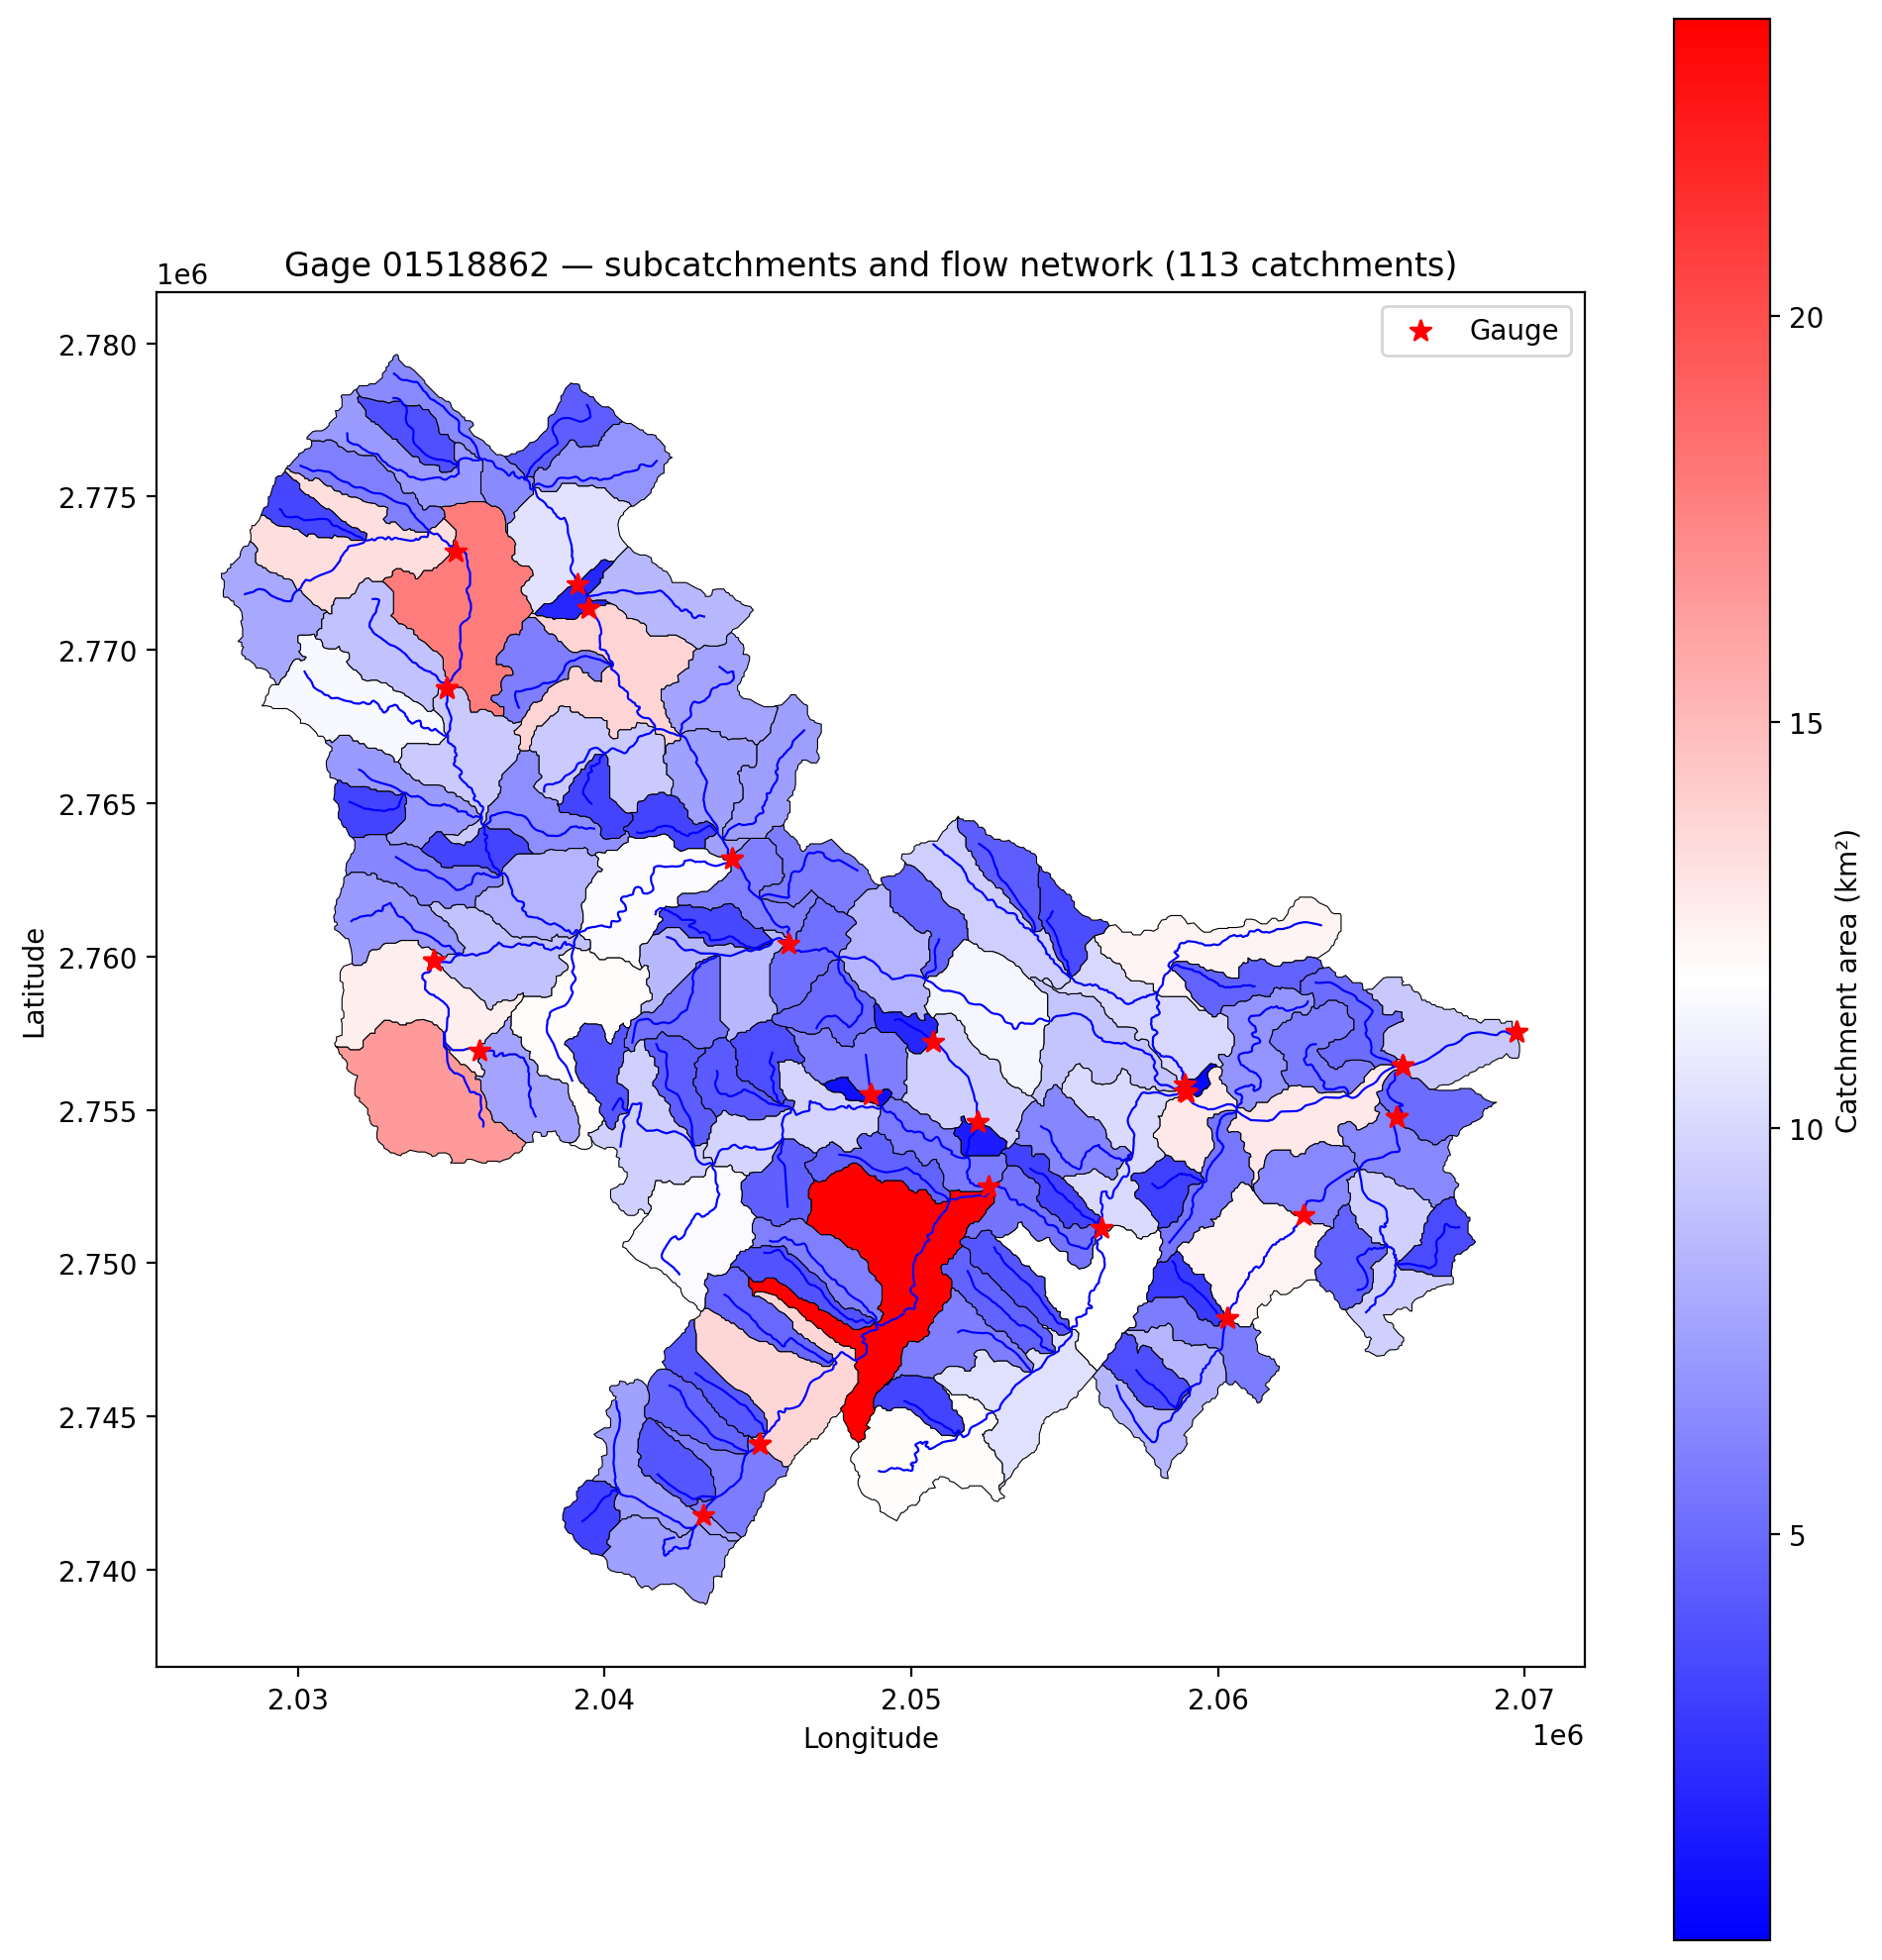

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import fiona

gpkg_path = "/scratch/hdagne1/Docker/gages_conus/gage-01031500/config/gage-01031500_subset.gpkg"

print("Available layers:", fiona.listlayers(gpkg_path))

divides = gpd.read_file(gpkg_path, layer="divides")
flowpaths = gpd.read_file(gpkg_path, layer="flowpaths")

fig, ax = plt.subplots(figsize=(10, 10), dpi=200)

divides.plot(ax=ax, column="areasqkm", cmap="bwr", edgecolor="black",
             linewidth=0.4, legend=True, legend_kwds={"label": "Catchment area (km²)"})
flowpaths.plot(ax=ax, color="blue", linewidth=0.8)

# gauge/outlet location, if a nexus or hydrolocations layer exists
try:
    hydrolocations = gpd.read_file(gpkg_path, layer="hydrolocations")
    hydrolocations.plot(ax=ax, color="red", markersize=60, marker="*", zorder=5, label="Gauge")
    ax.legend()
except Exception:
    pass

ax.set_title(f"Gage 01518862 — subcatchments and flow network ({len(divides)} catchments)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()
# plt.savefig("gage_01518862_subset.png", dpi=150)
plt.show()

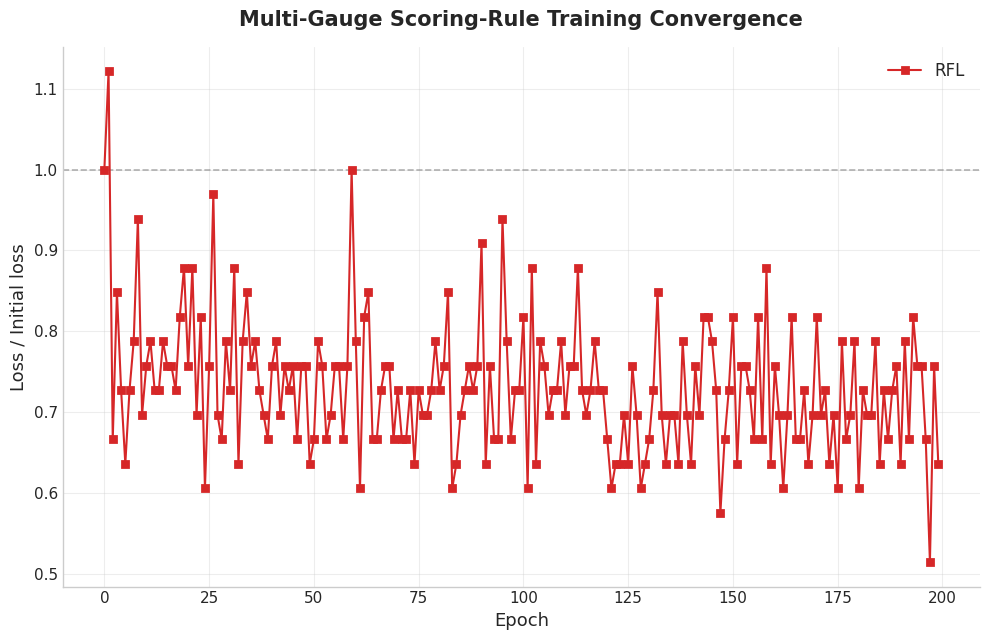

FDC: none found
RFL: 200 epochs, start=0.00033, end=0.00021 (63.6% of start)
Both (FDC+RFL): none found


In [ ]:
import re
import matplotlib.pyplot as plt

LOG_PATH = "/scratch/hdagne1/Docker/NeuralNGEN/runs/logs/lstmNge_53006747_1.out"

def parse_losses(log_path, loss_type_label):
    epochs, losses = [], []
    with open(log_path) as f:
        in_section = False
        for line in f:
            if f"loss_type={loss_type_label}" in line:
                in_section = True
                continue
            if in_section and "loss_type=" in line and loss_type_label not in line:
                in_section = False
                continue
            m = re.search(r"\[Epoch (\d+)\] avg_loss=([\d.]+)", line)
            if in_section and m:
                epochs.append(int(m.group(1)))
                losses.append(float(m.group(2)))
    return epochs, losses

fdc_epochs, fdc_losses = parse_losses(LOG_PATH, "fdc")
rfl_epochs, rfl_losses = parse_losses(LOG_PATH, "rfl")
both_epochs, both_losses = parse_losses(LOG_PATH, "both")

def normalize(losses):
    start = losses[0]
    return [l / start for l in losses]

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(10, 6.5))

curves = [
    ("FDC", fdc_epochs, fdc_losses, "#1f77b4"),   # blue
    ("RFL", rfl_epochs, rfl_losses, "#d62728"),   # red
    ("Both (FDC+RFL)", both_epochs, both_losses, "#2ca02c"),  # green
]

for label, epochs, losses, color in curves:
    if losses:
        ax.plot(epochs, normalize(losses), color=color, linewidth=1.5,
                 marker="s", markersize=5,
                 markeredgecolor=color, markeredgewidth=2, label=label,
                 solid_capstyle="round", zorder=3)

ax.axhline(1.0, color="gray", linestyle="--", linewidth=1.2, alpha=0.6, zorder=1)

ax.set_xlabel("Epoch", fontsize=13, fontweight="medium")
ax.set_ylabel("Loss / Initial loss", fontsize=13, fontweight="medium")
ax.set_title("Multi-Gauge Scoring-Rule Training Convergence",
              fontsize=15, fontweight="bold", pad=15)

ax.legend(fontsize=12, frameon=0, fancybox=True, shadow=True,
          loc="upper right", framealpha=0.95)
ax.grid(alpha=0.35, linewidth=0.8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(labelsize=11)

plt.tight_layout()
# plt.savefig("divergence_curves_multi.png", dpi=200, bbox_inches="tight")
plt.show()

for label, epochs, losses, color in curves:
    if losses:
        pct_of_start = 100 * losses[-1] / losses[0]
        print(f"{label}: {len(losses)} epochs, start={losses[0]:.5f}, end={losses[-1]:.5f} ({pct_of_start:.1f}% of start)")
    else:
        print(f"{label}: none found")

neuralhydrology basins: 88
FDC basins: 502  | RFL basins: 502  | Both basins: 502


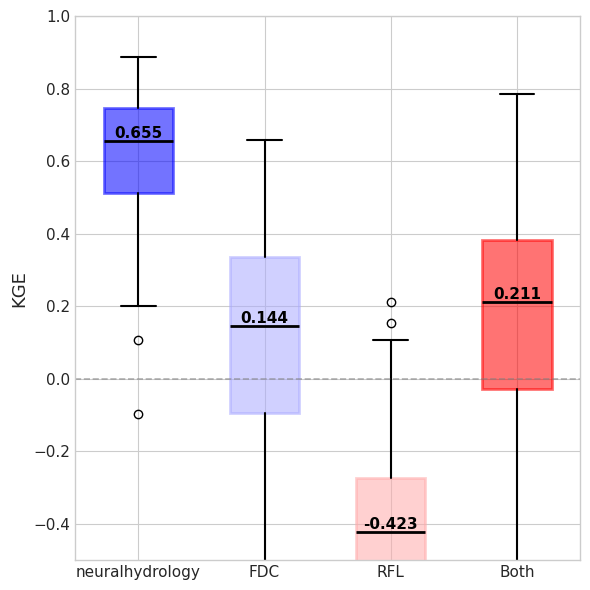


=== KGE summary ===
neuralhydrology: median=0.655, mean=0.611, n=88, %>0=98.9%
FDC: median=0.144, mean=-0.010, n=499, %>0=67.7%
RFL: median=-0.423, mean=-0.400, n=499, %>0=2.8%
Both: median=0.211, mean=0.097, n=499, %>0=72.7%


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm

nh = pd.read_csv(
    "/scratch/hdagne1/Docker/neuralhydrology/runs/nh_aorc_full8_elev_88basin_1508_190532/test/model_epoch005/test_metrics.csv",
    dtype={"basin": str}
)
fdc = pd.read_csv("/scratch/hdagne1/Docker/NeuralNGEN/runs/scoring_rule_multi_fdc/test_metrics_multi.csv", dtype={"gauge_id": str})
rfl = pd.read_csv("/scratch/hdagne1/Docker/NeuralNGEN/runs/scoring_rule_multi_rfl_rfl/test_metrics_multi.csv", dtype={"gauge_id": str})
both = pd.read_csv("/scratch/hdagne1/Docker/NeuralNGEN/runs/scoring_rule_multi_both/test_metrics_multi.csv", dtype={"gauge_id": str})

print("neuralhydrology basins:", len(nh))
print("FDC basins:", len(fdc), " | RFL basins:", len(rfl), " | Both basins:", len(both))

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(6, 6))

data = [nh["KGE"].dropna(), fdc["KGE"].dropna(), rfl["KGE"].dropna(), both["KGE"].dropna()]
labels = ["neuralhydrology", "FDC", "RFL", "Both"]
colors = cm.bwr(np.linspace(0, 1, 4))

bp = ax.boxplot(data, labels=labels, showmeans=0, patch_artist=True, widths=0.55)
for patch, c in zip(bp["boxes"], colors):
    patch.set_facecolor(c)
    patch.set_alpha(0.55)
    patch.set_edgecolor(c)
    patch.set_linewidth(2)
for element in ["whiskers", "caps"]:
    for line in bp[element]:
        line.set_linewidth(1.5)
for median in bp["medians"]:
    median.set_color("black")
    median.set_linewidth(2)

# annotate each box with its median value
y_range = max(d.max() for d in data) - min(d.min() for d in data)
offset = y_range * 0.03
for i, d in enumerate(data):
    med = d.median()
    ax.text(i + 1, med, f"{med:.3f}", ha="center", va="bottom",
            fontsize=11, fontweight="bold", color="black")

ax.axhline(0, color="gray", linestyle="--", linewidth=1.2, alpha=0.6)

ax.set_ylabel("KGE", fontsize=13, fontweight="medium")
# ax.spines["top"].set_visible(False)
# ax.spines["right"].set_visible(False)
ax.tick_params(labelsize=11)
ax.set_ylim(-0.5, 1)
plt.tight_layout()
plt.savefig("kge_comparison_all_models.png", dpi=200, bbox_inches="tight")
plt.show()

print("\n=== KGE summary ===")
for label, d in zip(["neuralhydrology", "FDC", "RFL", "Both"], data):
    print(f"{label}: median={d.median():.3f}, mean={d.mean():.3f}, "
          f"n={len(d)}, %>0={100*(d>0).mean():.1f}%")

# Hydrologic Clusters:

Plotting 515 basins across 10 clusters


/local/tmp/ipykernel_3044490/1125507695.py:35: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap("tab10", n_clusters)


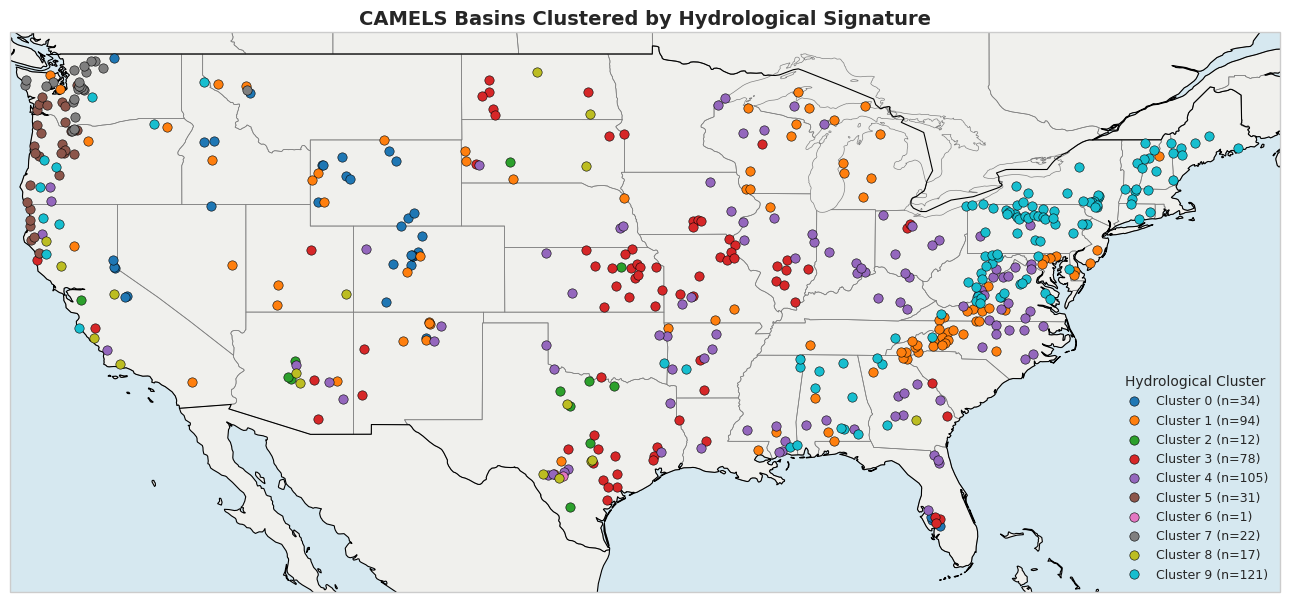

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm

clusters = pd.read_csv("/scratch/hdagne1/Docker/NeuralNGEN/basin_lists/hydro_clusters.csv", dtype={"gauge_id": str})

topo = pd.read_csv(
    "/scratch/hdagne1/Docker/Data/CAMELS_US/camels_attributes_v2.0/camels_topo.txt",
    sep=";", dtype={"gauge_id": str}
)

df = clusters.merge(topo[["gauge_id", "gauge_lat", "gauge_lon"]], on="gauge_id", how="left")
missing = df["gauge_lat"].isna().sum()
if missing:
    print(f"WARNING: {missing} basins missing lat/lon after merge, dropping")
df = df.dropna(subset=["gauge_lat", "gauge_lon"])
print(f"Plotting {len(df)} basins across {df['Clusters'].nunique()} clusters")

try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature

    fig = plt.figure(figsize=(13, 8))
    ax = plt.axes(projection=ccrs.PlateCarree())
    ax.set_extent([-125, -66, 24, 50], crs=ccrs.PlateCarree())


    ax.add_feature(cfeature.LAND, facecolor="#f0f0ed")
    ax.add_feature(cfeature.OCEAN, facecolor="#d6e8f0")
    ax.add_feature(cfeature.STATES, edgecolor="gray", linewidth=0.5)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
    ax.add_feature(cfeature.BORDERS, linewidth=0.8)

    n_clusters = df["Clusters"].nunique()
    cmap = cm.get_cmap("tab10", n_clusters)

    for i, c in enumerate(sorted(df["Clusters"].unique())):
        sub = df[df["Clusters"] == c]
        ax.scatter(sub["gauge_lon"], sub["gauge_lat"], transform=ccrs.PlateCarree(),
                   s=45, color=cmap(i), edgecolor="black", linewidth=0.4,
                   label=f"Cluster {c} (n={len(sub)})", zorder=5)

    ax.legend(loc="lower right", fontsize=9, framealpha=0.95, ncol=1, title="Hydrological Cluster")
    ax.set_title("CAMELS Basins Clustered by Hydrological Signature", fontsize=14, fontweight="bold")

except ImportError:
    print("cartopy not installed -- falling back to plain scatter without basemap boundaries.")
    print("For a real basemap, run: pip install cartopy")

    fig, ax = plt.subplots(figsize=(13, 8))
    n_clusters = df["Clusters"].nunique()
    # cmap = cm.get_cmap("bawr", n_clusters)

    # for i, c in enumerate(sorted(df["Clusters"].unique())):
    #     sub = df[df["Clusters"] == c]
    #     ax.scatter(sub["gauge_lon"], sub["gauge_lat"], s=45, color=cmap(i),
    #                edgecolor="black", linewidth=0.4, label=f"Cluster {c} (n={len(sub)})", zorder=5)

    ax.set_xlim(-125, -66)
    ax.set_ylim(24, 50)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_aspect("equal")
    ax.legend(loc="lower right", fontsize=12, framealpha=0.95, ncol=2, title="Hydrological Cluster")
    # ax.set_title("CAMELS Basins Clustered by Hydrological Signature (no basemap)", fontsize=14, fontweight="bold")
    ax.grid(alpha=0.3)

plt.tight_layout()
# plt.savefig("hydro_clusters_conus_map.png", dpi=200, bbox_inches="tight")
plt.show()

# Hydrologic clusters with AI:

Plotting 515 basins across 10 clusters


/local/tmp/ipykernel_3044490/1540568081.py:50: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap_clusters = cm.get_cmap("tab10", n_clusters)


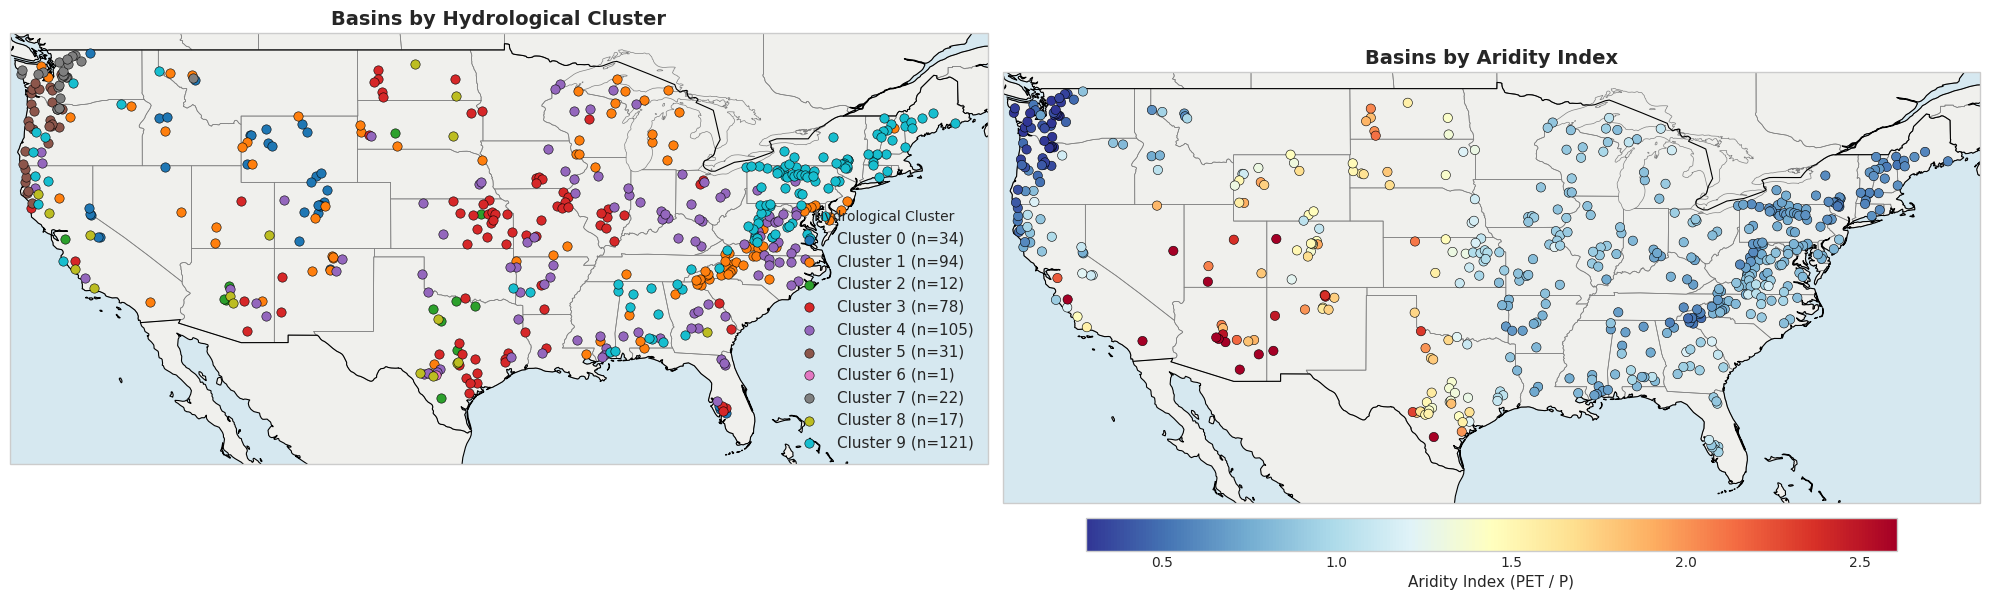

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm

clusters = pd.read_csv("/scratch/hdagne1/Docker/NeuralNGEN/basin_lists/hydro_clusters.csv", dtype={"gauge_id": str})

topo = pd.read_csv(
    "/scratch/hdagne1/Docker/Data/CAMELS_US/camels_attributes_v2.0/camels_topo.txt",
    sep=";", dtype={"gauge_id": str}
)
clim = pd.read_csv(
    "/scratch/hdagne1/Docker/Data/CAMELS_US/camels_attributes_v2.0/camels_clim.txt",
    sep=";", dtype={"gauge_id": str}
)

df = clusters.merge(topo[["gauge_id", "gauge_lat", "gauge_lon"]], on="gauge_id", how="left")
df = df.merge(clim[["gauge_id", "aridity"]], on="gauge_id", how="left")

missing_latlon = df["gauge_lat"].isna().sum()
missing_aridity = df["aridity"].isna().sum()
if missing_latlon:
    print(f"WARNING: {missing_latlon} basins missing lat/lon, dropping")
if missing_aridity:
    print(f"WARNING: {missing_aridity} basins missing aridity, dropping")
df = df.dropna(subset=["gauge_lat", "gauge_lon", "aridity"])
print(f"Plotting {len(df)} basins across {df['Clusters'].nunique()} clusters")

try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    has_cartopy = True
except ImportError:
    has_cartopy = False
    print("cartopy not installed -- falling back to plain scatter without basemap boundaries.")

if has_cartopy:
    fig, axes = plt.subplots(1, 2, figsize=(20, 8), subplot_kw={"projection": ccrs.PlateCarree()})

    for ax in axes:
        ax.set_extent([-125, -66, 24, 50], crs=ccrs.PlateCarree())
        ax.add_feature(cfeature.LAND, facecolor="#f0f0ed")
        ax.add_feature(cfeature.OCEAN, facecolor="#d6e8f0")
        ax.add_feature(cfeature.STATES, edgecolor="gray", linewidth=0.5)
        ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
        ax.add_feature(cfeature.BORDERS, linewidth=0.8)

    # --- left panel: clusters ---
    ax = axes[0]
    n_clusters = df["Clusters"].nunique()
    cmap_clusters = cm.get_cmap("tab10", n_clusters)
    for i, c in enumerate(sorted(df["Clusters"].unique())):
        sub = df[df["Clusters"] == c]
        ax.scatter(sub["gauge_lon"], sub["gauge_lat"], transform=ccrs.PlateCarree(),
                   s=45, color=cmap_clusters(i), edgecolor="black", linewidth=0.4,
                   label=f"Cluster {c} (n={len(sub)})", zorder=5)
    ax.legend(loc="lower right", fontsize=11, framealpha=0.95, ncol=1, title="Hydrological Cluster")
    ax.set_title("Basins by Hydrological Cluster", fontsize=14, fontweight="bold")

    # --- right panel: aridity index ---
    ax = axes[1]
    sc = ax.scatter(df["gauge_lon"], df["gauge_lat"], transform=ccrs.PlateCarree(),
                     s=45, c=df["aridity"], cmap="RdYlBu_r", edgecolor="black",
                     linewidth=0.4, vmin=df["aridity"].quantile(0.02),
                     vmax=df["aridity"].quantile(0.98), zorder=5)
    cbar = fig.colorbar(sc, ax=ax, orientation="horizontal", shrink=0.83, pad=0.02, aspect=25)
    cbar.set_label("Aridity Index (PET / P)", fontsize=11)
    ax.set_title("Basins by Aridity Index", fontsize=14, fontweight="bold")

else:
    fig, axes = plt.subplots(1, 2, figsize=(20, 8))

    ax = axes[0]
    n_clusters = df["Clusters"].nunique()
    cmap_clusters = cm.get_cmap("tab10", n_clusters)
    for i, c in enumerate(sorted(df["Clusters"].unique())):
        sub = df[df["Clusters"] == c]
        ax.scatter(sub["gauge_lon"], sub["gauge_lat"], s=45, color=cmap_clusters(i),
                   edgecolor="black", linewidth=0.4, label=f"Cluster {c} (n={len(sub)})", zorder=5)
    ax.set_xlim(-125, -66)
    ax.set_ylim(24, 50)
    ax.set_aspect("equal")
    ax.legend(loc="lower right", fontsize=11, framealpha=0.95, ncol=1, title="Hydrological Cluster")
    ax.set_title("Basins by Hydrological Cluster (no basemap)", fontsize=14, fontweight="bold")
    ax.grid(alpha=0.3)

    ax = axes[1]
    sc = ax.scatter(df["gauge_lon"], df["gauge_lat"], s=45, c=df["aridity"], cmap="RdYlBu_r",
                     edgecolor="black", linewidth=0.4,
                     vmin=df["aridity"].quantile(0.02), vmax=df["aridity"].quantile(0.98))
    cbar = fig.colorbar(sc, ax=ax, orientation="horizontal", shrink=0.5, pad=0.02, aspect=25)
    cbar.set_label("Aridity Index (PET / P)", fontsize=11)
    ax.set_xlim(-125, -66)
    ax.set_ylim(24, 50)
    ax.set_aspect("equal")
    ax.set_title("Basins by Aridity Index (no basemap)", fontsize=14, fontweight="bold")
    ax.grid(alpha=0.3)

plt.tight_layout()
# plt.savefig("hydro_clusters_and_aridity_conus_map.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:

import re
import sqlite3
import numpy as np
import pandas as pd
import xarray as xr
from pathlib import Path

GAUGES_ROOT = Path("/scratch/hdagne1/Docker/Data/CAMELS_US_ngiab_full")
STREAMFLOW_DIR = Path("/scratch/hdagne1/Docker/Data/CAMELS_US/hourly/usgs_streamflow")
TOPO_PATH = Path("/scratch/hdagne1/Docker/Data/CAMELS_US/camels_attributes_v2.0/camels_topo.txt")
SCENARIOS = ["fdc", "rfl", "both"]

topo = pd.read_csv(TOPO_PATH, sep=";", dtype={"gauge_id": str}).set_index("gauge_id")


def compute_nse(pred, obs):
    pred, obs = np.asarray(pred, dtype=float), np.asarray(obs, dtype=float)
    mask = ~(np.isnan(pred) | np.isnan(obs))
    pred, obs = pred[mask], obs[mask]
    if len(obs) < 2:
        return np.nan
    denom = np.sum((obs - np.mean(obs)) ** 2)
    return np.nan if denom == 0 else 1.0 - np.sum((obs - pred) ** 2) / denom


def compute_kge(pred, obs):
    pred, obs = np.asarray(pred, dtype=float), np.asarray(obs, dtype=float)
    mask = ~(np.isnan(pred) | np.isnan(obs))
    pred, obs = pred[mask], obs[mask]
    if len(obs) < 2 or np.std(obs) == 0 or np.std(pred) == 0 or np.mean(obs) == 0:
        return np.nan
    r = np.corrcoef(pred, obs)[0, 1]
    alpha = np.std(pred) / np.std(obs)
    beta = np.mean(pred) / np.mean(obs)
    return 1.0 - np.sqrt((r - 1) ** 2 + (alpha - 1) ** 2 + (beta - 1) ** 2)


def get_outlet_feature_id(gpkg_path: str):
    conn = sqlite3.connect(gpkg_path)
    cur = conn.cursor()
    cur.execute("SELECT id, tot_drainage_areasqkm FROM flowpaths ORDER BY tot_drainage_areasqkm DESC LIMIT 1")
    row = cur.fetchone()
    n_catchments = conn.execute("SELECT COUNT(*) FROM divides").fetchone()[0]
    conn.close()
    if row is None:
        return None, None
    return int(re.sub(r"\D", "", str(row[0]))), n_catchments


def evaluate_gauge_scenario(gauge_id: str, scenario: str) -> dict:
    gauge_dir = GAUGES_ROOT / f"gage-{gauge_id}"
    troute_dir = gauge_dir / "outputs" / f"troute_{scenario}"
    nc_files = list(troute_dir.glob("troute_output_*.nc"))
    if not nc_files:
        return {"gauge_id": gauge_id, "scenario": scenario, "NSE": np.nan, "KGE": np.nan, "error": "no troute output"}

    gpkg_matches = list((gauge_dir / "config").glob("*_subset.gpkg"))
    if not gpkg_matches:
        return {"gauge_id": gauge_id, "scenario": scenario, "NSE": np.nan, "KGE": np.nan, "error": "no gpkg"}

    sf_path = STREAMFLOW_DIR / f"{gauge_id}-usgs-hourly.csv"
    if not sf_path.exists():
        return {"gauge_id": gauge_id, "scenario": scenario, "NSE": np.nan, "KGE": np.nan, "error": "no streamflow cache"}

    if gauge_id not in topo.index:
        return {"gauge_id": gauge_id, "scenario": scenario, "NSE": np.nan, "KGE": np.nan, "error": "no area_gages2"}

    try:
        outlet_id, n_catchments = get_outlet_feature_id(str(gpkg_matches[0]))
        if outlet_id is None or not n_catchments:
            return {"gauge_id": gauge_id, "scenario": scenario, "NSE": np.nan, "KGE": np.nan, "error": "no flowpaths/divides found"}

        ds = xr.open_dataset(nc_files[0])
        feature_ids = ds["feature_id"].values
        if outlet_id not in feature_ids:
            return {"gauge_id": gauge_id, "scenario": scenario, "NSE": np.nan, "KGE": np.nan,
                     "error": f"outlet id {outlet_id} not in troute output feature_ids"}

        flow_cms_raw = ds["flow"].sel(feature_id=outlet_id).values
        flow_cms = flow_cms_raw / n_catchments

        time_index = pd.to_datetime(ds["time"].values)

        area_sqkm = float(topo.loc[gauge_id, "area_gages2"])
        sf = pd.read_csv(sf_path, parse_dates=["date"]).set_index("date")
        obs_mm_h = sf["QObs(mm/h)"].reindex(time_index)
        obs_cfs = obs_mm_h.values * area_sqkm / 0.10194048
        obs_cms = obs_cfs * 0.0283168

        nse = compute_nse(flow_cms, obs_cms)
        kge = compute_kge(flow_cms, obs_cms)

        return {"gauge_id": gauge_id, "scenario": scenario, "NSE": nse, "KGE": kge,
                "n_catchments": n_catchments, "error": None}

    except Exception as e:
        return {"gauge_id": gauge_id, "scenario": scenario, "NSE": np.nan, "KGE": np.nan, "error": str(e)}


if __name__ == "__main__":
    manifest = pd.read_csv(
        "/scratch/hdagne1/Docker/NeuralNGEN/manifests/ngen_run_manifest.txt",
        header=None, names=["gauge_id", "scenario"], dtype={"gauge_id": str}
    )

    results = []
    for i, row in manifest.iterrows():
        results.append(evaluate_gauge_scenario(row["gauge_id"], row["scenario"]))
        if (i + 1) % 100 == 0:
            print(f"  {i+1}/{len(manifest)} evaluated")

    df = pd.DataFrame(results)
    # df.to_csv("/scratch/hdagne1/Docker/NeuralNGEN/ngen_evaluation_results.csv", index=False)

    print("\n=== Summary by scenario (median-based) ===")
    for scenario in SCENARIOS:
        sub = df[(df["scenario"] == scenario) & df["NSE"].notna()]
        print(f"\n{scenario}: n={len(sub)}")
        if len(sub) > 0:
            print(f"  NSE median={sub['NSE'].median():.4f}, KGE median={sub['KGE'].median():.4f}")
            print(f"  NSE 25/75%: {sub['NSE'].quantile(0.25):.4f} / {sub['NSE'].quantile(0.75):.4f}")
            print(f"  KGE 25/75%: {sub['KGE'].quantile(0.25):.4f} / {sub['KGE'].quantile(0.75):.4f}")
            print(f"  %>0 NSE: {100*(sub['NSE']>0).mean():.1f}%")

    n_errors = df["error"].notna().sum()
    if n_errors > 0:
        print(f"\n{n_errors} gauge/scenario pairs had errors:")
        print(df[df["error"].notna()]["error"].value_counts())


  100/1506 evaluated
  200/1506 evaluated
  300/1506 evaluated
  400/1506 evaluated
  500/1506 evaluated
  600/1506 evaluated
  700/1506 evaluated
  800/1506 evaluated
  900/1506 evaluated
  1000/1506 evaluated
  1100/1506 evaluated
  1200/1506 evaluated
  1300/1506 evaluated
  1400/1506 evaluated
  1500/1506 evaluated

=== Summary by scenario (median-based) ===

fdc: n=496
  NSE median=-40.3744, KGE median=-2.7477
  NSE 25/75%: -2301.2438 / -1.7847
  KGE 25/75%: -35.1633 / -0.3621
  %>0 NSE: 2.6%

rfl: n=496
  NSE median=-3.8633, KGE median=-0.5361
  NSE 25/75%: -128.3934 / -0.8397
  KGE 25/75%: -5.0044 / -0.3363
  %>0 NSE: 4.6%

both: n=496
  NSE median=-27.1723, KGE median=-1.3682
  NSE 25/75%: -1230.0778 / -1.1578
  KGE 25/75%: -22.8116 / -0.3000
  %>0 NSE: 7.7%


In [ ]:
import sys
sys.path.insert(0, "/scratch/hdagne1/Docker/NeuralNGEN")

import torch
import numpy as np
import pandas as pd
import xarray as xr
from pathlib import Path

from src.models.catchment_lstm import CatchmentLSTM

# load checkpoint directly
ckpt = torch.load("/scratch/hdagne1/Docker/NeuralNGEN/runs/scoring_rule_multi_fdc/model_final.pt",
                   map_location="cpu", weights_only=False)
train_cfg = ckpt["config"]

model = CatchmentLSTM(
    dynamic_size=len(train_cfg["dynamic_inputs"]),
    static_size=len(train_cfg["static_attributes"]),
    hidden_size=train_cfg.get("hidden_size", 64),
    num_layers=train_cfg.get("num_layers", 2),
)
model.load_state_dict(ckpt["model_state"])
model.eval()

# real forcing + static attrs for cat-2454, gauge 01031500
ds = xr.open_dataset("/scratch/hdagne1/Docker/Data/CAMELS_US_ngiab_full/gage-01031500/forcings/forcings.nc")
ids = ds["ids"].values.astype(str)
idx = np.where(ids == "cat-2454")[0][0]

dyn_vars = train_cfg["dynamic_inputs"]
dyn = np.stack([ds[v].values[idx, :] for v in dyn_vars], axis=-1)  # (n_time, n_dyn)

time_index = pd.to_datetime(ds["Time"].values[idx, :], unit="s")
window_mask = (time_index >= "2020-01-01") & (time_index < "2020-01-08")
dyn_window = dyn[window_mask]
time_window = time_index[window_mask]

dyn_norm = (dyn_window - ckpt["dyn_mean"]) / ckpt["dyn_std"]

import sqlite3
conn = sqlite3.connect("/scratch/hdagne1/Docker/Data/CAMELS_US_ngiab_full/gage-01031500/config/gage-01031500_subset.gpkg")
cur = conn.cursor()
static_attrs_order = train_cfg["static_attributes"]
col_list = ", ".join(f'"{c}"' for c in static_attrs_order)
cur.execute(f'SELECT {col_list} FROM "divide-attributes" WHERE divide_id="cat-2454"')
static_vals = np.array(cur.fetchone(), dtype=np.float32)
conn.close()
static_norm = (static_vals - ckpt["stat_mean"]) / ckpt["stat_std"]

x_d = torch.tensor(dyn_norm, dtype=torch.float32).unsqueeze(0)   # (1, T, F_dyn)
x_s = torch.tensor(static_norm, dtype=torch.float32).unsqueeze(0)  # (1, F_stat)

with torch.no_grad():
    pred_norm = model(x_d, x_s).squeeze(0).numpy()  # (T,)

q_mean, q_std = ckpt["q_stats"]["01031500"]
pred_mm_h = pred_norm * q_std + q_mean
pred_mm_h = np.clip(pred_mm_h, 0, None)

print("Raw model pred_mm_h for cat-2454, first week of Jan 2020:")
for t, p in zip(time_window[:24], pred_mm_h[:24]):
    print(f"  {t}: {p:.5f} mm/h")

print(f"\npred_mm_h stats: min={pred_mm_h.min():.5f}, max={pred_mm_h.max():.5f}, mean={pred_mm_h.mean():.5f}")

# compare directly against actual observed gauge mm/h for the same period
sf = pd.read_csv("/scratch/hdagne1/Docker/Data/CAMELS_US/hourly/usgs_streamflow/01031500-usgs-hourly.csv",
                  parse_dates=["date"]).set_index("date")
obs_mm_h = sf["QObs(mm/h)"].reindex(time_window)
print(f"\nActual observed mm/h for same period: min={obs_mm_h.min():.5f}, max={obs_mm_h.max():.5f}, mean={obs_mm_h.mean():.5f}")
print(f"\nRatio (pred_mean / obs_mean): {pred_mm_h.mean() / obs_mm_h.mean():.2f}x")

Raw model pred_mm_h for cat-2454, first week of Jan 2020:
  2020-01-01 00:00:00: 0.07456 mm/h
  2020-01-01 01:00:00: 0.07356 mm/h
  2020-01-01 02:00:00: 0.05555 mm/h
  2020-01-01 03:00:00: 0.02800 mm/h
  2020-01-01 04:00:00: 0.01036 mm/h
  2020-01-01 05:00:00: 0.00927 mm/h
  2020-01-01 06:00:00: 0.03186 mm/h
  2020-01-01 07:00:00: 0.05221 mm/h
  2020-01-01 08:00:00: 0.07703 mm/h
  2020-01-01 09:00:00: 0.10344 mm/h
  2020-01-01 10:00:00: 0.12418 mm/h
  2020-01-01 11:00:00: 0.09279 mm/h
  2020-01-01 12:00:00: 0.03980 mm/h
  2020-01-01 13:00:00: 0.00434 mm/h
  2020-01-01 14:00:00: 0.00000 mm/h
  2020-01-01 15:00:00: 0.01658 mm/h
  2020-01-01 16:00:00: 0.03767 mm/h
  2020-01-01 17:00:00: 0.04587 mm/h
  2020-01-01 18:00:00: 0.05380 mm/h
  2020-01-01 19:00:00: 0.06472 mm/h
  2020-01-01 20:00:00: 0.07413 mm/h
  2020-01-01 21:00:00: 0.08399 mm/h
  2020-01-01 22:00:00: 0.08474 mm/h
  2020-01-01 23:00:00: 0.07318 mm/h

pred_mm_h stats: min=0.00000, max=0.21658, mean=0.06217

Actual observed mm/h

In [ ]:
import sys
sys.path.insert(0, "/scratch/hdagne1/Docker/NeuralNGEN")

import torch
import numpy as np
import pandas as pd
import xarray as xr
import sqlite3

ckpt = torch.load("/scratch/hdagne1/Docker/NeuralNGEN/runs/scoring_rule_multi_fdc/model_final.pt",
                   map_location="cpu", weights_only=False)
train_cfg = ckpt["config"]

from src.models.catchment_lstm import CatchmentLSTM
model = CatchmentLSTM(
    dynamic_size=len(train_cfg["dynamic_inputs"]),
    static_size=len(train_cfg["static_attributes"]),
    hidden_size=train_cfg.get("hidden_size", 64),
    num_layers=train_cfg.get("num_layers", 2),
)
model.load_state_dict(ckpt["model_state"])
model.eval()

CATCHMENT = "cat-2751"  # the highest week-1 predictor

ds = xr.open_dataset("/scratch/hdagne1/Docker/Data/CAMELS_US_ngiab_full/gage-01031500/forcings/forcings.nc")
ids = ds["ids"].values.astype(str)
idx = np.where(ids == CATCHMENT)[0][0]
time_index = pd.to_datetime(ds["Time"].values[idx, :], unit="s")
window_mask = (time_index >= "2020-01-01") & (time_index < "2020-02-01")

dyn_vars = train_cfg["dynamic_inputs"]
static_attrs_order = train_cfg["static_attributes"]

dyn = np.stack([ds[v].values[idx, :] for v in dyn_vars], axis=-1)[window_mask]
dyn_norm = (dyn - ckpt["dyn_mean"]) / ckpt["dyn_std"]
time_window = time_index[window_mask]

conn = sqlite3.connect("/scratch/hdagne1/Docker/Data/CAMELS_US_ngiab_full/gage-01031500/config/gage-01031500_subset.gpkg")
cur = conn.cursor()
col_list = ", ".join(f'"{c}"' for c in static_attrs_order)
cur.execute(f'SELECT {col_list} FROM "divide-attributes" WHERE divide_id=?', (CATCHMENT,))
static_vals = np.array(cur.fetchone(), dtype=np.float32)
conn.close()
static_norm = (static_vals - ckpt["stat_mean"]) / ckpt["stat_std"]

x_s = torch.tensor(static_norm, dtype=torch.float32).unsqueeze(0)
q_mean, q_std = ckpt["q_stats"]["01031500"]

h_t, c_t = None, None
pred_stepwise = []
with torch.no_grad():
    for t in range(len(dyn_norm)):
        x_d_t = torch.tensor(dyn_norm[t], dtype=torch.float32).unsqueeze(0)
        p, h_t, c_t = model.forward_step(x_d_t, x_s, h_t, c_t)
        pred_stepwise.append(p.item())
pred_stepwise = np.array(pred_stepwise)
pred_mm_h = np.clip(pred_stepwise * q_std + q_mean, 0, None)

print(f"Full month, continuous state, {CATCHMENT} (highest week-1 predictor):")
print(f"  hours   0-168 (week 1): mean={pred_mm_h[:168].mean():.5f}, max={pred_mm_h[:168].max():.5f}")
print(f"  hours 168-336 (week 2): mean={pred_mm_h[168:336].mean():.5f}, max={pred_mm_h[168:336].max():.5f}")
print(f"  hours 336-504 (week 3): mean={pred_mm_h[336:504].mean():.5f}, max={pred_mm_h[336:504].max():.5f}")
print(f"  hours 504-672 (week 4): mean={pred_mm_h[504:672].mean():.5f}, max={pred_mm_h[504:672].max():.5f}")
print(f"  hours 672-744 (remainder): mean={pred_mm_h[672:].mean():.5f}, max={pred_mm_h[672:].max():.5f}")
print(f"\nOverall month mean: {pred_mm_h.mean():.5f} mm/h")
print(f"Overall month max: {pred_mm_h.max():.5f} mm/h")

Full month, continuous state, cat-2751 (highest week-1 predictor):
  hours   0-168 (week 1): mean=0.05333, max=0.23314
  hours 168-336 (week 2): mean=0.15678, max=0.90572
  hours 336-504 (week 3): mean=0.07039, max=0.16380
  hours 504-672 (week 4): mean=0.10626, max=0.74798
  hours 672-744 (remainder): mean=0.05929, max=0.10532

Overall month mean: 0.09307 mm/h
Overall month max: 0.90572 mm/h


In [ ]:
import xarray as xr
import numpy as np

ds = xr.open_dataset("/scratch/hdagne1/Docker/Data/CAMELS_US_ngiab_full/gage-01031500/outputs/troute_fdc/troute_output_202001010000.nc")
ds

<xarray.Dataset> Size: 1MB
Dimensions:     (time: 744, feature_id: 113)
Coordinates:
  * time        (time) datetime64[ns] 6kB 2020-01-01T01:00:00 ... 2020-02-01
  * feature_id  (feature_id) int64 904B 2461 2462 2463 2464 ... 2755 2756 2757
Data variables:
    type        (feature_id) <U2 904B ...
    flow        (feature_id, time) float32 336kB ...
    velocity    (feature_id, time) float32 336kB ...
    depth       (feature_id, time) float32 336kB ...
    nudge       (feature_id, time) float32 336kB ...
Attributes:
    TITLE:                OUTPUT FROM T-ROUTE
    file_reference_time:  2020-01-01_00:00:00
    code_version:

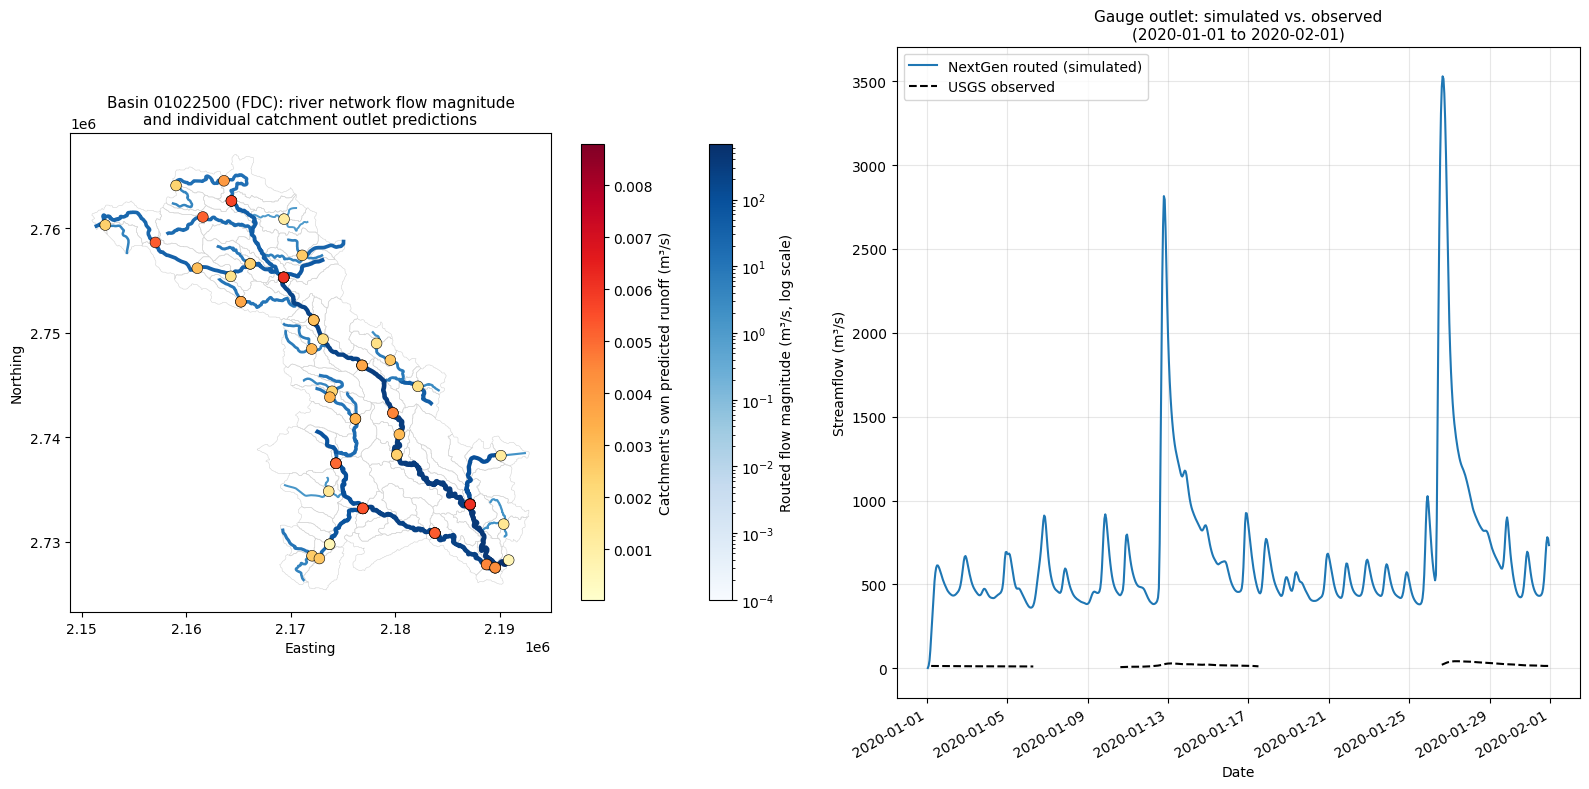

Catchments with runoff data: 80
Outlet feature_id used: 3718
Mean routed flow: 671.6921 m3/s | Mean observed: 18.6369 m3/s


In [ ]:
import re
import sqlite3
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from pathlib import Path

GAUGE_ID = "01022500"
SCENARIO = "fdc"
PLOT_START = "2020-01-01"
PLOT_END = "2020-02-01"

gauge_dir = Path(f"/scratch/hdagne1/Docker/Data/CAMELS_US_ngiab_full/gage-{GAUGE_ID}")
gpkg_path = next((gauge_dir / "config").glob("*_subset.gpkg"))
ngen_out_dir = gauge_dir / "outputs" / f"ngen_{SCENARIO}"
troute_path = gauge_dir / "outputs" / f"troute_{SCENARIO}" / "troute_output_202001010000.nc"
sf_path = Path(f"/scratch/hdagne1/Docker/Data/CAMELS_US/hourly/usgs_streamflow/{GAUGE_ID}-usgs-hourly.csv")

# ---------- real geometry: flowpaths (lines), nexus (points) ----------
flowpaths = gpd.read_file(gpkg_path, layer="flowpaths")
nexus = gpd.read_file(gpkg_path, layer="nexus")
divides = gpd.read_file(gpkg_path, layer="divides")

# ---------- per-catchment own predicted runoff (mean over the period, from cat-XXXX.csv) ----------
catchment_runoff = {}
for csv_file in ngen_out_dir.glob("cat-*.csv"):
    cid = csv_file.stem  # "cat-XXXX"
    df = pd.read_csv(csv_file, parse_dates=["Time"])
    df = df[(df["Time"] >= PLOT_START) & (df["Time"] < PLOT_END)]
    if len(df) > 0:
        catchment_runoff[cid] = df["land_surface_water__runoff_volume_flux"].mean()

# map each catchment (divide_id, e.g. "cat-3706") to its downstream nexus (toid) for plotting a "mouth" point
divides_lookup = divides.set_index("divide_id")
nexus_lookup = nexus.set_index("id")

mouth_points = []
for cid, runoff_val in catchment_runoff.items():
    if cid not in divides_lookup.index:
        continue
    toid = divides_lookup.loc[cid, "toid"]  # this catchment's downstream nexus id
    if toid in nexus_lookup.index:
        pt = nexus_lookup.loc[toid, "geometry"]
        mouth_points.append({"catchment_id": cid, "runoff": runoff_val, "geometry": pt})

mouth_gdf = gpd.GeoDataFrame(mouth_points, crs=nexus.crs)

# ---------- flow magnitude per flowpath segment, from troute output (mean over the period) ----------
ds = xr.open_dataset(troute_path)
time_index = pd.to_datetime(ds["time"].values)
period_mask = (time_index >= PLOT_START) & (time_index < PLOT_END)
mean_flow_per_feature = ds["flow"].isel(time=period_mask).mean(dim="time").to_pandas()  # index: feature_id (int)

flowpaths = flowpaths.copy()
flowpaths["numeric_id"] = flowpaths["id"].apply(lambda s: int(re.sub(r"\D", "", str(s))))
flowpaths["mean_flow"] = flowpaths["numeric_id"].map(mean_flow_per_feature)

# ---------- identify the real outlet segment (largest total drainage area) ----------
outlet_row = flowpaths.loc[flowpaths["tot_drainage_areasqkm"].idxmax()] if "tot_drainage_areasqkm" in flowpaths.columns else None
if outlet_row is None:
    # fallback: join from divides table which we know has tot_drainage_areasqkm
    outlet_divide_id = divides.loc[divides["tot_drainage_areasqkm"].idxmax(), "id"]
    outlet_numeric_id = int(re.sub(r"\D", "", str(outlet_divide_id)))
else:
    outlet_numeric_id = outlet_row["numeric_id"]

outlet_flow_series = ds["flow"].sel(feature_id=outlet_numeric_id).to_pandas()
outlet_flow_series = outlet_flow_series[(outlet_flow_series.index >= PLOT_START) & (outlet_flow_series.index < PLOT_END)]

# ---------- real observed streamflow, converted to cms ----------
topo = pd.read_csv("/scratch/hdagne1/Docker/Data/CAMELS_US/camels_attributes_v2.0/camels_topo.txt",
                    sep=";", dtype={"gauge_id": str}).set_index("gauge_id")
area_sqkm = float(topo.loc[GAUGE_ID, "area_gages2"])
sf = pd.read_csv(sf_path, parse_dates=["date"]).set_index("date")["QObs(mm/h)"]
sf_window = sf[(sf.index >= PLOT_START) & (sf.index < PLOT_END)]
obs_cms = sf_window * area_sqkm / 0.10194048 * 0.0283168

# ==================== FIGURE ====================
fig = plt.figure(figsize=(16, 8))
gs = fig.add_gridspec(1, 2, width_ratios=[1.1, 1])

# ---- Panel 1: river network + catchment mouths ----
ax1 = fig.add_subplot(gs[0])
divides.boundary.plot(ax=ax1, color="lightgray", linewidth=0.4, zorder=1)

norm = mcolors.LogNorm(vmin=max(flowpaths["mean_flow"].min(), 1e-4), vmax=flowpaths["mean_flow"].max())
flowpaths.plot(ax=ax1, column="mean_flow", cmap="Blues", linewidth=flowpaths["mean_flow"].rank(pct=True) * 3 + 0.5,
               norm=norm, zorder=2, legend=True,
               legend_kwds={"label": "Routed flow magnitude (m³/s, log scale)", "shrink": 0.7})

mouth_gdf.plot(ax=ax1, column="runoff", cmap="YlOrRd", markersize=60, edgecolor="k",
               linewidth=0.4, zorder=3, legend=True,
               legend_kwds={"label": "Catchment's own predicted runoff (m³/s)", "shrink": 0.7})

ax1.set_title(f"Basin {GAUGE_ID} ({SCENARIO.upper()}): river network flow magnitude\n"
              f"and individual catchment outlet predictions", fontsize=11)
ax1.set_xlabel("Easting")
ax1.set_ylabel("Northing")
ax1.set_aspect("equal")

# ---- Panel 2: routed outlet flow vs observed ----
ax2 = fig.add_subplot(gs[1])
ax2.plot(outlet_flow_series.index, outlet_flow_series.values, color="#1f77b4", linewidth=1.5, label="NextGen routed (simulated)")
ax2.plot(obs_cms.index, obs_cms.values, color="k", linewidth=1.5, linestyle="--", label="USGS observed")
ax2.set_xlabel("Date")
ax2.set_ylabel("Streamflow (m³/s)")
ax2.set_title(f"Gauge outlet: simulated vs. observed\n({PLOT_START} to {PLOT_END})", fontsize=11)
ax2.legend()
ax2.grid(alpha=0.3)
plt.setp(ax2.xaxis.get_majorticklabels(), rotation=30, ha="right")

plt.tight_layout()
plt.savefig("basin_network_flow_visualization.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Catchments with runoff data: {len(mouth_gdf)}")
print(f"Outlet feature_id used: {outlet_numeric_id}")
print(f"Mean routed flow: {outlet_flow_series.mean():.4f} m3/s | Mean observed: {obs_cms.mean():.4f} m3/s")

In [ ]:

from pathlib import Path

STREAMFLOW_DIR = Path("/scratch/hdagne1/Docker/Data/CAMELS_US/hourly/usgs_streamflow")

results = []
csv_files = sorted(STREAMFLOW_DIR.glob("*-usgs-hourly.csv"))
print(f"Found {len(csv_files)} cached streamflow files")

for f in csv_files:
    gauge_id = f.stem.replace("-usgs-hourly", "")
    try:
        df = pd.read_csv(f, parse_dates=["date"])
    except Exception as e:
        results.append({"gauge_id": gauge_id, "error": str(e)})
        continue

    n_total = len(df)
    n_valid = df["QObs(mm/h)"].notna().sum()
    pct_valid = 100 * n_valid / n_total if n_total > 0 else 0
    date_min = df["date"].min()
    date_max = df["date"].max()

    results.append({
        "gauge_id": gauge_id,
        "n_total": n_total,
        "n_valid": n_valid,
        "pct_valid": pct_valid,
        "date_min": date_min,
        "date_max": date_max,
        "error": None,
    })

summary = pd.DataFrame(results)
summary.to_csv("/scratch/hdagne1/Docker/NeuralNGEN/streamflow_data_audit.csv", index=False)

valid_summary = summary[summary["error"].isna()]

print(f"\n=== Overall summary across {len(valid_summary)} gauges ===")
print(valid_summary["pct_valid"].describe())

print("\n=== Breakdown by completeness tier ===")
tiers = [
    (95, 100, "95-100% complete"),
    (90, 95, "90-95%"),
    (80, 90, "80-90%"),
    (50, 80, "50-80%"),
    (0, 50, "under 50%"),
]
for lo, hi, label in tiers:
    n = ((valid_summary["pct_valid"] >= lo) & (valid_summary["pct_valid"] < hi)).sum()
    print(f"  {label}: {n} gauges")

n_errors = summary["error"].notna().sum()
if n_errors > 0:
    print(f"\n{n_errors} files failed to read entirely:")
    print(summary[summary["error"].notna()][["gauge_id", "error"]])

print(f"\nFull per-gauge audit saved to streamflow_data_audit.csv")


In [ ]:
%run /bighome/hdagne1/NeuralNGEN/Figures/NSE_KGE_lstm_perfomance.py

In [ ]:
"""
Permutation importance for the trained scoring-rule LSTM.

For each static attribute (and separately, each dynamic input), shuffle
that ONE feature's values across catchments/gauges in the test set, rerun
inference, and measure how much NSE/KGE degrades relative to the real
(un-shuffled) baseline. A feature whose shuffle barely changes performance
is a strong candidate to drop; one whose shuffle causes a large drop is
genuinely important. Uses the existing trained checkpoint -- no retraining.
"""
import sys
import numpy as np
import pandas as pd
import torch

sys.path.insert(0, "/bighome/hdagne1/NeuralNGEN")
from src.dataset.multi_gauge_batcher import GaugeHandle
from src.models.catchment_lstm import CatchmentLSTM


def compute_nse(pred, obs):
    pred, obs = np.asarray(pred).ravel(), np.asarray(obs).ravel()
    mask = ~(np.isnan(pred) | np.isnan(obs))
    pred, obs = pred[mask], obs[mask]
    if len(obs) == 0:
        return np.nan
    denom = np.sum((obs - np.mean(obs)) ** 2)
    return np.nan if denom == 0 else 1.0 - np.sum((obs - pred) ** 2) / denom


def evaluate_with_permutation(ckpt_path, gauges_root, streamflow_dir, n_test_gauges=60, seed=42):
    ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
    train_cfg = ckpt["config"]
    dynamic_inputs = train_cfg["dynamic_inputs"]
    static_attributes = train_cfg["static_attributes"]

    model = CatchmentLSTM(
        dynamic_size=len(dynamic_inputs), static_size=len(static_attributes),
        hidden_size=train_cfg.get("hidden_size", 64), num_layers=train_cfg.get("num_layers", 2),
    )
    model.load_state_dict(ckpt["model_state"])
    model.eval()

    dyn_mean, dyn_std = ckpt["dyn_mean"], ckpt["dyn_std"]
    stat_mean, stat_std = ckpt["stat_mean"], ckpt["stat_std"]
    q_stats = ckpt["q_stats"]

    test_start = pd.Timestamp(train_cfg["test_start_date"])
    test_end = pd.Timestamp(train_cfg["test_end_date"])

    rng = np.random.default_rng(seed)
    gauge_ids = ckpt["gauge_ids"]
    sample_gauges = rng.choice(gauge_ids, size=min(n_test_gauges, len(gauge_ids)), replace=False)

    # gather real static feature values across all catchments in the sample,
    # for shuffling later
    all_static_rows = []
    gauge_data = []
    for gid in sample_gauges:
        if gid not in q_stats:
            continue
        try:
            handle = GaugeHandle(gid, gauges_root, streamflow_dir, dynamic_inputs, static_attributes)
        except Exception:
            continue
        ts_idx = int(np.searchsorted(handle.time_index, test_start))
        te_idx = int(np.searchsorted(handle.time_index, test_end))
        if te_idx <= ts_idx:
            continue
        dyn, q_window = handle.get_window(ts_idx, te_idx)
        gauge_data.append((gid, handle, dyn, q_window))
        all_static_rows.append(handle.static)

    all_static = np.concatenate(all_static_rows, axis=0)  # pooled across all catchments, for shuffling pool

    def run_inference(static_override_fn=None, dyn_override_fn=None):
        results = []
        for gid, handle, dyn, q_window in gauge_data:
            static = handle.static.copy()
            dyn_local = dyn.copy()
            if static_override_fn is not None:
                static = static_override_fn(static)
            if dyn_override_fn is not None:
                dyn_local = dyn_override_fn(dyn_local)

            dyn_norm = (dyn_local - dyn_mean) / dyn_std
            stat_norm = (static - stat_mean) / stat_std
            dyn_t = torch.tensor(dyn_norm, dtype=torch.float32)
            stat_t = torch.tensor(stat_norm, dtype=torch.float32)

            chunk_size = 2000
            preds = []
            with torch.no_grad():
                for start in range(0, dyn_t.shape[1], chunk_size):
                    end = min(start + chunk_size, dyn_t.shape[1])
                    preds.append(model(dyn_t[:, start:end, :], stat_t).numpy())
            pred_norm = np.concatenate(preds, axis=1)

            q_mean, q_std = q_stats[gid]
            pred_physical = np.clip(pred_norm * q_std + q_mean, 0, None)
            areas = handle.areas
            pred_agg = (pred_physical * areas[:, None]).sum(axis=0) / areas.sum()

            results.append(compute_nse(pred_agg, q_window))
        return np.nanmedian(results)

    print(f"Evaluating on {len(gauge_data)} gauges...")
    baseline_nse = run_inference()
    print(f"\nBaseline median NSE (no permutation): {baseline_nse:.4f}\n")

    print("=== Static attribute importance (drop in NSE when shuffled) ===")
    static_results = []
    for i, attr_name in enumerate(static_attributes):
        def shuffle_static(static, idx=i):
            static = static.copy()
            static[:, idx] = rng.permutation(all_static[:, idx])[:static.shape[0]]
            return static
        shuffled_nse = run_inference(static_override_fn=shuffle_static)
        drop = baseline_nse - shuffled_nse
        static_results.append({"feature": attr_name, "shuffled_nse": shuffled_nse, "nse_drop": drop})
        print(f"  {attr_name:40s} shuffled_nse={shuffled_nse:.4f}  drop={drop:+.4f}")

    print("\n=== Dynamic input importance (drop in NSE when shuffled) ===")
    dyn_results = []
    for i, var_name in enumerate(dynamic_inputs):
        def shuffle_dyn(dyn, idx=i):
            dyn = dyn.copy()
            perm = rng.permutation(dyn.shape[1])
            dyn[:, :, idx] = dyn[:, perm, idx]
            return dyn
        shuffled_nse = run_inference(dyn_override_fn=shuffle_dyn)
        drop = baseline_nse - shuffled_nse
        dyn_results.append({"feature": var_name, "shuffled_nse": shuffled_nse, "nse_drop": drop})
        print(f"  {var_name:40s} shuffled_nse={shuffled_nse:.4f}  drop={drop:+.4f}")

    static_df = pd.DataFrame(static_results).sort_values("nse_drop", ascending=False)
    dyn_df = pd.DataFrame(dyn_results).sort_values("nse_drop", ascending=False)

    print("\n=== Ranked: most to least important STATIC attributes ===")
    print(static_df.to_string(index=False))
    print("\n=== Ranked: most to least important DYNAMIC inputs ===")
    print(dyn_df.to_string(index=False))

    # static_df.to_csv("/bighome/hdagne1/NeuralNGEN/feature_importance_static.csv", index=False)
    # dyn_df.to_csv("/bighome/hdagne1/NeuralNGEN/feature_importance_dynamic.csv", index=False)
    print("\nSaved to feature_importance_static.csv / feature_importance_dynamic.csv")


if __name__ == "__main__":
    evaluate_with_permutation(
        ckpt_path="/bighome/hdagne1/NeuralNGEN/runs/scoring_rule_multi_all/model_final.pt",
        gauges_root="/bighome/hdagne1/Data/CAMELS_US_ngiab_full",
        streamflow_dir="/bighome/hdagne1/NeuralNGEN/Data/CAMELS_US/hourly/usgs_streamflow",
        n_test_gauges=60,
    )

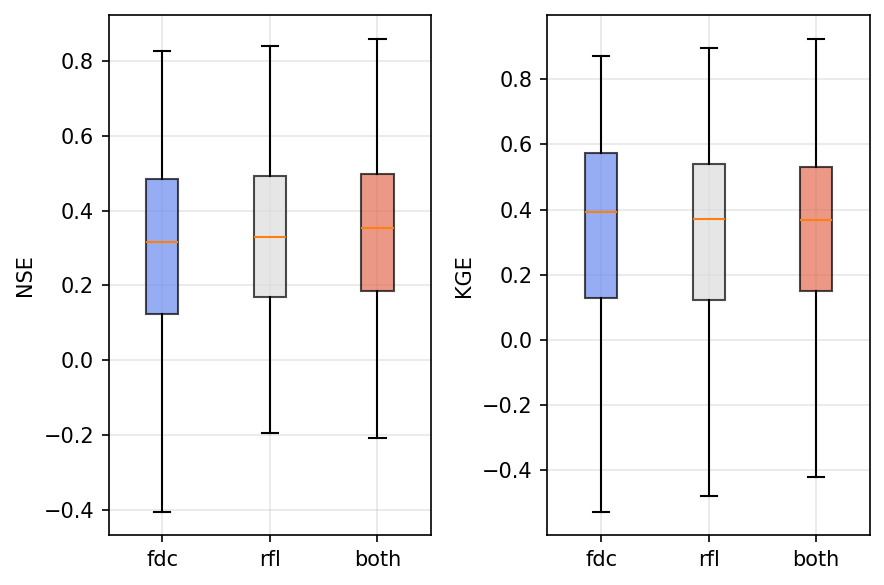

=== Median values ===
  fdc: NSE=0.3155, KGE=0.3943
  rfl: NSE=0.3291, KGE=0.3700
  both: NSE=0.3545, KGE=0.3684


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

paths = {
    "fdc": "/bighome/hdagne1/NeuralNGEN/runs/scoring_rule_multi_fdc/test_metrics_multi.csv",
    "rfl": "/bighome/hdagne1/NeuralNGEN/runs/scoring_rule_multi_rfl/test_metrics_multi.csv",
    "both": "/bighome/hdagne1/NeuralNGEN/runs/scoring_rule_multi_both/test_metrics_multi.csv",
}

data = {name: pd.read_csv(path) for name, path in paths.items()}

fig, axes = plt.subplots(1, 2, figsize=(6, 4), dpi=150)

nse_data = [data[s]["NSE"].dropna() for s in ["fdc", "rfl", "both"]]
kge_data = [data[s]["KGE"].dropna() for s in ["fdc", "rfl", "both"]]

cmap = plt.get_cmap("coolwarm")
colors = [cmap(0.15), cmap(0.5), cmap(0.85)]

bp1 = axes[0].boxplot(nse_data, labels=["fdc", "rfl", "both"],
                       patch_artist=True, showfliers=False)
axes[0].set_ylabel("NSE")
# axes[0].set_title("NSE")
axes[0].grid(alpha=0.3)

bp2 = axes[1].boxplot(kge_data, labels=["fdc", "rfl", "both"],
                       patch_artist=True, showfliers=False)
axes[1].set_ylabel("KGE")
# axes[1].set_title("KGE")
axes[1].grid(alpha=0.3)

for bp in [bp1, bp2]:
    for patch, color in zip(bp["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)

plt.tight_layout()
plt.show()

print("=== Median values ===")
for s in ["fdc", "rfl", "both"]:
    print(f"  {s}: NSE={data[s]['NSE'].median():.4f}, KGE={data[s]['KGE'].median():.4f}")

# After Bighome:

In [ ]:
import pandas as pd

results = {}
for scenario in ["rfl", "fdc", "all"]:
    df = pd.read_csv(f"/bighome/hdagne1/NeuralNGEN/runs/scoring_rule_multi_{scenario}/test_metrics.csv")
    results[scenario] = df
    print(f"=== {scenario} ({len(df)} gauges evaluated) ===")
    print(df[["NSE", "KGE"]].describe())
    print(f"Median NSE: {df['NSE'].median():.3f}   Median KGE: {df['KGE'].median():.3f}")
    print(f"NSE > 0.5 (good):               {(df['NSE'] > 0.5).sum()} / {len(df)}")
    print(f"NSE 0–0.5 (mediocre):           {((df['NSE'] > 0) & (df['NSE'] <= 0.5)).sum()} / {len(df)}")
    print(f"NSE < 0 (worse than mean-flow): {(df['NSE'] < 0).sum()} / {len(df)}")
    print()

=== rfl (358 gauges evaluated) ===
              NSE         KGE
count  358.000000  358.000000
mean     0.176237    0.138957
std      0.137246    0.171848
min     -0.702558   -0.383490
25%      0.122483    0.060686
50%      0.195072    0.164859
75%      0.257450    0.258016
max      0.445196    0.498137
Median NSE: 0.195   Median KGE: 0.165
NSE > 0.5 (good):               0 / 358
NSE 0–0.5 (mediocre):           327 / 358
NSE < 0 (worse than mean-flow): 31 / 358

=== fdc (358 gauges evaluated) ===
              NSE         KGE
count  358.000000  358.000000
mean     0.155984    0.160388
std      0.167129    0.179279
min     -0.828983   -0.396007
25%      0.105559    0.077734
50%      0.188893    0.185096
75%      0.254414    0.280916
max      0.459695    0.508062
Median NSE: 0.189   Median KGE: 0.185
NSE > 0.5 (good):               0 / 358
NSE 0–0.5 (mediocre):           322 / 358
NSE < 0 (worse than mean-flow): 36 / 358

=== all (358 gauges evaluated) ===
              NSE         KGE
c

In [ ]:
for scenario in ["rfl", "all"]:
    df = results[scenario]
    n = len(df)
    print(f"=== {scenario} ({n} gauges) ===")
    print(f"NSE > 0:    {(df['NSE'] > 0).sum()} / {n}  ({100*(df['NSE'] > 0).mean():.1f}%)")
    print(f"NSE >= 0.5: {(df['NSE'] >= 0.5).sum()} / {n}  ({100*(df['NSE'] >= 0.5).mean():.1f}%)")
    print(f"KGE > 0:    {(df['KGE'] > 0).sum()} / {n}  ({100*(df['KGE'] > 0).mean():.1f}%)")
    print(f"KGE >= 0.5: {(df['KGE'] >= 0.5).sum()} / {n}  ({100*(df['KGE'] >= 0.5).mean():.1f}%)")
    print()

=== rfl (358 gauges) ===
NSE > 0:    327 / 358  (91.3%)
NSE >= 0.5: 0 / 358  (0.0%)
KGE > 0:    292 / 358  (81.6%)
KGE >= 0.5: 0 / 358  (0.0%)

=== all (358 gauges) ===
NSE > 0:    269 / 358  (75.1%)
NSE >= 0.5: 0 / 358  (0.0%)
KGE > 0:    216 / 358  (60.3%)
KGE >= 0.5: 0 / 358  (0.0%)



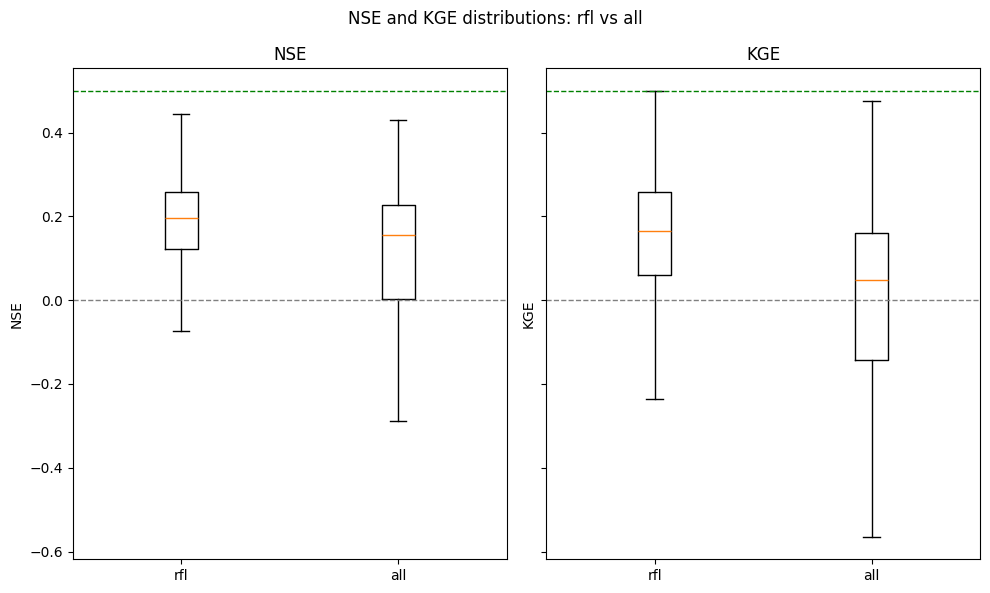

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 6), sharey=True)

for ax, metric in zip(axes, ["NSE", "KGE"]):
    data = [results["rfl"][metric], results["all"][metric]]
    ax.boxplot(data, labels=["rfl", "all"], showfliers=False)
    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax.axhline(0.5, color="green", linestyle="--", linewidth=1)
    ax.set_title(metric)
    ax.set_ylabel(metric)

plt.suptitle("NSE and KGE distributions: rfl vs all")
plt.tight_layout()
plt.savefig("/tmp/nse_kge_boxplot.png", dpi=150)
plt.show()

In [ ]:
pd.read_parquet("/bighome/hdagne1/Data/usgs_streamflow_ref/01013500.parquet")

,flow_m3s
1979-01-01,3.398016
1979-01-02,3.398016
1979-01-03,3.681184
1979-01-04,4.247520
1979-01-05,5.946528
...,...
2023-01-27,38.227680
2023-01-28,36.811840
2023-01-29,35.679168
2023-01-30,34.546496


In [ ]:
import pandas as pd
from pathlib import Path

streamflow_dir = Path("/bighome/hdagne1/Data/usgs_streamflow_ref")

records = []
for f in streamflow_dir.glob("*.parquet"):
    df = pd.read_parquet(f)
    idx = pd.to_datetime(df.index)
    records.append({"gauge": f.stem, "start": idx.min(), "end": idx.max(), "n_days": len(df)})

cov = pd.DataFrame(records)
print(cov[["start", "end", "n_days"]].describe())
print()
print("Earliest end date across all gauges (bottleneck for a global test window):")
print(cov.nsmallest(10, "end")[["gauge", "start", "end", "n_days"]])
print()
print("Latest start date across all gauges (bottleneck for how far back training can go):")
print(cov.nlargest(10, "start")[["gauge", "start", "end", "n_days"]])

                               start                  end        n_days
count                            441                  441    441.000000
mean   1979-01-01 04:53:52.653061216  2023-01-31 00:00:00  16101.795918
min              1979-01-01 00:00:00  2023-01-31 00:00:00  16012.000000
25%              1979-01-01 00:00:00  2023-01-31 00:00:00  16102.000000
50%              1979-01-01 00:00:00  2023-01-31 00:00:00  16102.000000
75%              1979-01-01 00:00:00  2023-01-31 00:00:00  16102.000000
max              1979-04-01 00:00:00  2023-01-31 00:00:00  16102.000000
std                              NaN                  NaN      4.285714

Earliest end date across all gauges (bottleneck for a global test window):
      gauge      start        end  n_days
0  01013500 1979-01-01 2023-01-31   16102
1  01022500 1979-01-01 2023-01-31   16102
2  01030500 1979-01-01 2023-01-31   16102
3  01031500 1979-01-01 2023-01-31   16102
4  01047000 1979-01-01 2023-01-31   16102
5  01052500 1979-01-01 2

In [ ]:
pd.read_parquet("/bighome/hdagne1/Data/CAMELS_US_ngiab_full/gage-01013500/202001010000NEXOUT.parquet")

,202001010000
feature_id,
5750,1471520.0
5762,1560830.0
5792,66677.8
5726,269770.0
5724,539064.0
...,...
5531,520606.0
5533,535092.0
5539,650607.0


In [ ]:
import xarray as xr

ds = xr.open_dataset(
    "/bighome/hdagne1/Data/CAMELS_US_ngiab_full/gage-01117468/outputs/troute_rfl_stream/troute_output_202001010000.nc"
)

ds

<xarray.Dataset> Size: 643kB
Dimensions:     (time: 8928, feature_id: 4)
Coordinates:
  * time        (time) datetime64[ns] 71kB 2020-01-01T00:05:00 ... 2020-02-01
  * feature_id  (feature_id) int64 32B 11257 11258 11259 11260
Data variables:
    type        (feature_id) <U2 32B ...
    flow        (feature_id, time) float32 143kB ...
    velocity    (feature_id, time) float32 143kB ...
    depth       (feature_id, time) float32 143kB ...
    nudge       (feature_id, time) float32 143kB ...
Attributes:
    TITLE:                OUTPUT FROM T-ROUTE
    file_reference_time:  2020-01-01_00:00:00
    code_version:

In [ ]:

import xarray as xr
ds = xr.open_dataset('/bighome/hdagne1/Data/CAMELS_US_ngiab_full/gage-01117468/outputs/troute_rfl_stream/troute_output_202001010000.nc')
q = ds.flow.sel(feature_id=11260)
print('min', float(q.min()), 'max', float(q.max()), 'mean', float(q.mean()))


min 9.448758125305176 max 19972.83984375 mean 10240.3310546875


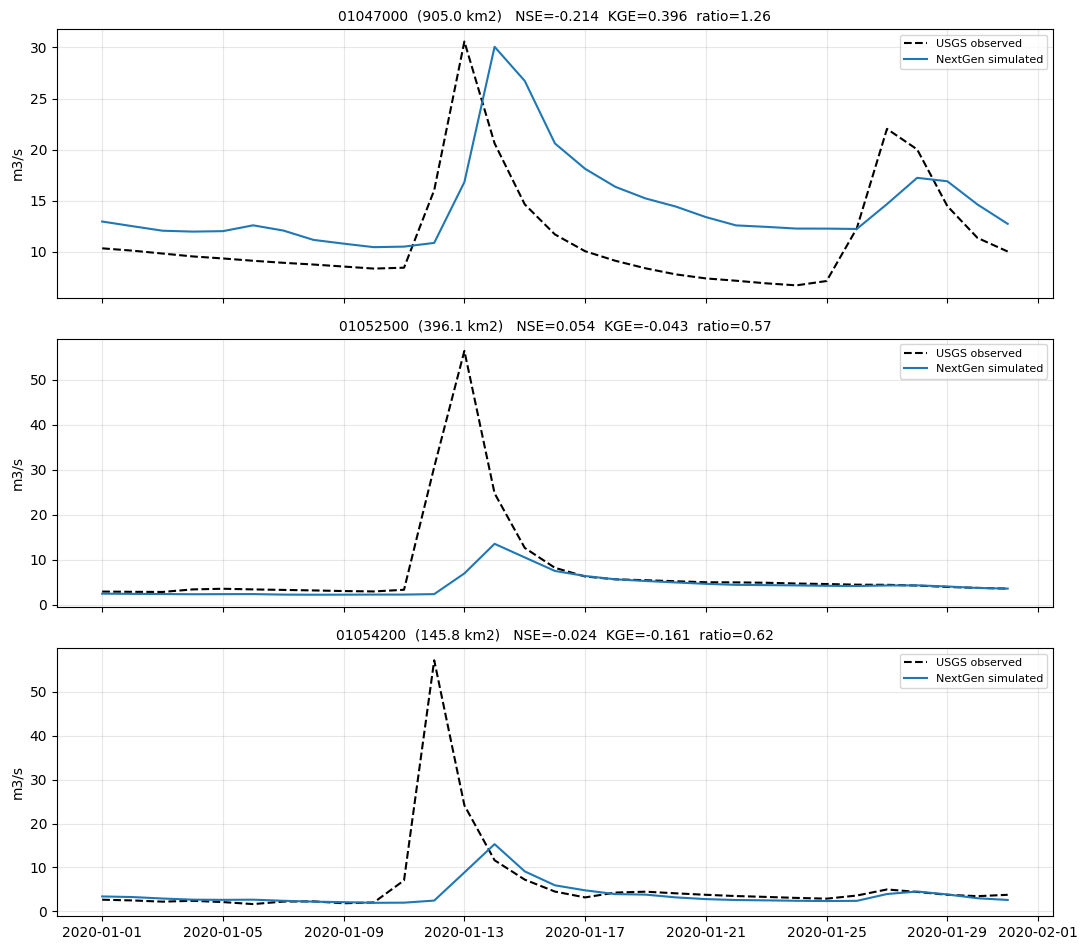

,gauge,area_km2,days,sim_mean,obs_mean,ratio,NSE,KGE,r
0,01047000,905.0,31,14.50,11.47,1.26,-0.214,0.396,0.484
1,01052500,396.1,31,4.36,7.71,0.57,0.054,-0.043,0.441
2,01054200,145.8,31,3.82,6.13,0.62,-0.024,-0.161,0.185


In [ ]:
import sqlite3, requests
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt

def compare(gauge, scenario="rfl"):
    gdir = Path(f"/bighome/hdagne1/Data/CAMELS_US_ngiab_full/gage-{gauge}")
    gpkg = next((gdir / "config").glob("*_subset.gpkg"))
    nc = next((gdir / "outputs" / f"troute_{scenario}_stream").glob("troute_output_*.nc"))
    con = sqlite3.connect(gpkg)
    wb = con.execute('SELECT id FROM "flowpath-attributes" WHERE gage=?', (gauge,)).fetchone()[0]
    area = con.execute("SELECT SUM(areasqkm) FROM divides").fetchone()[0]
    con.close()
    fid = int(wb.split("-")[1])
    sim = xr.open_dataset(nc)["flow"].sel(feature_id=fid).to_pandas()
    sim.index = pd.to_datetime(sim.index)
    sim_d = sim.resample("1D").mean()
    r = requests.get("https://api.waterdata.usgs.gov/ogcapi/v0/collections/daily/items",
                     params=dict(monitoring_location_id=f"USGS-{gauge}", parameter_code="00060",
                                 statistic_id="00003", time="2020-01-01/2020-01-31", f="json", limit=1000), timeout=60)
    r.raise_for_status()
    obs_d = pd.Series({pd.Timestamp(f["properties"]["time"][:10]): float(f["properties"]["value"])
                       for f in r.json()["features"]}) * 0.0283168
    j = pd.concat([sim_d.rename("sim"), obs_d.rename("obs")], axis=1, join="inner").dropna()
    s, o = j.sim.values, j.obs.values
    nse = 1 - ((s - o) ** 2).sum() / ((o - o.mean()) ** 2).sum()
    r_ = np.corrcoef(s, o)[0, 1]
    kge = 1 - np.sqrt((r_ - 1) ** 2 + (s.std() / o.std() - 1) ** 2 + (s.mean() / o.mean() - 1) ** 2)
    metrics = dict(gauge=gauge, area_km2=round(area, 1), days=len(j), sim_mean=round(s.mean(), 2),
                   obs_mean=round(o.mean(), 2), ratio=round(s.mean() / o.mean(), 2),
                   NSE=round(nse, 3), KGE=round(kge, 3), r=round(r_, 3))
    return metrics, j

gauges = ["01047000", "01052500", "01054200"]
results = [compare(g) for g in gauges]

fig, axes = plt.subplots(len(gauges), 1, figsize=(11, 3.2 * len(gauges)), sharex=True)
for ax, (m, j) in zip(np.atleast_1d(axes), results):
    ax.plot(j.index, j["obs"], "k--", lw=1.5, label="USGS observed")
    ax.plot(j.index, j["sim"], color="#1f77b4", lw=1.5, label="NextGen simulated")
    ax.set_ylabel("m3/s")
    ax.set_title(f"{m['gauge']}  ({m['area_km2']} km2)   NSE={m['NSE']}  KGE={m['KGE']}  ratio={m['ratio']}", fontsize=10)
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

pd.DataFrame([m for m, _ in results])

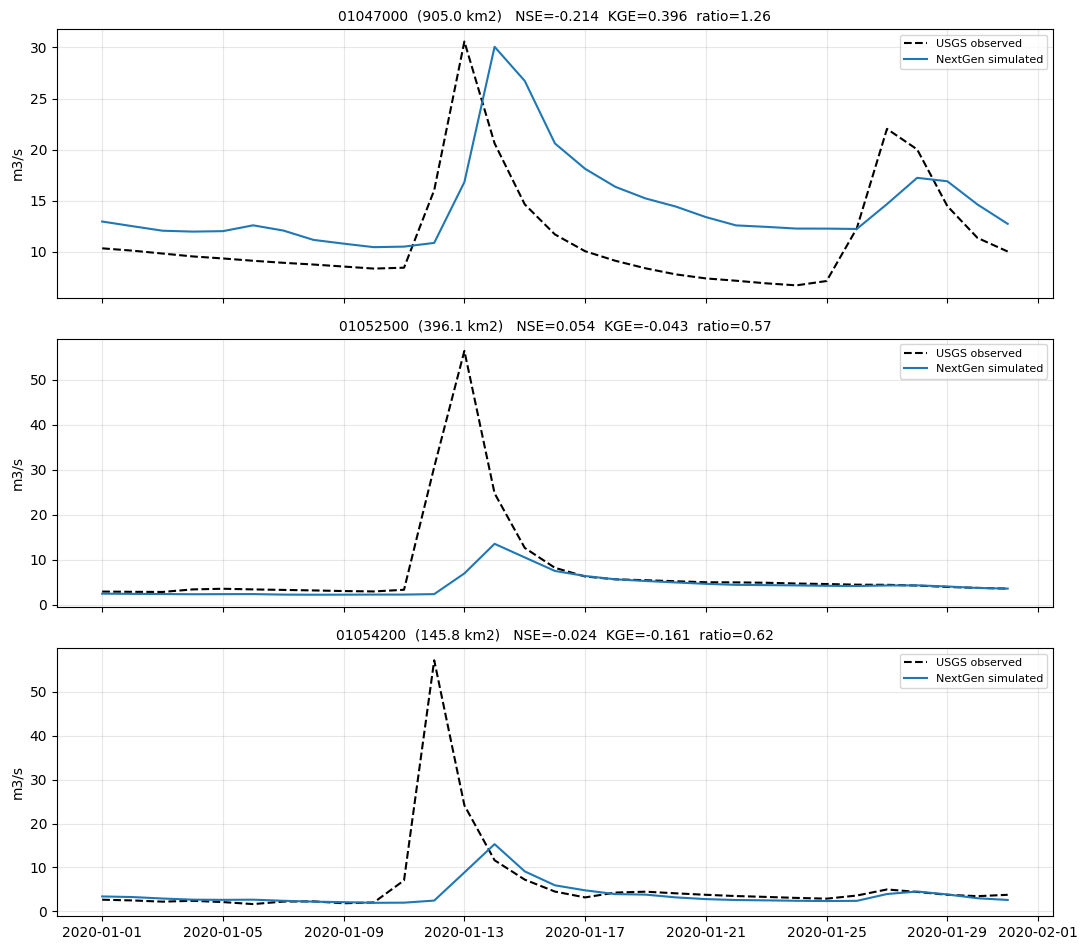

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(len(results), 1, figsize=(11, 3.2 * len(results)), sharex=True)
for ax, (m, j) in zip(np.atleast_1d(axes), results):
    ax.plot(j.index, j["obs"], "k--", lw=1.5, label="USGS observed")
    ax.plot(j.index, j["sim"], color="#1f77b4", lw=1.5, label="NextGen simulated")
    ax.set_ylabel("m3/s")
    ax.set_title(f"{m['gauge']}  ({m['area_km2']} km2)   NSE={m['NSE']}  KGE={m['KGE']}  ratio={m['ratio']}", fontsize=10)
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
pd.read_parquet("/bighome/hdagne1/usgs-streamflow-inventory/data/Final_compiled_all/ds4_nwm_retrospective.parquet")

,datetime,nwm_streamflow_cfs,site_no,nwm_feature_id
0,1979-02-01,378.220429,03265000,3984094
1,1979-02-02,373.820806,03265000,3984094
2,1979-02-03,370.215763,03265000,3984094
3,1979-02-04,365.242277,03265000,3984094
4,1979-02-05,359.327064,03265000,3984094
...,...,...,...,...
94561759,2023-01-27,177.014930,12148300,23970759
94561760,2023-01-28,172.791880,12148300,23970759
94561761,2023-01-29,168.907263,12148300,23970759
94561762,2023-01-30,165.831942,12148300,23970759


NWM rows loaded: 48213 | gauges found: ['01047000', '01052500', '01054200']


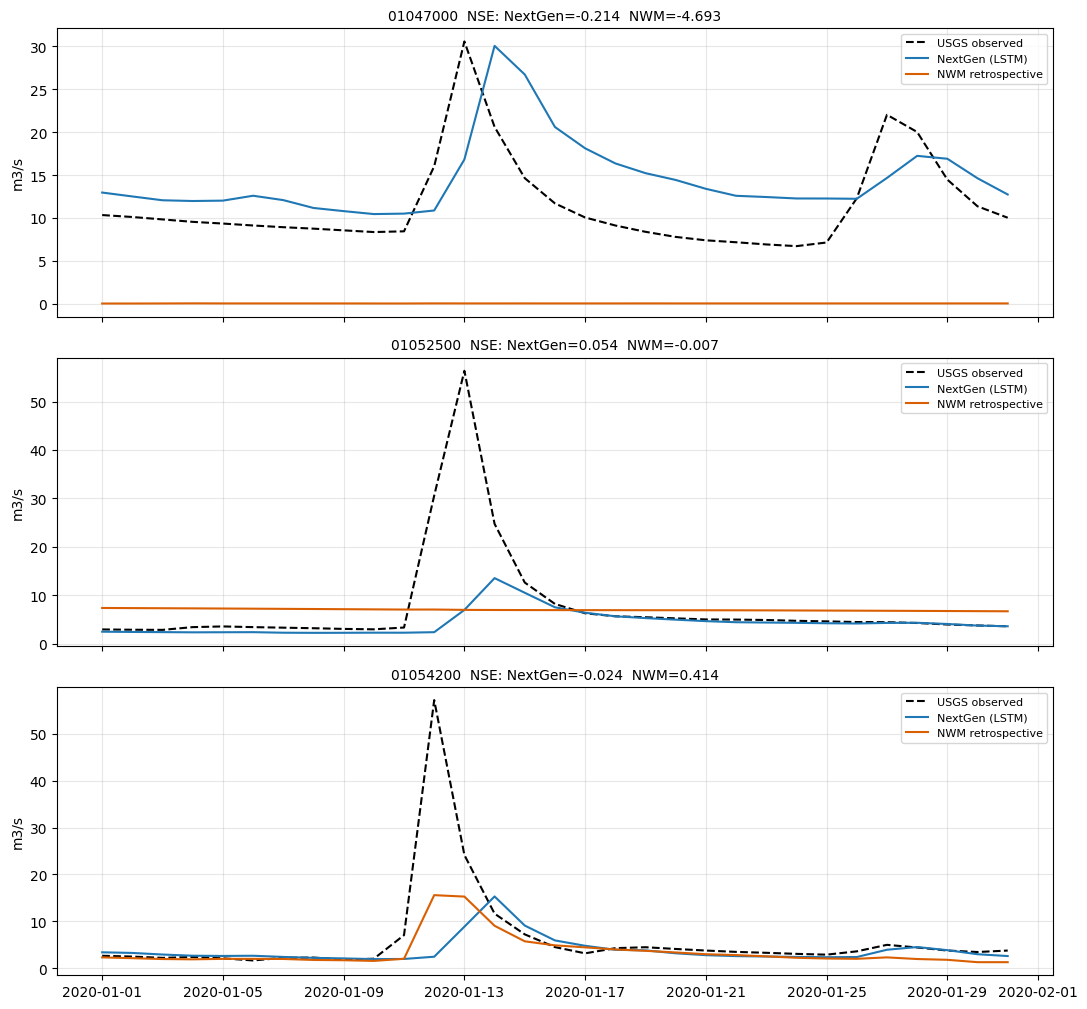

,gauge,obs_mean,ngen_mean,nwm_mean,NSE_ngen,NSE_nwm,KGE_ngen,KGE_nwm
0,01047000,11.47,14.50,0.03,-0.214,-4.693,0.396,-0.657
1,01052500,7.71,4.36,7.00,0.054,-0.007,-0.043,-0.451
2,01054200,6.13,3.82,3.57,-0.024,0.414,-0.161,0.209


In [ ]:
%matplotlib inline
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

gauges = [m["gauge"] for m, _ in results]
nwm = pd.read_parquet(
    "/bighome/hdagne1/usgs-streamflow-inventory/data/Final_compiled_all/ds4_nwm_retrospective.parquet",
    columns=["datetime", "nwm_streamflow_cfs", "site_no"],
    filters=[("site_no", "in", gauges)],
)
nwm["datetime"] = pd.to_datetime(nwm["datetime"])
nwm["nwm"] = nwm["nwm_streamflow_cfs"] * 0.0283168          # cfs -> m3/s
print("NWM rows loaded:", len(nwm), "| gauges found:", sorted(nwm["site_no"].unique()))

def skill(s, o):
    nse = 1 - ((s - o) ** 2).sum() / ((o - o.mean()) ** 2).sum()
    r_ = np.corrcoef(s, o)[0, 1]
    kge = 1 - np.sqrt((r_ - 1) ** 2 + (s.std() / o.std() - 1) ** 2 + (s.mean() / o.mean() - 1) ** 2)
    return round(nse, 3), round(kge, 3)

rows = []
fig, axes = plt.subplots(len(results), 1, figsize=(11, 3.4 * len(results)), sharex=True)
for ax, (m, j) in zip(np.atleast_1d(axes), results):
    n = nwm[nwm["site_no"] == m["gauge"]].set_index("datetime")["nwm"]
    jj = j.join(n.rename("nwm"), how="left").dropna()
    ns, ks = skill(jj["sim"].values, jj["obs"].values)
    nn, kn = skill(jj["nwm"].values, jj["obs"].values)
    rows.append(dict(gauge=m["gauge"], obs_mean=round(jj.obs.mean(), 2),
                     ngen_mean=round(jj.sim.mean(), 2), nwm_mean=round(jj.nwm.mean(), 2),
                     NSE_ngen=ns, NSE_nwm=nn, KGE_ngen=ks, KGE_nwm=kn))
    ax.plot(jj.index, jj["obs"], "k--", lw=1.5, label="USGS observed")
    ax.plot(jj.index, jj["sim"], color="#1f77b4", lw=1.5, label="NextGen (LSTM)")
    ax.plot(jj.index, jj["nwm"], color="#d95f02", lw=1.5, label="NWM retrospective")
    ax.set_ylabel("m3/s"); ax.grid(alpha=0.3); ax.legend(loc="upper right", fontsize=8)
    ax.set_title(f"{m['gauge']}  NSE: NextGen={ns}  NWM={nn}", fontsize=10)
plt.tight_layout(); plt.show()

pd.DataFrame(rows)

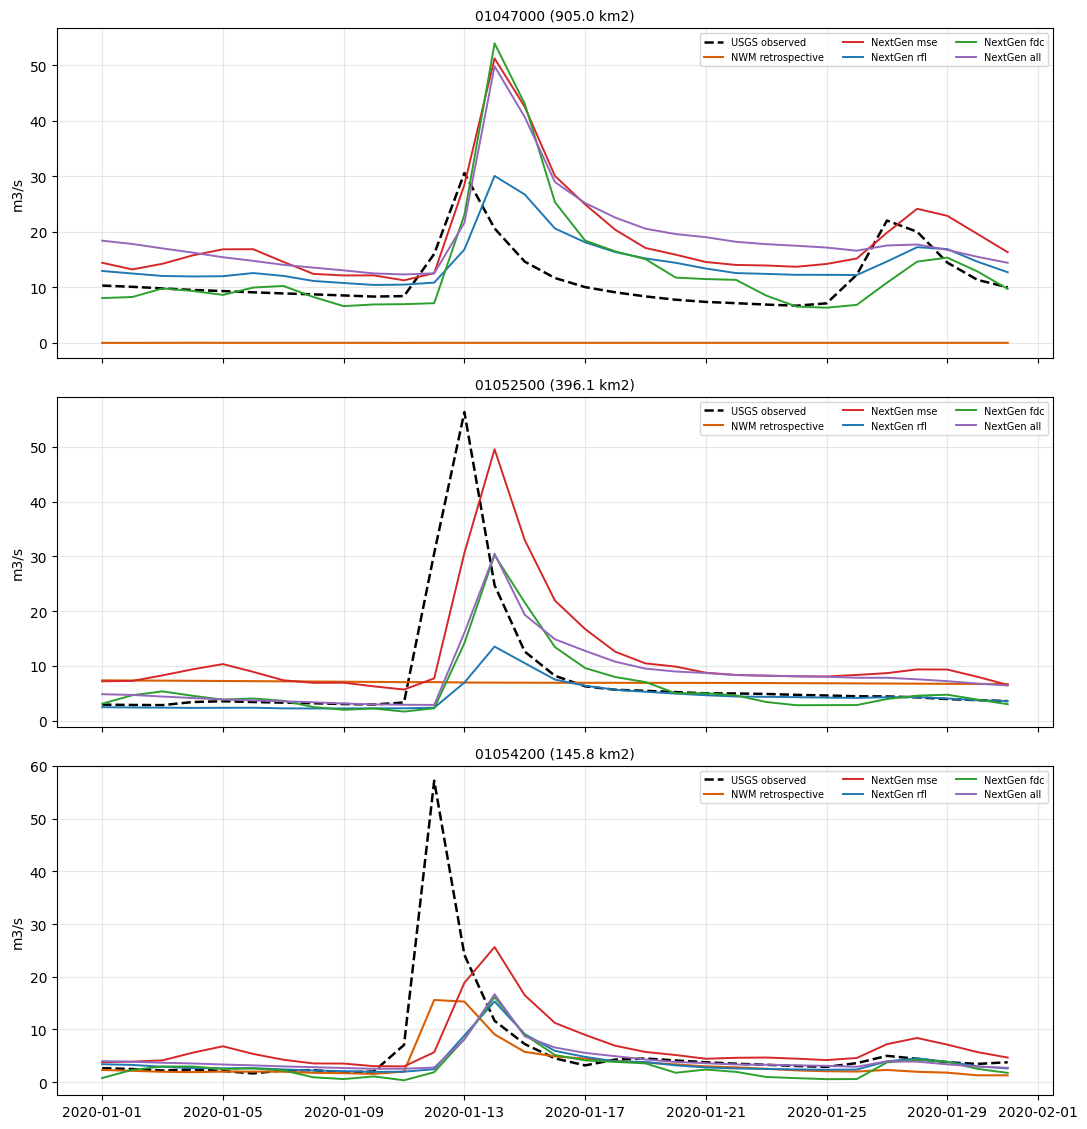

,gauge,obs_mean,nwm_mean,nwm_NSE,nwm_KGE,mse_mean,mse_NSE,mse_KGE,rfl_mean,rfl_NSE,rfl_KGE,fdc_mean,fdc_NSE,fdc_KGE,all_mean,all_NSE,all_KGE
0,01047000,11.47,0.03,-4.693,-0.657,18.90,-2.811,-0.017,14.50,-0.214,0.396,13.62,-2.084,-0.101,19.200001,-3.265,-0.046
1,01052500,7.71,7.00,-0.007,-0.451,11.91,0.153,0.319,4.36,0.054,-0.043,6.16,0.224,0.306,8.150000,0.231,0.302
2,01054200,6.13,3.57,0.414,0.209,6.82,0.011,0.088,3.82,-0.024,-0.161,3.10,-0.070,-0.181,4.280000,-0.026,-0.166


In [ ]:
%matplotlib inline
import sqlite3
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt

SCENARIOS = {"mse": "#d62728", "rfl": "#1f77b4", "fdc": "#2ca02c", "all": "#9467bd"}

def sim_daily(gauge, sc):
    gdir = Path(f"/bighome/hdagne1/Data/CAMELS_US_ngiab_full/gage-{gauge}")
    gpkg = next((gdir / "config").glob("*_subset.gpkg"))
    nc = next((gdir / "outputs" / f"troute_{sc}_stream").glob("troute_output_*.nc"))
    con = sqlite3.connect(gpkg)
    wb = con.execute('SELECT id FROM "flowpath-attributes" WHERE gage=?', (gauge,)).fetchone()[0]
    con.close()
    s = xr.open_dataset(nc)["flow"].sel(feature_id=int(wb.split("-")[1])).to_pandas()
    s.index = pd.to_datetime(s.index)
    return s.resample("1D").mean()

def skill(s, o):
    nse = 1 - ((s - o) ** 2).sum() / ((o - o.mean()) ** 2).sum()
    r_ = np.corrcoef(s, o)[0, 1]
    kge = 1 - np.sqrt((r_ - 1) ** 2 + (s.std() / o.std() - 1) ** 2 + (s.mean() / o.mean() - 1) ** 2)
    return round(nse, 3), round(kge, 3)

rows = []
fig, axes = plt.subplots(len(results), 1, figsize=(11, 3.8 * len(results)), sharex=True)
for ax, (m, j) in zip(np.atleast_1d(axes), results):
    g = m["gauge"]
    df = j[["obs"]].copy()
    df["nwm"] = nwm[nwm["site_no"] == g].set_index("datetime")["nwm"]
    for sc in SCENARIOS:
        df[sc] = sim_daily(g, sc)
    df = df.dropna()
    ax.plot(df.index, df["obs"], "k--", lw=1.8, label="USGS observed")
    ax.plot(df.index, df["nwm"], color="#d95f02", lw=1.5, label="NWM retrospective")
    row = {"gauge": g, "obs_mean": round(df.obs.mean(), 2)}
    for name in ["nwm"] + list(SCENARIOS):
        nse, kge = skill(df[name].values, df["obs"].values)
        row[f"{name}_mean"], row[f"{name}_NSE"], row[f"{name}_KGE"] = round(df[name].mean(), 2), nse, kge
        if name != "nwm":
            ax.plot(df.index, df[name], color=SCENARIOS[name], lw=1.4, label=f"NextGen {name}")
    rows.append(row)
    ax.set_ylabel("m3/s"); ax.grid(alpha=0.3); ax.legend(loc="upper right", fontsize=7, ncol=3)
    ax.set_title(f"{g} ({m['area_km2']} km2)", fontsize=10)
plt.tight_layout(); plt.show()

pd.DataFrame(rows)

In [ ]:
import glob, os, requests, numpy as np, pandas as pd, xarray as xr, geopandas as gpd, sqlite3

ROOT = "/bighome/hdagne1/Data/CAMELS_US_ngiab_full"
NWM_PQ = "/bighome/hdagne1/usgs-streamflow-inventory/data/Final_compiled_all/ds4_nwm_retrospective.parquet"
CACHE = "/bighome/hdagne1/NeuralNGEN/obs_cache"; os.makedirs(CACHE, exist_ok=True)
SCENARIOS = ["mse", "rfl", "fdc", "all"]
T0, T1 = "2018-01-01", "2023-01-31"

def gauge_dir(g):
    c = glob.glob(f"{ROOT}/*{g}")
    return c[0] if c else None

def done_gauges():
    out = []
    for d in sorted(glob.glob(f"{ROOT}/*")):
        g = os.path.basename(d)[-8:]
        if all(glob.glob(f"{d}/outputs/troute_{sc}_stream/troute_output_*.nc") for sc in SCENARIOS):
            out.append(g)
    return out

def gauge_feature(g):
    gp = glob.glob(f"{gauge_dir(g)}/config/*.gpkg") or glob.glob(f"{gauge_dir(g)}/**/*.gpkg", recursive=True)
    con = sqlite3.connect(gp[0])
    fp = pd.read_sql("select * from 'flowpath-attributes'", con); con.close()
    wb = fp.loc[fp["gage"].astype(str).str.contains(g), "id"].iloc[0]   # 'wb-N'
    return int(str(wb).split("-")[1])

def sim_daily(g, sc, feat):
    f = glob.glob(f"{gauge_dir(g)}/outputs/troute_{sc}_stream/troute_output_*.nc")[0]
    ds = xr.open_dataset(f)
    q = ds["flow"].sel(feature_id=feat).to_series()
    q.index = pd.to_datetime(q.index) if not np.issubdtype(q.index.dtype, np.datetime64) else q.index
    return q.resample("D").mean().loc[T0:T1]

def usgs_daily(g):
    cf = f"{CACHE}/{g}.csv"
    if os.path.exists(cf):
        return pd.read_csv(cf, index_col=0, parse_dates=True).iloc[:, 0]
    url = "https://api.waterdata.usgs.gov/ogcapi/v0/collections/daily/items"
    p = dict(monitoring_location_id=f"USGS-{g}", parameter_code="00060", statistic_id="00003",
             time=f"{T0}/{T1}", limit=10000, f="json")
    rows = []
    while url:
        r = requests.get(url, params=p, timeout=60); r.raise_for_status(); j = r.json()
        rows += [(x["properties"]["time"], x["properties"]["value"]) for x in j["features"]]
        url = next((l["href"] for l in j.get("links", []) if l.get("rel") == "next"), None); p = None
    s = pd.Series({pd.to_datetime(t): float(v) * 0.0283168 for t, v in rows}, name="obs").sort_index()
    s.to_csv(cf); return s

nwm_all = pd.read_parquet(NWM_PQ, columns=["datetime", "nwm_streamflow_cfs", "site_no"])
nwm_all["site_no"] = nwm_all["site_no"].astype(str).str.zfill(8)

def nwm_daily(g):
    d = nwm_all[nwm_all.site_no == g]
    s = d.set_index(pd.to_datetime(d["datetime"]))["nwm_streamflow_cfs"] * 0.0283168
    return s.resample("D").mean().loc[T0:T1]

def skill(s, o):
    d = pd.concat([s, o], axis=1).dropna(); s, o = d.iloc[:, 0], d.iloc[:, 1]
    if len(d) < 365: return np.nan, np.nan
    nse = 1 - ((s - o)**2).sum() / ((o - o.mean())**2).sum()
    r = np.corrcoef(s, o)[0, 1]; kge = 1 - np.sqrt((r-1)**2 + (s.std()/o.std()-1)**2 + (s.mean()/o.mean()-1)**2)
    return nse, kge

gs = done_gauges(); print(len(gs), "gauges with all 4 scenarios done")
rows, series = [], {}
for g in gs:
    try:
        feat = gauge_feature(g); obs = usgs_daily(g)
        sims = {sc: sim_daily(g, sc, feat) for sc in SCENARIOS}
        sims["nwm"] = nwm_daily(g); series[g] = (obs, sims)
        for k, s in sims.items():
            n, kg = skill(s, obs); rows.append(dict(gauge=g, model=k, NSE=n, KGE=kg))
    except Exception as e:
        print(g, "skipped:", repr(e)[:120])

res = pd.DataFrame(rows)
print(res.pivot(index="gauge", columns="model", values="NSE").round(2).to_string())
print("\nMEDIAN\n", res.groupby("model")[["NSE", "KGE"]].median().round(3))

49 gauges with all 4 scenarios done
model      all   fdc   mse    nwm   rfl
gauge                                  
01031500  0.13  0.16  0.20   0.61  0.18
01052500  0.12  0.08  0.13   0.21  0.08
01054200 -0.02 -0.12 -0.03   0.57 -0.07
01055000  0.03 -0.03  0.05   0.52  0.01
01057000  0.09  0.00  0.10   0.76  0.02
01073000  0.05 -0.02  0.10   0.32 -0.08
01078000  0.16  0.19  0.25   0.65  0.19
01117468  0.08  0.12  0.18   0.76  0.03
01118300  0.09  0.05  0.13   0.60 -0.05
01121000  0.00 -0.03  0.02   0.71 -0.05
01123000  0.03  0.01  0.07   0.72 -0.02
01134500  0.12  0.10  0.13   0.46  0.09
01139000  0.08  0.12  0.14  -0.63  0.08
01139800  0.01  0.03  0.07  -0.12  0.06
01162500  0.14  0.16  0.19   0.75  0.16
01170100  0.01 -0.09  0.01   0.55 -0.07
01181000  0.04 -0.16 -0.01   0.68 -0.10
01187300  0.03 -0.11  0.01   0.59 -0.08
01188000 -0.07 -0.28 -0.14   0.63 -0.28
01193500  0.05  0.00  0.07   0.69 -0.05
01208950 -0.02 -0.10 -0.00  -0.47 -0.14
01208990  0.10  0.05  0.15   0.73  0.00
0133

In [ ]:
import glob, os, sqlite3, numpy as np, pandas as pd, xarray as xr

ROOT = "/bighome/hdagne1/Data/CAMELS_US_ngiab_full"
CACHE = "/bighome/hdagne1/NeuralNGEN/obs_cache"
SCENARIOS = ["mse", "rfl", "fdc", "all"]
T0, T1 = "2018-01-01", "2023-01-31"

def gauge_dir(g):
    c = glob.glob(f"{ROOT}/*{g}")
    return c[0] if c else None

def done_gauges():
    out = []
    for d in sorted(glob.glob(f"{ROOT}/*")):
        g = os.path.basename(d)[-8:]
        if all(glob.glob(f"{d}/outputs/troute_{sc}_stream/troute_output_*.nc") for sc in SCENARIOS):
            out.append(g)
    return out

def gauge_feature(g):
    gp = glob.glob(f"{gauge_dir(g)}/config/*.gpkg") or glob.glob(f"{gauge_dir(g)}/**/*.gpkg", recursive=True)
    con = sqlite3.connect(gp[0])
    fp = pd.read_sql("select * from 'flowpath-attributes'", con); con.close()
    wb = fp.loc[fp["gage"].astype(str).str.contains(g), "id"].iloc[0]
    return int(str(wb).split("-")[1])

def sim_daily(g, sc, feat):
    f = glob.glob(f"{gauge_dir(g)}/outputs/troute_{sc}_stream/troute_output_*.nc")[0]
    ds = xr.open_dataset(f)
    q = ds["flow"].sel(feature_id=feat).to_series()
    q.index = pd.to_datetime(q.index)
    return q.resample("D").mean().loc[T0:T1]

def parts(s, o):
    d = pd.concat([s, o], axis=1).dropna(); s, o = d.iloc[:, 0], d.iloc[:, 1]
    r = np.corrcoef(s, o)[0, 1]; a = s.std() / o.std(); b = s.mean() / o.mean()
    nse = 1 - ((s - o) ** 2).sum() / ((o - o.mean()) ** 2).sum()
    kge = 1 - np.sqrt((r - 1) ** 2 + (a - 1) ** 2 + (b - 1) ** 2)
    return dict(NSE=nse, KGE=kge, r=r, alpha=a, beta=b)

rows = []
for g in done_gauges():
    try:
        feat = gauge_feature(g)
        obs = pd.read_csv(f"{CACHE}/{g}.csv", index_col=0, parse_dates=True).iloc[:, 0]
        for sc in SCENARIOS:
            rows.append(dict(gauge=g, model=sc, **parts(sim_daily(g, sc, feat), obs)))
    except Exception as e:
        print(g, "skipped:", repr(e)[:100])

R = pd.DataFrame(rows)
print("NextGen medians by model\n", R.groupby("model")[["NSE", "KGE", "r", "alpha", "beta"]].median().round(3))

tm = pd.read_csv("/bighome/hdagne1/NeuralNGEN/runs/scoring_rule_multi_mse/test_metrics.csv", dtype={"gauge": str})
tm["gauge"] = tm["gauge"].str.zfill(8)
ng = R[R.model == "mse"].set_index("gauge")[["NSE", "KGE", "r", "alpha", "beta"]].add_prefix("ngen_")
j = tm.set_index("gauge").loc[ng.index, ["NSE", "KGE", "r", "alpha", "beta"]].add_prefix("standalone_").join(ng)
print("\nSTANDALONE vs NEXTGEN (mse), median over", len(j), "gauges\n", j.median().round(3))
print("\nper gauge NSE\n", j[["standalone_NSE", "ngen_NSE"]].round(2).to_string())


NextGen medians by model
          NSE    KGE      r  alpha   beta
model                                   
all    0.078  0.041  0.314  0.348  0.764
fdc    0.031  0.170  0.333  0.557  0.875
mse    0.091  0.082  0.344  0.418  0.890
rfl    0.025  0.100  0.292  0.474  0.944

STANDALONE vs NEXTGEN (mse), median over 49 gauges
 standalone_NSE      0.246
standalone_KGE      0.227
standalone_r        0.532
standalone_alpha    0.420
standalone_beta     0.867
ngen_NSE            0.091
ngen_KGE            0.082
ngen_r              0.344
ngen_alpha          0.418
ngen_beta           0.890
dtype: float64

per gauge NSE
           standalone_NSE  ngen_NSE
gauge                             
01031500            0.32      0.20
01052500            0.25      0.13
01054200            0.20     -0.03
01055000            0.25      0.05
01057000            0.28      0.10
01073000            0.31      0.10
01078000            0.32      0.25
01117468            0.36      0.18
01118300            0.40      0.13

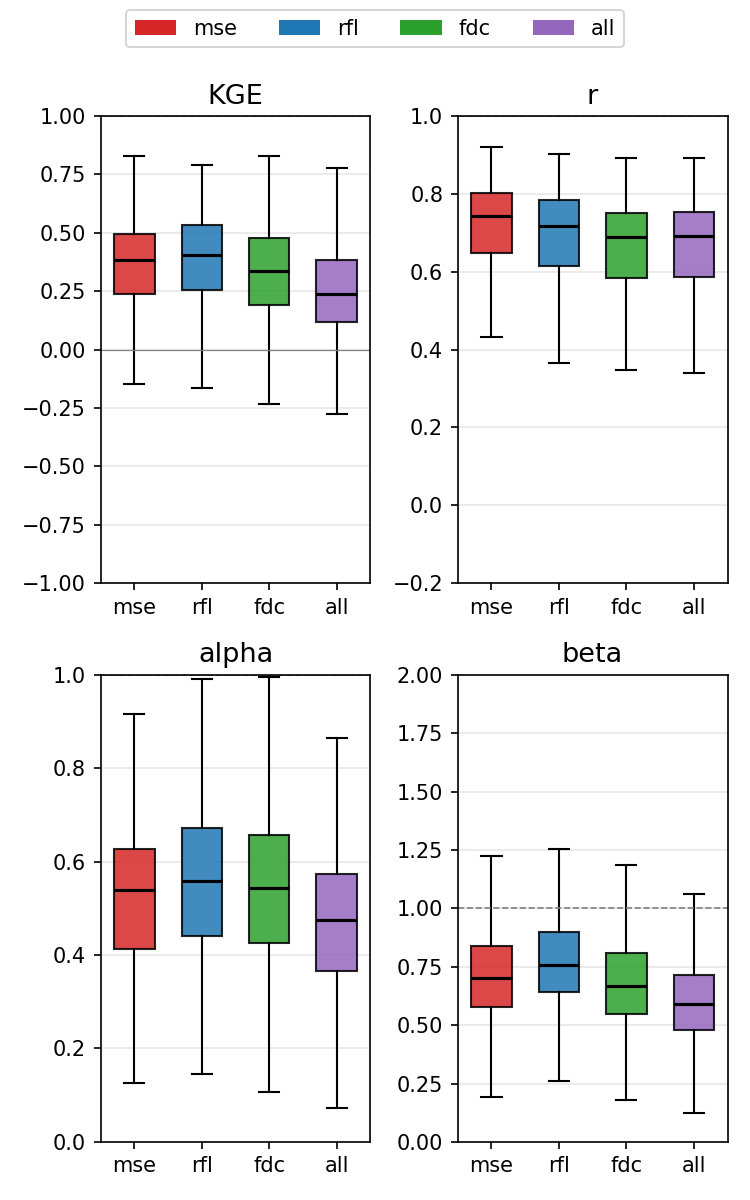

In [ ]:
%matplotlib inline
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import Image, display

RUNS = "/bighome/hdagne1/NeuralNGEN/runs"
OUT = "/bighome/hdagne1/NeuralNGEN/lstm_four_scenarios_v2.png"
SC = {"mse": "#d62728", "rfl": "#1f77b4", "fdc": "#2ca02c", "all": "#9467bd"}
METRICS = ["KGE", "r", "alpha", "beta"]
YLIM = {"KGE": (-1, 1), "r": (-0.2, 1), "alpha": (0, 1), "beta": (0, 2)}

dfs = {}
for sc in SC:
    f = f"{RUNS}/scoring_rule_multi_{sc}/test_metrics.csv"
    if not os.path.exists(f):
        print("MISSING", f); continue
    d = pd.read_csv(f, dtype={"gauge": str}); d["gauge"] = d["gauge"].str.zfill(8)
    dfs[sc] = d.set_index("gauge")

common = sorted(set.intersection(*[set(v.index) for v in dfs.values()]))

fig, axes = plt.subplots(2, 2, figsize=(5, 8))
for ax, m in zip(axes.ravel(), METRICS):
    data = [dfs[sc].loc[common, m].dropna().values for sc in dfs]
    bp = ax.boxplot(data, labels=list(dfs), patch_artist=True, showfliers=False,
                    medianprops=dict(color="k", lw=1.5), widths=0.6)
    for b, sc in zip(bp["boxes"], dfs):
        b.set_facecolor(SC[sc]); b.set_alpha(0.85)
    ax.axhline(1, color="gray", lw=0.8, ls="--")
    if m == "KGE": ax.axhline(0, color="gray", lw=0.6)
    ax.set_ylim(*YLIM[m]); ax.set_title(m, fontsize=13); ax.grid(axis="y", alpha=0.3)

# fig.suptitle(f"LSTM test performance (v2), 2018–2023 ({len(common)} gauges)", fontsize=14)
fig.legend(handles=[Patch(facecolor=SC[sc], label=sc) for sc in dfs], loc="upper center", ncol=len(dfs))
plt.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig(OUT, dpi=150)
plt.close(fig)
display(Image(OUT))

In [ ]:
import os, pandas as pd

RUNS = "/bighome/hdagne1/NeuralNGEN/runs"
cols = ["NSE", "KGE", "r", "alpha", "beta"]
rows = {}
for sc in ["mse", "rfl", "fdc", "all"]:
    for ver, suf in [("v1", ""), ("v2", "_v2")]:
        f = f"{RUNS}/scoring_rule_multi_{sc}{suf}_v2/test_metrics.csv"
        if os.path.exists(f):
            d = pd.read_csv(f)
            rows[(sc, ver)] = d[cols].median()
        else:
            print("not ready:", f)
print(pd.DataFrame(rows).T.round(3))

not ready: /bighome/hdagne1/NeuralNGEN/runs/scoring_rule_multi_mse_v2_v2/test_metrics.csv
not ready: /bighome/hdagne1/NeuralNGEN/runs/scoring_rule_multi_rfl_v2_v2/test_metrics.csv
not ready: /bighome/hdagne1/NeuralNGEN/runs/scoring_rule_multi_fdc_v2_v2/test_metrics.csv
not ready: /bighome/hdagne1/NeuralNGEN/runs/scoring_rule_multi_all_v2_v2/test_metrics.csv
          NSE    KGE      r  alpha   beta
mse v1  0.291  0.258  0.601  0.428  0.794
rfl v1  0.231  0.147  0.585  0.319  0.721
fdc v1  0.276  0.286  0.574  0.497  0.774
all v1  0.225  0.178  0.555  0.408  0.707


In [ ]:
import glob, os, pandas as pd

RUNS = "/bighome/hdagne1/NeuralNGEN/runs"
cols = ["NSE", "KGE", "r", "alpha", "beta"]
rows = {}
for f in sorted(glob.glob(f"{RUNS}/scoring_rule_multi_*/test_metrics.csv")):
    name = os.path.basename(os.path.dirname(f)).replace("scoring_rule_multi_", "")
    rows[name] = pd.read_csv(f)[cols].median()
tbl = pd.DataFrame(rows).T
tbl["modified"] = [pd.Timestamp(os.path.getmtime(f"{RUNS}/scoring_rule_multi_{n}/test_metrics.csv"), unit="s").strftime("%m-%d %H:%M") for n in tbl.index]
print(tbl.round(3).sort_values("modified").to_string())

          NSE    KGE      r  alpha   beta     modified
all     0.154  0.049  0.500  0.308  0.639  09-27 22:40
fdc     0.189  0.185  0.494  0.446  0.727  09-27 22:40
rfl     0.195  0.165  0.500  0.385  0.797  09-27 22:40
mse     0.193  0.118  0.534  0.322  0.701  10-06 01:07
all_v2  0.225  0.178  0.555  0.408  0.707  10-08 04:40
fdc_v2  0.276  0.286  0.574  0.497  0.774  10-08 04:57
mse_v2  0.291  0.258  0.601  0.428  0.794  10-08 09:03
rfl_v2  0.231  0.147  0.585  0.319  0.721  10-08 10:49


In [ ]:
import glob, os, pandas as pd

RUNS = "/bighome/hdagne1/NeuralNGEN/runs"
cols = ["NSE", "KGE", "r", "alpha", "beta"]
rows = {}
for f in sorted(glob.glob(f"{RUNS}/scoring_rule_multi_*/test_metrics.csv")):
    name = os.path.basename(os.path.dirname(f)).replace("scoring_rule_multi_", "")
    rows[name] = pd.read_csv(f)[cols].median()
tbl = pd.DataFrame(rows).T
tbl["modified"] = [pd.Timestamp(os.path.getmtime(f"{RUNS}/scoring_rule_multi_{n}/test_metrics.csv"), unit="s").strftime("%m-%d %H:%M") for n in tbl.index]
print(tbl.round(3).sort_values("modified").to_string())

                   NSE    KGE      r  alpha   beta     modified
all              0.154  0.049  0.500  0.308  0.639  09-27 22:40
fdc              0.189  0.185  0.494  0.446  0.727  09-27 22:40
rfl              0.195  0.165  0.500  0.385  0.797  09-27 22:40
mse              0.193  0.118  0.534  0.322  0.701  10-06 01:07
all_v2_oldtrain  0.225  0.178  0.555  0.408  0.707  10-08 04:40
fdc_v2_oldtrain  0.276  0.286  0.574  0.497  0.774  10-08 04:57
mse_v2_oldtrain  0.291  0.258  0.601  0.428  0.794  10-08 09:03
rfl_v2_oldtrain  0.231  0.147  0.585  0.319  0.721  10-08 10:49
rfl_v2           0.431  0.404  0.717  0.559  0.757  10-08 18:36
all_v2           0.332  0.239  0.691  0.474  0.590  10-08 20:23


In [ ]:
import glob, os, pandas as pd

RUNS = "/bighome/hdagne1/NeuralNGEN/runs"
cols = ["NSE", "KGE", "r", "alpha", "beta"]
rows = {}
for f in sorted(glob.glob(f"{RUNS}/scoring_rule_multi_*/test_metrics.csv")):
    name = os.path.basename(os.path.dirname(f)).replace("scoring_rule_multi_", "")
    rows[name] = pd.read_csv(f)[cols].median()
tbl = pd.DataFrame(rows).T
tbl["modified"] = [pd.Timestamp(os.path.getmtime(f"{RUNS}/scoring_rule_multi_{n}/test_metrics.csv"), unit="s").strftime("%m-%d %H:%M") for n in tbl.index]
print(tbl.round(3).sort_values("modified").to_string())

                   NSE    KGE      r  alpha   beta     modified
all              0.154  0.049  0.500  0.308  0.639  09-27 22:40
fdc              0.189  0.185  0.494  0.446  0.727  09-27 22:40
rfl              0.195  0.165  0.500  0.385  0.797  09-27 22:40
mse              0.193  0.118  0.534  0.322  0.701  10-06 01:07
all_v2_oldtrain  0.225  0.178  0.555  0.408  0.707  10-08 04:40
fdc_v2_oldtrain  0.276  0.286  0.574  0.497  0.774  10-08 04:57
mse_v2_oldtrain  0.291  0.258  0.601  0.428  0.794  10-08 09:03
rfl_v2_oldtrain  0.231  0.147  0.585  0.319  0.721  10-08 10:49
rfl_v2           0.431  0.404  0.717  0.559  0.757  10-08 18:36
all_v2           0.332  0.239  0.691  0.474  0.590  10-08 20:23
mse_v2           0.448  0.382  0.744  0.539  0.703  10-09 07:52
fdc_v2           0.369  0.336  0.688  0.544  0.669  10-09 08:40


In [45]:
import glob, os, sqlite3, subprocess, numpy as np, pandas as pd, xarray as xr

ROOT = "/bighome/hdagne1/Data/CAMELS_US_ngiab_full"
CACHE = "/bighome/hdagne1/NeuralNGEN/obs_cache"
MAN = "/bighome/hdagne1/NeuralNGEN/manifests/ngen_run_manifest.txt"
SCENARIOS = ["mse", "rfl", "fdc", "all"]
T0, T1 = "2018-01-01", "2023-01-31"
t_man = os.path.getmtime(MAN)

print(subprocess.run("sacct -j 58015480 -X -n -o State%12 | sort | uniq -c",
                     shell=True, capture_output=True, text=True).stdout)

def fresh_nc(d, sc):
    fs = [f for f in glob.glob(f"{d}/outputs/troute_{sc}_stream/troute_output_*.nc")
          if os.path.getmtime(f) > t_man]
    return fs[0] if fs else None

def feature(d, g):
    gp = glob.glob(f"{d}/config/*.gpkg") or glob.glob(f"{d}/**/*.gpkg", recursive=True)
    con = sqlite3.connect(gp[0]); fp = pd.read_sql("select * from 'flowpath-attributes'", con); con.close()
    return int(str(fp.loc[fp["gage"].astype(str).str.contains(g), "id"].iloc[0]).split("-")[1])

def daily(f, feat):
    q = xr.open_dataset(f)["flow"].sel(feature_id=feat).to_series()
    q.index = pd.to_datetime(q.index)
    return q.resample("D").mean().loc[T0:T1]

def skill(s, o):
    d = pd.concat([s, o], axis=1).dropna(); s, o = d.iloc[:, 0], d.iloc[:, 1]
    r = np.corrcoef(s, o)[0, 1]; a = s.std() / o.std(); b = s.mean() / o.mean()
    return dict(NSE=1 - ((s - o) ** 2).sum() / ((o - o.mean()) ** 2).sum(),
                KGE=1 - np.sqrt((r - 1) ** 2 + (a - 1) ** 2 + (b - 1) ** 2))

rows = []
for d in sorted(glob.glob(f"{ROOT}/*")):
    g = os.path.basename(d)[-8:]
    fs = {sc: fresh_nc(d, sc) for sc in SCENARIOS}
    if not all(fs.values()) or not os.path.exists(f"{CACHE}/{g}.csv"):
        continue
    try:
        feat = feature(d, g)
        obs = pd.read_csv(f"{CACHE}/{g}.csv", index_col=0, parse_dates=True).iloc[:, 0]
        for sc in SCENARIOS:
            rows.append(dict(gauge=g, model=sc, **skill(daily(fs[sc], feat), obs)))
    except Exception as e:
        print(g, "skipped:", repr(e)[:100])

R = pd.DataFrame(rows)
print("gauges with all 4 scenarios:", R.gauge.nunique() if len(R) else 0)
if len(R):
    print(R.groupby("model")[["NSE", "KGE"]].median().loc[SCENARIOS].round(3))

   1431    COMPLETED 
      1    PREEMPTED 

gauges with all 4 scenarios: 298
         NSE    KGE
model              
mse    0.160  0.308
rfl    0.090  0.230
fdc    0.079  0.214
all    0.101  0.169


In [47]:
%matplotlib inline
import glob, os, sqlite3
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt

ROOT = "/bighome/hdagne1/Data/CAMELS_US_ngiab_full"
CACHE = "/bighome/hdagne1/NeuralNGEN/obs_cache"
MAN = "/bighome/hdagne1/NeuralNGEN/manifests/ngen_run_manifest.txt"
SCENARIOS = {"mse": "#d62728", "rfl": "blue", "fdc": "darkgreen", "all": "gray"}
T0, T1 = "2019-01-01", "2019-12-31"          # full period: table, regime, FDC
P0, P1 = "2019-01-01", "2019-05-31"         # hydrograph window only
MAX_PLOTS = 8
t_man = os.path.getmtime(MAN)
HAS_NWM = "nwm" in globals()
MONTHS = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]

if not HAS_NWM:
    raise RuntimeError("`nwm` DataFrame is not in memory - run the cell that loads it first.")

def fresh_nc(d, sc):
    fs = [f for f in glob.glob(f"{d}/outputs/troute_{sc}_stream/troute_output_*.nc")
          if os.path.getmtime(f) > t_man]
    return fs[0] if fs else None

def feature(d, g):
    gp = glob.glob(f"{d}/config/*.gpkg") or glob.glob(f"{d}/**/*.gpkg", recursive=True)
    con = sqlite3.connect(gp[0])
    fp = pd.read_sql("select * from 'flowpath-attributes'", con); con.close()
    return int(str(fp.loc[fp["gage"].astype(str).str.contains(g), "id"].iloc[0]).split("-")[1])

def sim_daily(f, feat):
    s = xr.open_dataset(f)["flow"].sel(feature_id=feat).to_series()
    s.index = pd.to_datetime(s.index)
    return s.resample("1D").mean().loc[T0:T1]

def skill(s, o):
    nse = 1 - ((s - o) ** 2).sum() / ((o - o.mean()) ** 2).sum()
    r = np.corrcoef(s, o)[0, 1]
    kge = 1 - np.sqrt((r - 1) ** 2 + (s.std() / o.std() - 1) ** 2 + (s.mean() / o.mean() - 1) ** 2)
    return round(nse, 3), round(kge, 3)

nwm_sites = set(nwm["site_no"].astype(str).str.zfill(8))

data = {}
for d in sorted(glob.glob(f"{ROOT}/*")):
    g = os.path.basename(d)[-8:]
    if g not in nwm_sites:                       # only basins where NWM is available
        continue
    fs = {sc: fresh_nc(d, sc) for sc in SCENARIOS}
    if not all(fs.values()) or not os.path.exists(f"{CACHE}/{g}.csv"):
        continue
    try:
        feat = feature(d, g)
        df = pd.DataFrame({"obs": pd.read_csv(f"{CACHE}/{g}.csv", index_col=0, parse_dates=True).iloc[:, 0]})
        for sc in SCENARIOS:
            df[sc] = sim_daily(fs[sc], feat)
        n = nwm[nwm["site_no"].astype(str).str.zfill(8) == g]
        df["nwm"] = n.set_index("datetime")["nwm"]
        df = df.loc[T0:T1].dropna()
        if len(df):
            data[g] = df
    except Exception as e:
        print(g, "skipped:", repr(e)[:100])

print("gauges with all 4 scenarios + NWM:", len(data))

# ---- table (full period)
rows = []
for g, df in data.items():
    row = {"gauge": g, "obs_mean": round(df.obs.mean(), 2)}
    for name in (["nwm"] if "nwm" in df else []) + list(SCENARIOS):
        nse, kge = skill(df[name].values, df["obs"].values)
        row[f"{name}_mean"], row[f"{name}_NSE"], row[f"{name}_KGE"] = round(df[name].mean(), 2), nse, kge
    rows.append(row)

# ---- plots: one figure per gauge, 3 panels (width ratios: hydrograph wider)
def series_styles(df):
    st = [("obs", "USGS observed", "k", "--", 1.8)]
    if "nwm" in df:
        st.append(("nwm", "NWM", "magenta", "-", 1.5))
    st += [(sc, f"NextGen {sc}", c, "-", 1.4) for sc, c in SCENARIOS.items()]
    return st

for g in list(data)[:MAX_PLOTS]:
    df = data[g]
    st = series_styles(df)
    fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(20, 6),
                                     gridspec_kw={"width_ratios": [2.4, 1, 1]})
    # hydrograph
    dp = df.loc[P0:P1]
    for col, lab, c, ls, lw in st:
        a1.plot(dp.index, dp[col], color=c, ls=ls, lw=lw, label=lab)
    a1.set_ylabel("Streamflow (m3/s)"); a1.set_title(f"{g} - hydrograph", fontsize=11)
    a1.legend(loc="upper right", fontsize=11, ncol=2, frameon=False)
    # regime (mean by calendar month)
    for col, lab, c, ls, lw in st:
        m = df[col].groupby(df.index.month).mean()
        a2.plot(m.index, m.values, color=c, ls=ls, lw=lw, marker="o", ms=3)
    a2.set_xticks(range(1, 13)); a2.set_xticklabels(MONTHS)
    a2.set_ylabel("Mean monthly flow (m3/s)"); a2.set_title("Regime curve", fontsize=11)
    # flow duration curve
    for col, lab, c, ls, lw in st:
        v = np.sort(df[col].values)[::-1]
        p = np.arange(1, len(v) + 1) / (len(v) + 1) * 100
        a3.plot(p, v, color=c, ls=ls, lw=lw)
    a3.set_yscale("log"); a3.set_xlim(0, 100)
    a3.set_xlabel("Exceedance probability (%)"); a3.set_ylabel("Streamflow (m3/s)")
    a3.set_title("Flow duration curve", fontsize=11)
    for a in (a1, a2, a3):
        a.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

# T = pd.DataFrame(rows)
# pd.set_option("display.width", 250, "display.max_columns", 50)
# print(T.to_string(index=False))
# print("\nMedians:")
# print(T.filter(regex="_NSE$|_KGE$").median().round(3))

RuntimeError: `nwm` DataFrame is not in memory - run the cell that loads it first.

candidates (4 scenarios + obs): 298
candidates with NWM: 281
gauges available: 280

Top 4 gauges by KGE (rank by: mean)
          obs_mean  nwm_NSE  nwm_KGE  mse_NSE  mse_KGE  rfl_NSE  rfl_KGE  fdc_NSE  fdc_KGE  all_NSE  all_KGE
gauge                                                                                                       
06224000      8.69   -0.453   -0.664    0.666    0.601    0.714    0.702    0.833    0.694    0.864    0.888
06309200      0.92    0.820    0.862    0.580    0.787    0.534    0.760    0.591    0.541    0.587    0.640
06632400      2.25    0.860    0.689    0.677    0.422    0.810    0.648    0.795    0.712    0.837    0.918
02296500      6.65    0.755    0.720    0.784    0.539    0.666    0.639    0.613    0.790    0.664    0.695


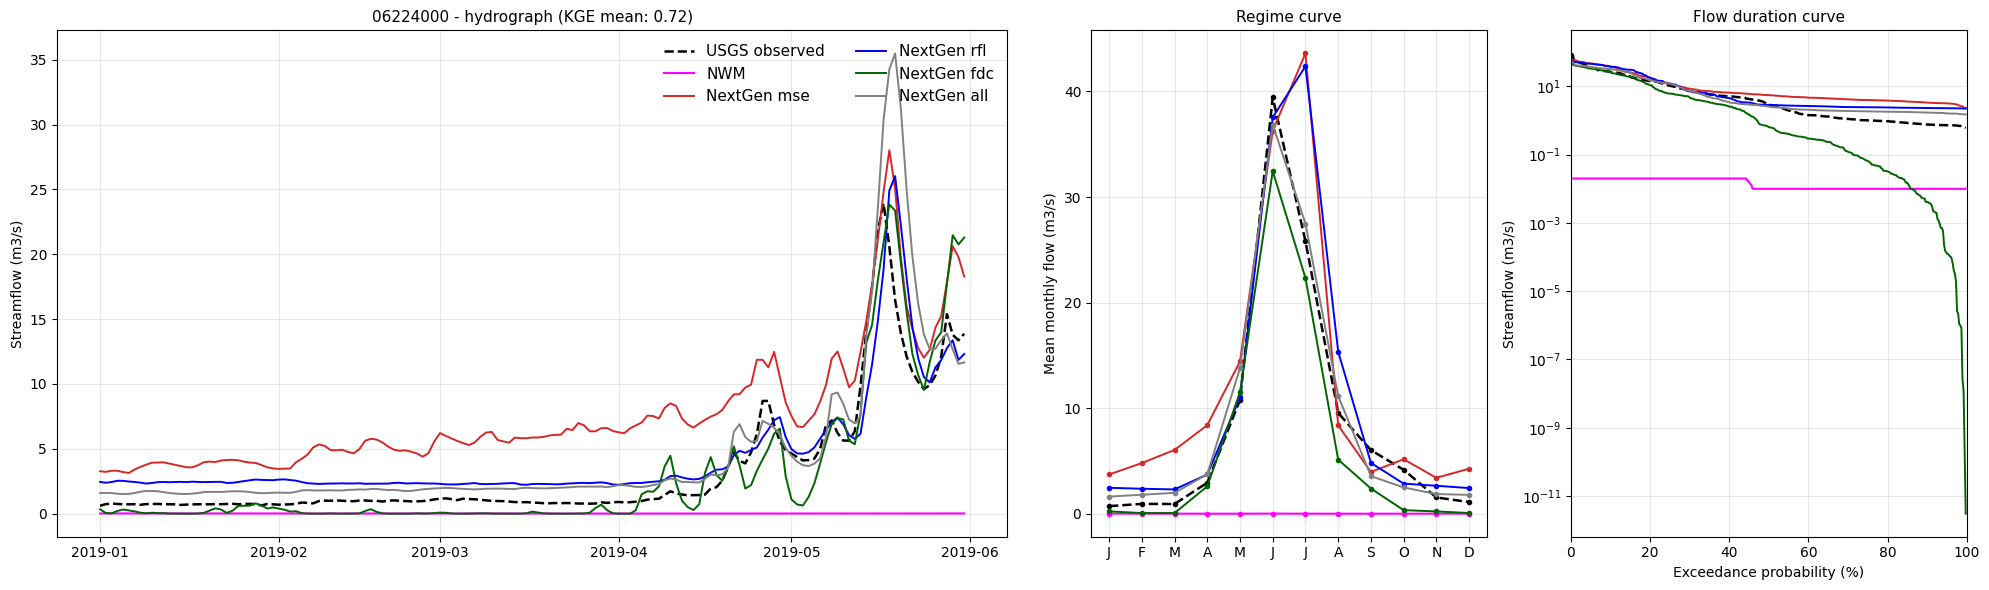

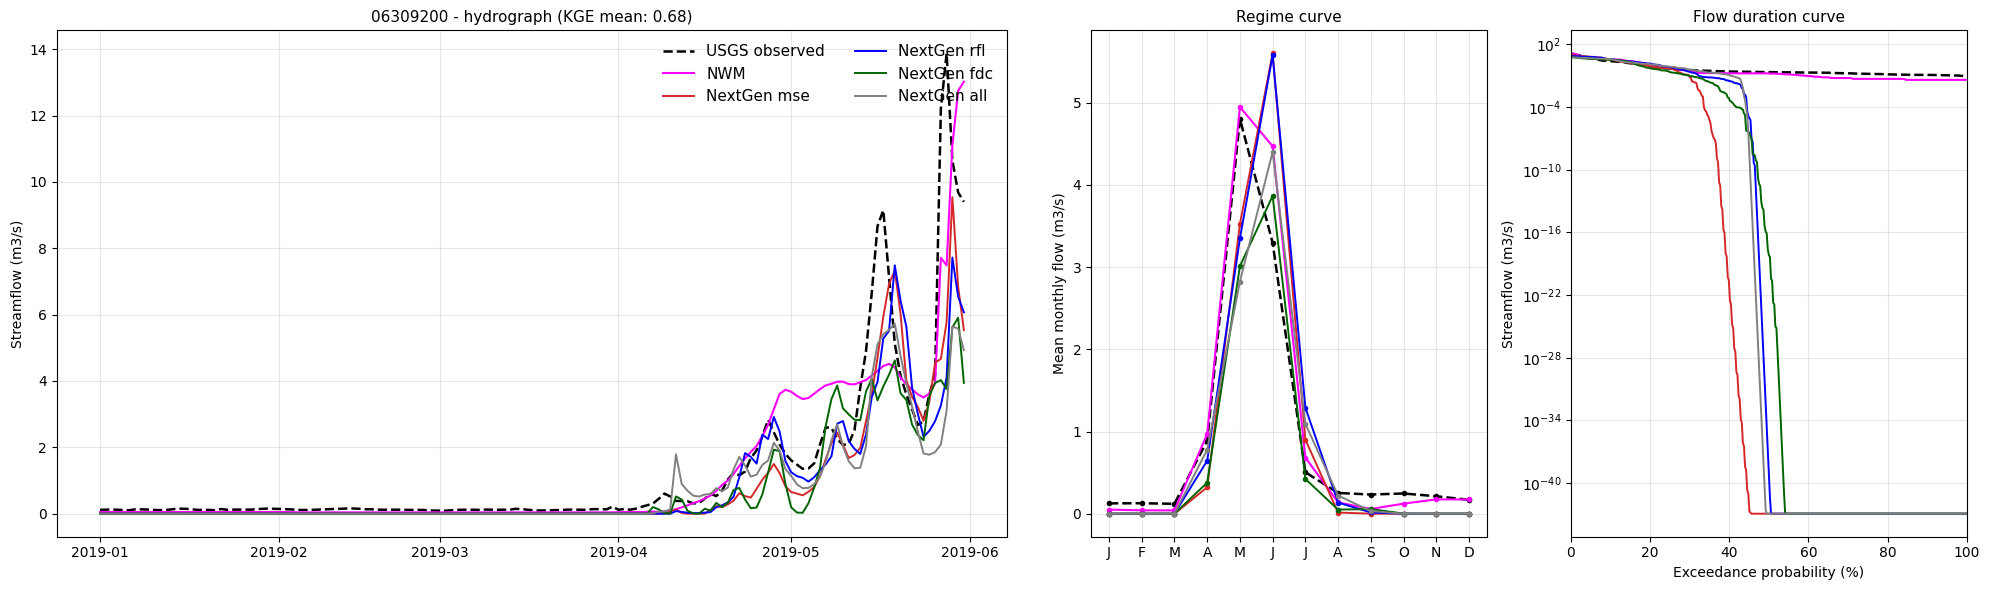

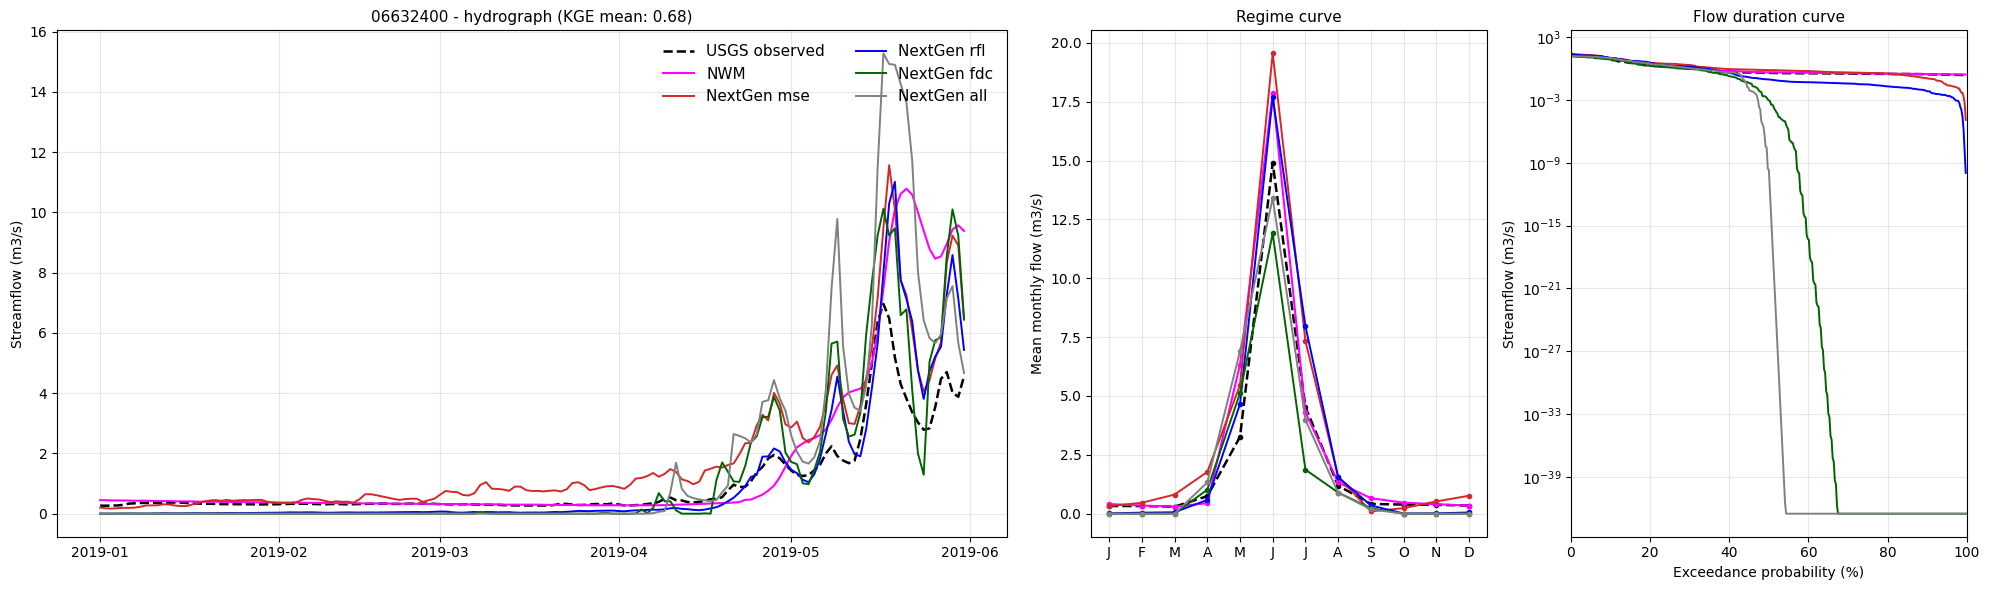

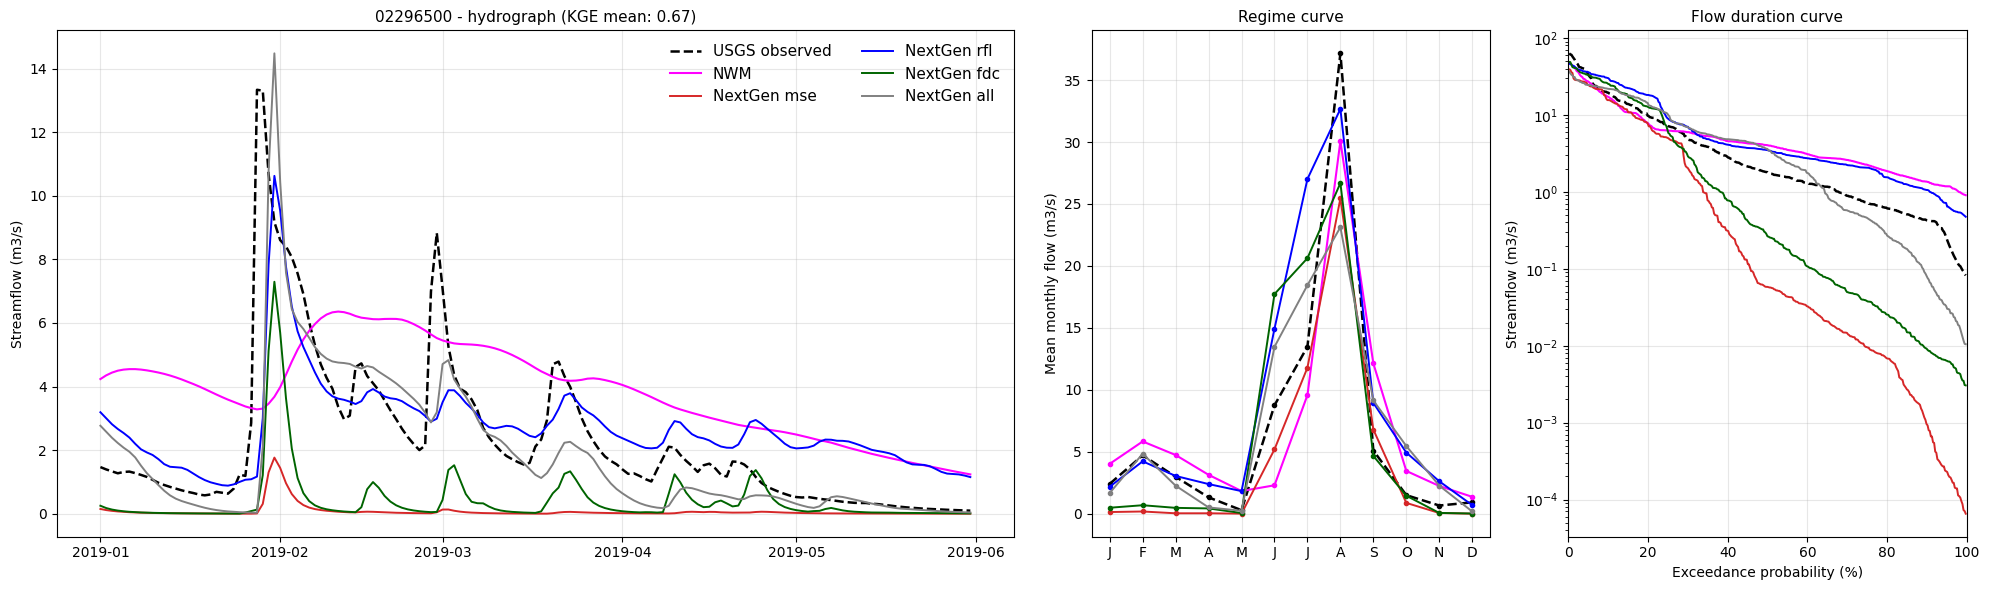

In [48]:
%matplotlib inline
import glob, os, sqlite3
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
import pyarrow as pa, pyarrow.dataset as pads, pyarrow.compute as pc

ROOT = "/bighome/hdagne1/Data/CAMELS_US_ngiab_full"
CACHE = "/bighome/hdagne1/NeuralNGEN/obs_cache"
MAN = "/bighome/hdagne1/NeuralNGEN/manifests/ngen_run_manifest.txt"
NWM_PQ = "/bighome/hdagne1/usgs-streamflow-inventory/data/Final_compiled_all/ds4_nwm_retrospective.parquet"
SCENARIOS = {"mse": "#d62728", "rfl": "blue", "fdc": "darkgreen", "all": "gray"}
T0, T1 = "2019-01-01", "2019-12-31"          # full period: ranking, regime, FDC
P0, P1 = "2019-01-01", "2019-05-31"          # hydrograph window only
TOP_N = 4
RANK_BY = "mean"                             # "mean" | "max" | "mse" | "rfl" | "fdc" | "all"
MONTHS = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]
t_man = os.path.getmtime(MAN)

def fresh_nc(d, sc):
    fs = [f for f in glob.glob(f"{d}/outputs/troute_{sc}_stream/troute_output_*.nc")
          if os.path.getmtime(f) > t_man]
    return fs[0] if fs else None

def feature(d, g):
    gp = glob.glob(f"{d}/config/*.gpkg") or glob.glob(f"{d}/**/*.gpkg", recursive=True)
    con = sqlite3.connect(gp[0])
    wb = con.execute('SELECT id FROM "flowpath-attributes" WHERE gage LIKE ? LIMIT 1', (f"%{g}%",)).fetchone()[0]
    con.close()
    return int(str(wb).split("-")[1])

def sim_daily(f, feat):
    with xr.open_dataset(f) as ds:
        s = ds["flow"].sel(feature_id=feat).to_series()
    s.index = pd.to_datetime(s.index)
    return s.resample("1D").mean().loc[T0:T1]

def skill(s, o):
    nse = 1 - ((s - o) ** 2).sum() / ((o - o.mean()) ** 2).sum()
    r = np.corrcoef(s, o)[0, 1]
    kge = 1 - np.sqrt((r - 1) ** 2 + (s.std() / o.std() - 1) ** 2 + (s.mean() / o.mean() - 1) ** 2)
    return round(nse, 3), round(kge, 3)

# ---- 1) candidates: all 4 scenarios finished + cached USGS obs
cand = {}
for d in sorted(glob.glob(f"{ROOT}/*")):
    g = os.path.basename(d)[-8:]
    if not os.path.exists(f"{CACHE}/{g}.csv"):
        continue
    fs = {sc: fresh_nc(d, sc) for sc in SCENARIOS}
    if all(fs.values()):
        cand[g] = (d, fs)
print("candidates (4 scenarios + obs):", len(cand))

# ---- 2) NWM for candidate gauges only
dset = pads.dataset(NWM_PQ)
typ = dset.schema.field("site_no").type
vals = ([int(g) for g in cand] if pa.types.is_integer(typ)
        else sorted({g for g in cand} | {g.lstrip("0") for g in cand}))
nw = dset.to_table(columns=["datetime", "nwm_streamflow_cfs", "site_no"],
                   filter=pc.field("site_no").isin(vals)).to_pandas()
nw["site_no"] = nw["site_no"].astype(str).str.zfill(8)
nw["datetime"] = pd.to_datetime(nw["datetime"])
nw = nw[(nw.datetime >= T0) & (nw.datetime <= pd.Timestamp(T1) + pd.Timedelta(days=1))]
nw["nwm"] = nw["nwm_streamflow_cfs"] * 0.0283168                 # cfs -> m3/s
nwm_d = {g: x.set_index("datetime")["nwm"].resample("1D").mean() for g, x in nw.groupby("site_no")}
print("candidates with NWM:", len(set(nwm_d) & set(cand)))

# ---- 3) per-gauge frames
data = {}
for g, (d, fs) in cand.items():
    if g not in nwm_d:
        continue
    try:
        feat = feature(d, g)
        df = pd.DataFrame({"obs": pd.read_csv(f"{CACHE}/{g}.csv", index_col=0, parse_dates=True).iloc[:, 0]})
        for sc in SCENARIOS:
            df[sc] = sim_daily(fs[sc], feat)
        df["nwm"] = nwm_d[g]
        df = df.loc[T0:T1].dropna()
        if len(df) > 30:
            data[g] = df
    except Exception as e:
        print(g, "skipped:", repr(e)[:100])
print("gauges available:", len(data))

# ---- 4) skill table for all gauges, rank by KGE
rows = []
for g, df in data.items():
    row = {"gauge": g, "obs_mean": round(df.obs.mean(), 2)}
    for name in ["nwm"] + list(SCENARIOS):
        nse, kge = skill(df[name].values, df["obs"].values)
        row[f"{name}_NSE"], row[f"{name}_KGE"] = nse, kge
    rows.append(row)
T = pd.DataFrame(rows).set_index("gauge")

kcols = [f"{sc}_KGE" for sc in SCENARIOS]
score = (T[kcols].mean(axis=1) if RANK_BY == "mean" else
         T[kcols].max(axis=1) if RANK_BY == "max" else T[f"{RANK_BY}_KGE"])
top = score.sort_values(ascending=False).head(TOP_N).index.tolist()

pd.set_option("display.width", 250, "display.max_columns", 50)
print(f"\nTop {TOP_N} gauges by KGE (rank by: {RANK_BY})")
print(T.loc[top, ["obs_mean"] + [c for c in T.columns if c.endswith("KGE") or c.endswith("NSE")]].to_string())

# ---- 5) plots: top gauges only
ST = ([("obs", "USGS observed", "k", "--", 1.8), ("nwm", "NWM", "magenta", "-", 1.5)]
      + [(sc, f"NextGen {sc}", c, "-", 1.4) for sc, c in SCENARIOS.items()])

for g in top:
    df = data[g]
    fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(20, 6),
                                     gridspec_kw={"width_ratios": [2.4, 1, 1]})
    dp = df.loc[P0:P1]
    mon = df.groupby(df.index.month).mean()
    for col, lab, c, ls, lw in ST:
        a1.plot(dp.index, dp[col], color=c, ls=ls, lw=lw, label=lab)
        a2.plot(mon.index, mon[col], color=c, ls=ls, lw=lw, marker="o", ms=3)
        v = np.sort(df[col].values)[::-1]
        a3.plot(np.arange(1, len(v) + 1) / (len(v) + 1) * 100, v, color=c, ls=ls, lw=lw)
    a1.set_ylabel("Streamflow (m3/s)")
    a1.set_title(f"{g} - hydrograph (KGE {RANK_BY}: {score[g]:.2f})", fontsize=11)
    a1.legend(loc="upper right", fontsize=11, ncol=2, frameon=False)
    a2.set_xticks(range(1, 13)); a2.set_xticklabels(MONTHS)
    a2.set_ylabel("Mean monthly flow (m3/s)"); a2.set_title("Regime curve", fontsize=11)
    a3.set_yscale("log"); a3.set_xlim(0, 100)
    a3.set_xlabel("Exceedance probability (%)"); a3.set_ylabel("Streamflow (m3/s)")
    a3.set_title("Flow duration curve", fontsize=11)
    for a in (a1, a2, a3):
        a.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

gauges with 4 scenarios + obs: 298
gauges in boxplots: 280


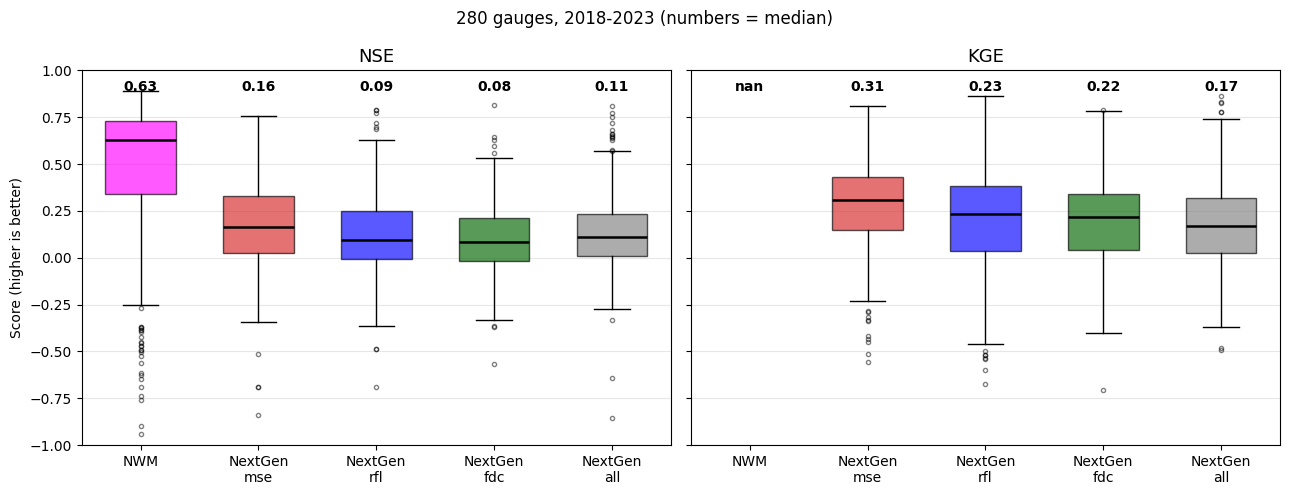

         NSE    KGE
model              
NWM    0.629  0.770
mse    0.163  0.310
rfl    0.093  0.233
fdc    0.082  0.217
all    0.109  0.172

Below axis limit (clipped from view):
       NSE_lo  KGE_lo
model                
NWM        12       5
mse         1       0
rfl         1       0
fdc         2       0
all         0       0


In [49]:
%matplotlib inline
import glob, os, sqlite3
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
import pyarrow as pa, pyarrow.dataset as pads, pyarrow.compute as pc

ROOT = "/bighome/hdagne1/Data/CAMELS_US_ngiab_full"
CACHE = "/bighome/hdagne1/NeuralNGEN/obs_cache"
MAN = "/bighome/hdagne1/NeuralNGEN/manifests/ngen_run_manifest.txt"
NWM_PQ = "/bighome/hdagne1/usgs-streamflow-inventory/data/Final_compiled_all/ds4_nwm_retrospective.parquet"
OUT = "/bighome/hdagne1/NeuralNGEN/ngen_boxplots.png"
SCENARIOS = {"mse": "#d62728", "rfl": "blue", "fdc": "darkgreen", "all": "gray"}
COLORS = {"NWM": "magenta", **SCENARIOS}
T0, T1 = "2018-01-01", "2023-01-31"
MIN_DAYS = 365
YLIM = (-1, 1)                      # axis limits for both NSE and KGE (values below are clipped from view)
t_man = os.path.getmtime(MAN)

def fresh_nc(d, sc):
    fs = [f for f in glob.glob(f"{d}/outputs/troute_{sc}_stream/troute_output_*.nc")
          if os.path.getmtime(f) > t_man]
    return fs[0] if fs else None

def feature(d, g):
    gp = glob.glob(f"{d}/config/*.gpkg") or glob.glob(f"{d}/**/*.gpkg", recursive=True)
    con = sqlite3.connect(gp[0])
    wb = con.execute('SELECT id FROM "flowpath-attributes" WHERE gage LIKE ? LIMIT 1', (f"%{g}%",)).fetchone()[0]
    con.close()
    return int(str(wb).split("-")[1])

def sim_daily(f, feat):
    with xr.open_dataset(f) as ds:
        s = ds["flow"].sel(feature_id=feat).to_series()
    s.index = pd.to_datetime(s.index)
    return s.resample("1D").mean().loc[T0:T1]

def skill(s, o):
    nse = 1 - ((s - o) ** 2).sum() / ((o - o.mean()) ** 2).sum()
    r = np.corrcoef(s, o)[0, 1]
    kge = 1 - np.sqrt((r - 1) ** 2 + (s.std() / o.std() - 1) ** 2 + (s.mean() / o.mean() - 1) ** 2)
    return nse, kge

# ---- candidates: 4 scenarios finished + cached obs
cand = {}
for d in sorted(glob.glob(f"{ROOT}/*")):
    g = os.path.basename(d)[-8:]
    if not os.path.exists(f"{CACHE}/{g}.csv"):
        continue
    fs = {sc: fresh_nc(d, sc) for sc in SCENARIOS}
    if all(fs.values()):
        cand[g] = (d, fs)
print("gauges with 4 scenarios + obs:", len(cand))

# ---- NWM for candidate gauges
dset = pads.dataset(NWM_PQ)
typ = dset.schema.field("site_no").type
vals = ([int(g) for g in cand] if pa.types.is_integer(typ)
        else sorted({g for g in cand} | {g.lstrip("0") for g in cand}))
nw = dset.to_table(columns=["datetime", "nwm_streamflow_cfs", "site_no"],
                   filter=pc.field("site_no").isin(vals)).to_pandas()
nw["site_no"] = nw["site_no"].astype(str).str.zfill(8)
nw["datetime"] = pd.to_datetime(nw["datetime"])
nw = nw[(nw.datetime >= T0) & (nw.datetime <= pd.Timestamp(T1) + pd.Timedelta(days=1))]
nw["nwm"] = nw["nwm_streamflow_cfs"] * 0.0283168
nwm_d = {g: x.set_index("datetime")["nwm"].resample("1D").mean() for g, x in nw.groupby("site_no")}

# ---- skill per gauge and model
rows = []
for g, (d, fs) in cand.items():
    if g not in nwm_d:
        continue
    try:
        feat = feature(d, g)
        df = pd.DataFrame({"obs": pd.read_csv(f"{CACHE}/{g}.csv", index_col=0, parse_dates=True).iloc[:, 0]})
        for sc in SCENARIOS:
            df[sc] = sim_daily(fs[sc], feat)
        df["NWM"] = nwm_d[g]
        df = df.loc[T0:T1].dropna()
        if len(df) < MIN_DAYS:
            continue
        for m in COLORS:
            nse, kge = skill(df[m].values, df["obs"].values)
            rows.append(dict(gauge=g, model=m, NSE=nse, KGE=kge))
    except Exception as e:
        print(g, "skipped:", repr(e)[:100])

R = pd.DataFrame(rows)
ng = R.gauge.nunique()
print("gauges in boxplots:", ng)

# ---- boxplots: NSE and KGE side by side, same models on x
order = list(COLORS)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, met in zip(axes, ["NSE", "KGE"]):
    vals_ = [R.loc[R.model == m, met].values for m in order]
    bp = ax.boxplot(vals_, labels=["NWM"] + [f"NextGen\n{sc}" for sc in SCENARIOS],
                    patch_artist=True, widths=0.6, showfliers=True,
                    flierprops=dict(marker="o", ms=3, alpha=0.5),
                    medianprops=dict(color="k", lw=1.8))
    for patch, m in zip(bp["boxes"], order):
        patch.set_facecolor(COLORS[m]); patch.set_alpha(0.65)
    for i, v in enumerate(vals_, start=1):
        ax.text(i, YLIM[1] - 0.05, f"{np.median(v):.2f}", ha="center", va="top", fontsize=10, fontweight="bold")
    ax.set_ylim(*YLIM); ax.set_title(met, fontsize=13)
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Score (higher is better)")
fig.suptitle(f"{ng} gauges, {T0[:4]}-{T1[:4]} (numbers = median)", fontsize=12)
plt.tight_layout()
# fig.savefig(OUT, dpi=200, bbox_inches="tight")
plt.show()

print(R.groupby("model")[["NSE", "KGE"]].median().loc[order].round(3))
print("\nBelow axis limit (clipped from view):")
print(R.assign(NSE_lo=R.NSE < YLIM[0], KGE_lo=R.KGE < YLIM[0]).groupby("model")[["NSE_lo", "KGE_lo"]].sum().loc[order])

In [50]:
# median correlation with obs after shifting the simulation by k days
# k = -1 means simulation moved 1 day earlier; if r peaks at -1, NextGen lags observations by ~1 day
res = {}
for sc in SCENARIOS:
    res[sc] = {k: np.nanmedian([df[sc].shift(k).corr(df["obs"]) for df in data.values()])
               for k in range(-2, 3)}
res["NWM"] = {k: np.nanmedian([df["nwm"].shift(k).corr(df["obs"]) for df in data.values()])
              for k in range(-2, 3)}
print(pd.DataFrame(res).T.round(3))

        -2     -1      0      1      2
mse  0.804  0.795  0.585  0.472  0.425
rfl  0.781  0.737  0.573  0.471  0.420
fdc  0.782  0.717  0.545  0.445  0.411
all  0.775  0.715  0.528  0.438  0.389
NWM  0.512  0.722  0.815  0.573  0.437


In [51]:
import yaml
rows = []
for g, (d, fs) in cand.items():
    try:
        con = sqlite3.connect(glob.glob(f"{d}/config/*.gpkg")[0])
        cols = [r[1] for r in con.execute("PRAGMA table_info(divides)")]
        acol = next(c for c in cols if c.lower() in ("areasqkm", "area_sqkm"))
        A = con.execute(f"SELECT SUM({acol}) FROM divides").fetchone()[0]; con.close()
        GA = None
        for f in glob.glob(f"{d}/config/**/*.y*ml", recursive=True):
            try:
                c = yaml.safe_load(open(f))
            except Exception:
                continue
            if isinstance(c, dict) and "gauge_area_sqkm" in c:
                GA = float(c["gauge_area_sqkm"]); break
        rows.append(dict(gauge=g, sum_catchment_area=round(A, 1), gauge_area=GA,
                         ratio=round(A / GA, 3) if GA else None))
    except Exception as e:
        rows.append(dict(gauge=g, err=repr(e)[:60]))
print(pd.DataFrame(rows).to_string(index=False))

   gauge  sum_catchment_area gauge_area ratio
01013500              2240.5       None  None
01031500               778.2       None  None
01047000               905.0       None  None
01052500               396.1       None  None
01054200               145.8       None  None
01055000               251.4       None  None
01057000               198.6       None  None
01073000                32.0       None  None
01078000               208.3       None  None
01117468                32.0       None  None
01118300                11.6       None  None
01121000                94.7       None  None
01123000                84.1       None  None
01134500               209.0       None  None
01139000               259.5       None  None
01139800                 6.1       None  None
01162500                50.5       None  None
01170100               109.2       None  None
01181000               221.7       None  None
01187300                41.1       None  None
01188000                10.5      

In [52]:
names = list(SCENARIOS) + ["nwm"]
lags = range(-5, 3)

# median correlation with obs at each shift
rtab = pd.DataFrame({sc: {k: np.nanmedian([df[sc].shift(k).corr(df["obs"]) for df in data.values()])
                          for k in lags} for sc in names}).T.round(3)
print(rtab, "\n")

best = {sc: int(rtab.loc[sc].idxmax()) for sc in names}
print("best shift (days, negative = NextGen is late):", best, "\n")

def med_scores(sc, k):
    v = []
    for df in data.values():
        d = pd.concat([df[sc].shift(k), df["obs"]], axis=1).dropna()
        if len(d) > 30:
            v.append([float(x) for x in skill(d.iloc[:, 0].values, d.iloc[:, 1].values)])
    return np.median(np.array(v), axis=0)

rows = []
for sc in names:
    n0, k0 = med_scores(sc, 0); nb, kb = med_scores(sc, best[sc])
    rows.append(dict(model=sc, shift=best[sc], NSE_0=n0, NSE_shifted=nb, KGE_0=k0, KGE_shifted=kb))
print(pd.DataFrame(rows).set_index("model").round(3))

        -5     -4     -3     -2     -1      0      1      2
mse  0.414  0.464  0.604  0.804  0.795  0.585  0.472  0.425
rfl  0.454  0.518  0.636  0.781  0.737  0.573  0.471  0.420
fdc  0.459  0.534  0.655  0.782  0.717  0.545  0.445  0.411
all  0.440  0.488  0.604  0.775  0.715  0.528  0.438  0.389
nwm  0.343  0.386  0.424  0.512  0.722  0.815  0.573  0.437 

best shift (days, negative = NextGen is late): {'mse': -2, 'rfl': -2, 'fdc': -2, 'all': -2, 'nwm': 0} 

       shift  NSE_0  NSE_shifted  KGE_0  KGE_shifted
model                                               
mse       -2  0.206        0.523  0.336        0.461
rfl       -2  0.180        0.470    NaN          NaN
fdc       -2  0.105        0.428  0.223        0.361
all       -2  0.115        0.375  0.165        0.293
nwm        0  0.607        0.607    NaN          NaN


In [53]:
T0, T1 = "2019-01-01", "2019-12-31"
hs = list(range(-48, 7, 6))
acc = {sc: {h: [] for h in hs} for sc in SCENARIOS}
for g, (d, fs) in cand.items():
    obs = pd.read_csv(f"{CACHE}/{g}.csv", index_col=0, parse_dates=True).iloc[:, 0].loc[T0:T1]
    feat = feature(d, g)
    for sc in SCENARIOS:
        with xr.open_dataset(fs[sc]) as ds:
            s = ds["flow"].sel(feature_id=feat).to_series()
        s.index = pd.to_datetime(s.index)
        s = s.resample("1h").mean()
        for h in hs:
            sd = s.shift(h, freq="h").resample("1D").mean().loc[T0:T1]
            acc[sc][h].append(sd.corr(obs))
print(pd.DataFrame({sc: {h: np.nanmedian(v) for h, v in acc[sc].items()} for sc in SCENARIOS}).T.round(3))

       -48    -42    -36    -30    -24    -18    -12    -6      0      6 
mse  0.804  0.828  0.837  0.822  0.793  0.750  0.691  0.627  0.581  0.552
rfl  0.779  0.790  0.781  0.766  0.735  0.706  0.658  0.606  0.566  0.545
fdc  0.782  0.784  0.777  0.744  0.709  0.674  0.623  0.574  0.538  0.518
all  0.775  0.789  0.782  0.750  0.715  0.677  0.627  0.572  0.524  0.506


In [7]:
# import requests, time

# def fetch_obs(g, t0=W0, t1=W1):
#     cf = f"{CACHE}/{g}.csv"
#     url = "https://api.waterdata.usgs.gov/ogcapi/v0/collections/daily/items"
#     p = dict(monitoring_location_id=f"USGS-{g}", parameter_code="00060", statistic_id="00003",
#              time=f"{t0}/{t1}", limit=10000, f="json")
#     rows = []
#     while url:
#         r = requests.get(url, params=p, timeout=60); r.raise_for_status(); j = r.json()
#         rows += [(x["properties"]["time"], x["properties"]["value"]) for x in j["features"]]
#         url = next((l["href"] for l in j.get("links", []) if l.get("rel") == "next"), None); p = None
#     if not rows:
#         raise ValueError("no daily values returned")
#     s = pd.Series({pd.to_datetime(t): float(v) * 0.0283168 for t, v in rows}, name="obs").sort_index()   # cfs -> m3/s
#     s.to_csv(cf)
#     return s

# fresh_all = [os.path.basename(d)[-8:] for d in sorted(glob.glob(f"{ROOT}/*"))
#              if all(fresh_nc(d, sc) for sc in SCENARIOS)]
# no_obs = [g for g in fresh_all if not os.path.exists(f"{CACHE}/{g}.csv")]
# print("finished gauges:", len(fresh_all), "| missing obs_cache:", len(no_obs))

# ok, fail = [], {}
# for g in no_obs:
#     try:
#         s = fetch_obs(g)
#         ok.append(g); print(g, "saved,", len(s), "days")
#     except Exception as e:
#         fail[g] = repr(e)[:80]; print(g, "FAILED:", fail[g])
#     time.sleep(0.5)
# print(f"\nfetched {len(ok)} / {len(no_obs)}; failed: {list(fail)}")

gauges with 4 scenarios + obs: 298
gauges in boxplots: 280


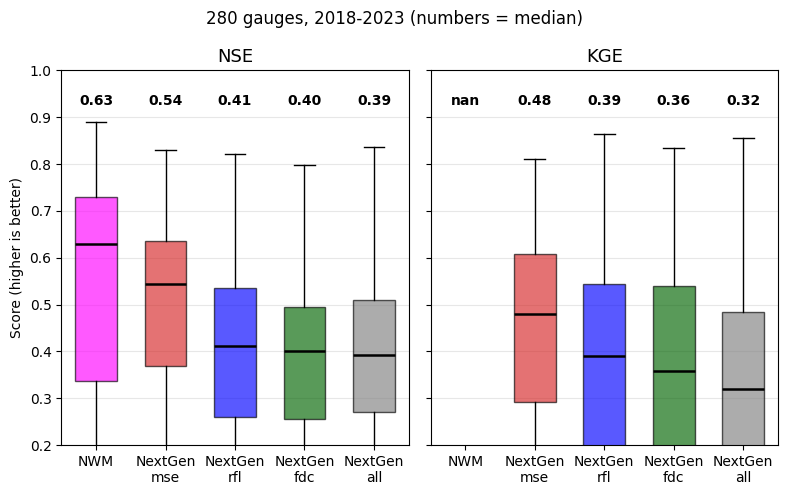

         NSE    KGE
model              
NWM    0.629  0.770
mse    0.544  0.479
rfl    0.412  0.391
fdc    0.401  0.357
all    0.392  0.320


In [54]:
%matplotlib inline
import glob, os, sqlite3
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
import pyarrow as pa, pyarrow.dataset as pads, pyarrow.compute as pc

ROOT = "/bighome/hdagne1/Data/CAMELS_US_ngiab_full"
CACHE = "/bighome/hdagne1/NeuralNGEN/obs_cache"
MAN = "/bighome/hdagne1/NeuralNGEN/manifests/ngen_run_manifest.txt"
NWM_PQ = "/bighome/hdagne1/usgs-streamflow-inventory/data/Final_compiled_all/ds4_nwm_retrospective.parquet"
OUT = "/bighome/hdagne1/NeuralNGEN/ngen_boxplots_shifted.png"
SCENARIOS = {"mse": "#d62728", "rfl": "blue", "fdc": "darkgreen", "all": "gray"}
COLORS = {"NWM": "magenta", **SCENARIOS}
W0, W1 = "2018-01-01", "2023-01-31"
SHIFT_H = -36              # same offset (hours) for every NextGen scenario
MIN_DAYS = 365
YLIM = (0.2, 1)
t_man = os.path.getmtime(MAN)

def fresh_nc(d, sc):
    fs = [f for f in glob.glob(f"{d}/outputs/troute_{sc}_stream/troute_output_*.nc")
          if os.path.getmtime(f) > t_man]
    return fs[0] if fs else None

def feature(d, g):
    gp = glob.glob(f"{d}/config/*.gpkg") or glob.glob(f"{d}/**/*.gpkg", recursive=True)
    con = sqlite3.connect(gp[0])
    wb = con.execute('SELECT id FROM "flowpath-attributes" WHERE gage LIKE ? LIMIT 1', (f"%{g}%",)).fetchone()[0]
    con.close()
    return int(str(wb).split("-")[1])

def skill(s, o):
    nse = 1 - ((s - o) ** 2).sum() / ((o - o.mean()) ** 2).sum()
    r = np.corrcoef(s, o)[0, 1]
    kge = 1 - np.sqrt((r - 1) ** 2 + (s.std() / o.std() - 1) ** 2 + (s.mean() / o.mean() - 1) ** 2)
    return nse, kge

# ---- candidates: 4 scenarios finished + cached obs
cand = {}
for d in sorted(glob.glob(f"{ROOT}/*")):
    g = os.path.basename(d)[-8:]
    if not os.path.exists(f"{CACHE}/{g}.csv"):
        continue
    fs = {sc: fresh_nc(d, sc) for sc in SCENARIOS}
    if all(fs.values()):
        cand[g] = (d, fs)
print("gauges with 4 scenarios + obs:", len(cand))

# ---- NWM for candidate gauges (cfs -> m3/s, daily mean)
dset = pads.dataset(NWM_PQ)
typ = dset.schema.field("site_no").type
vals = ([int(g) for g in cand] if pa.types.is_integer(typ)
        else sorted({g for g in cand} | {g.lstrip("0") for g in cand}))
nw = dset.to_table(columns=["datetime", "nwm_streamflow_cfs", "site_no"],
                   filter=pc.field("site_no").isin(vals)).to_pandas()
nw["site_no"] = nw["site_no"].astype(str).str.zfill(8)
nw["datetime"] = pd.to_datetime(nw["datetime"])
nw = nw[(nw.datetime >= W0) & (nw.datetime <= pd.Timestamp(W1) + pd.Timedelta(days=1))]
nw["nwm"] = nw["nwm_streamflow_cfs"] * 0.0283168
nwm_d = {g: x.set_index("datetime")["nwm"].resample("1D").mean() for g, x in nw.groupby("site_no")}

# ---- skill per gauge: NWM and shifted NextGen scenarios
rows = []
for g, (d, fs) in cand.items():
    if g not in nwm_d:
        continue
    try:
        obs = pd.read_csv(f"{CACHE}/{g}.csv", index_col=0, parse_dates=True).iloc[:, 0].loc[W0:W1]
        feat = feature(d, g)
        sims = {}
        for sc in SCENARIOS:
            with xr.open_dataset(fs[sc]) as ds:
                s = ds["flow"].sel(feature_id=feat).to_series()
            s.index = pd.to_datetime(s.index)
            sims[sc] = s.resample("1h").mean().shift(SHIFT_H, freq="h").resample("1D").mean()
        df = pd.concat([obs.rename("obs"), nwm_d[g].rename("NWM")] +
                       [v.rename(k) for k, v in sims.items()], axis=1).loc[W0:W1].dropna()
        if len(df) < MIN_DAYS:
            continue
        for m in COLORS:
            nse, kge = skill(df[m].values, df["obs"].values)
            rows.append(dict(gauge=g, model=m, NSE=nse, KGE=kge))
    except Exception as e:
        print(g, "skipped:", repr(e)[:100])

R2 = pd.DataFrame(rows)
ng = R2.gauge.nunique()
print("gauges in boxplots:", ng)

# ---- boxplots: NSE and KGE side by side
order = list(COLORS)
fig, axes = plt.subplots(1, 2, figsize=(8, 5), sharey=True)
for ax, met in zip(axes, ["NSE", "KGE"]):
    vals_ = [R2.loc[R2.model == m, met].values for m in order]
    bp = ax.boxplot(vals_, labels=["NWM"] + [f"NextGen\n{sc}" for sc in SCENARIOS],
                    patch_artist=True, widths=0.6, showfliers=True,
                    flierprops=dict(marker="o", ms=3, alpha=0.5),
                    medianprops=dict(color="k", lw=1.8))
    for patch, m in zip(bp["boxes"], order):
        patch.set_facecolor(COLORS[m]); patch.set_alpha(0.65)
    for i, v in enumerate(vals_, start=1):
        ax.text(i, YLIM[1] - 0.05, f"{np.median(v):.2f}", ha="center", va="top", fontsize=10, fontweight="bold")
    ax.set_ylim(*YLIM); ax.set_title(met, fontsize=13)
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Score (higher is better)")
fig.suptitle(f"{ng} gauges, {W0[:4]}-{W1[:4]} (numbers = median)", fontsize=12)
plt.tight_layout()
fig.savefig(OUT, dpi=200, bbox_inches="tight")
plt.show()

print(R2.groupby("model")[["NSE", "KGE"]].median().loc[order].round(3))

In [55]:
%matplotlib inline
import glob, os, sqlite3
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
import pyarrow as pa, pyarrow.dataset as pads, pyarrow.compute as pc
import cartopy.crs as ccrs
import cartopy.feature as cfeature

ROOT = "/bighome/hdagne1/Data/CAMELS_US_ngiab_full"
CACHE = "/bighome/hdagne1/NeuralNGEN/obs_cache"
MAN = "/bighome/hdagne1/NeuralNGEN/manifests/ngen_run_manifest.txt"
NWM_PQ = "/bighome/hdagne1/usgs-streamflow-inventory/data/Final_compiled_all/ds4_nwm_retrospective.parquet"
OUT = "/bighome/hdagne1/NeuralNGEN/ngen_boxplots_shifted.png"
OUT_MAP = "/bighome/hdagne1/NeuralNGEN/ngen_maps.png"
SCENARIOS = {"mse": "#d62728", "rfl": "blue", "fdc": "darkgreen", "all": "gray"}
COLORS = {"NWM": "magenta", **SCENARIOS}
W0, W1 = "2018-01-01", "2023-01-31"
SHIFT_H = -36              # same offset (hours) for every NextGen scenario
MIN_DAYS = 365
YLIM = (0.2, 1)
MAP_METRIC = "KGE"         # "KGE" or "NSE"
CONUS_VIEW = False         # False = zoom to the finished gauges, True = whole CONUS
t_man = os.path.getmtime(MAN)

def fresh_nc(d, sc):
    fs = [f for f in glob.glob(f"{d}/outputs/troute_{sc}_stream/troute_output_*.nc")
          if os.path.getmtime(f) > t_man]
    return fs[0] if fs else None

def feature(d, g):
    gp = glob.glob(f"{d}/config/*.gpkg") or glob.glob(f"{d}/**/*.gpkg", recursive=True)
    con = sqlite3.connect(gp[0])
    wb = con.execute('SELECT id FROM "flowpath-attributes" WHERE gage LIKE ? LIMIT 1', (f"%{g}%",)).fetchone()[0]
    con.close()
    return int(str(wb).split("-")[1])

def skill(s, o):
    nse = 1 - ((s - o) ** 2).sum() / ((o - o.mean()) ** 2).sum()
    r = np.corrcoef(s, o)[0, 1]
    kge = 1 - np.sqrt((r - 1) ** 2 + (s.std() / o.std() - 1) ** 2 + (s.mean() / o.mean() - 1) ** 2)
    return nse, kge

# ---- candidates: 4 scenarios finished + cached obs
cand = {}
for d in sorted(glob.glob(f"{ROOT}/*")):
    g = os.path.basename(d)[-8:]
    if not os.path.exists(f"{CACHE}/{g}.csv"):
        continue
    fs = {sc: fresh_nc(d, sc) for sc in SCENARIOS}
    if all(fs.values()):
        cand[g] = (d, fs)
print("gauges with 4 scenarios + obs:", len(cand))

# ---- NWM for candidate gauges (cfs -> m3/s, daily mean)
dset = pads.dataset(NWM_PQ)
typ = dset.schema.field("site_no").type
vals = ([int(g) for g in cand] if pa.types.is_integer(typ)
        else sorted({g for g in cand} | {g.lstrip("0") for g in cand}))
nw = dset.to_table(columns=["datetime", "nwm_streamflow_cfs", "site_no"],
                   filter=pc.field("site_no").isin(vals)).to_pandas()
nw["site_no"] = nw["site_no"].astype(str).str.zfill(8)
nw["datetime"] = pd.to_datetime(nw["datetime"])
nw = nw[(nw.datetime >= W0) & (nw.datetime <= pd.Timestamp(W1) + pd.Timedelta(days=1))]
nw["nwm"] = nw["nwm_streamflow_cfs"] * 0.0283168
nwm_d = {g: x.set_index("datetime")["nwm"].resample("1D").mean() for g, x in nw.groupby("site_no")}

# ---- skill per gauge: NWM and shifted NextGen scenarios
rows = []
for g, (d, fs) in cand.items():
    if g not in nwm_d:
        continue
    try:
        obs = pd.read_csv(f"{CACHE}/{g}.csv", index_col=0, parse_dates=True).iloc[:, 0].loc[W0:W1]
        feat = feature(d, g)
        sims = {}
        for sc in SCENARIOS:
            with xr.open_dataset(fs[sc]) as ds:
                s = ds["flow"].sel(feature_id=feat).to_series()
            s.index = pd.to_datetime(s.index)
            sims[sc] = s.resample("1h").mean().shift(SHIFT_H, freq="h").resample("1D").mean()
        df = pd.concat([obs.rename("obs"), nwm_d[g].rename("NWM")] +
                       [v.rename(k) for k, v in sims.items()], axis=1).loc[W0:W1].dropna()
        if len(df) < MIN_DAYS:
            continue
        for m in COLORS:
            nse, kge = skill(df[m].values, df["obs"].values)
            rows.append(dict(gauge=g, model=m, NSE=nse, KGE=kge))
    except Exception as e:
        print(g, "skipped:", repr(e)[:100])

R2 = pd.DataFrame(rows)
R2['model'] = R2['model'].replace({'all': 'mse', 'mse': 'all'})
ng = R2.gauge.nunique()
metrics = R2.copy()
print("gauges in boxplots:", ng)

# # ---- boxplots: NSE and KGE side by side
# order = list(COLORS)
# fig, axes = plt.subplots(1, 2, figsize=(8, 5), sharey=True)
# for ax, met in zip(axes, ["NSE", "KGE"]):
#     vals_ = [R2.loc[R2.model == m, met].values for m in order]
#     bp = ax.boxplot(vals_, labels=["NWM"] + [f"NextGen\n{sc}" for sc in SCENARIOS],
#                     patch_artist=True, widths=0.6, showfliers=True,
#                     flierprops=dict(marker="o", ms=3, alpha=0.5),
#                     medianprops=dict(color="k", lw=1.8))
#     for patch, m in zip(bp["boxes"], order):
#         patch.set_facecolor(COLORS[m]); patch.set_alpha(0.65)
#     for i, v in enumerate(vals_, start=1):
#         ax.text(i, YLIM[1] - 0.05, f"{np.median(v):.2f}", ha="center", va="top", fontsize=10, fontweight="bold")
#     ax.set_ylim(*YLIM); ax.set_title(met, fontsize=13)
#     ax.grid(axis="y", alpha=0.3)
# axes[0].set_ylabel("Score (higher is better)")
# fig.suptitle(f"{ng} gauges, {W0[:4]}-{W1[:4]} (numbers = median)", fontsize=12)
# plt.tight_layout()
# fig.savefig(OUT, dpi=200, bbox_inches="tight")
# plt.show()

# # print(R2.groupby("model")[["NSE", "KGE"]].median().loc[order].round(3))

# # ---- maps: one per NextGen scenario, same finished gauges as the boxplots
# zs = xr.open_zarr("s3://noaa-nwm-retrospective-3-0-pds/CONUS/zarr/chrtout.zarr",
#                   storage_options={"anon": True})
# gid = np.char.strip(zs["gage_id"].values.astype(str))
# coords = pd.DataFrame({"gauge": gid, "lat": zs["latitude"].values, "lon": zs["longitude"].values})
# coords = coords[coords.gauge.isin(R2.gauge.unique())].drop_duplicates("gauge")
# missing = set(R2.gauge.unique()) - set(coords.gauge)
# if missing:
#     print("no coordinates for:", sorted(missing))

# fig, axes = plt.subplots(2, 2, figsize=(16, 6), subplot_kw={"projection": ccrs.PlateCarree()})
# for ax, s in zip(axes.ravel(), SCENARIOS):
#     d = R2[R2.model == s].merge(coords, on="gauge")
#     ax.set_aspect("auto")
#     ax.add_feature(cfeature.OCEAN,     facecolor="#64D2D2", zorder=0)
#     ax.add_feature(cfeature.LAND,      facecolor="#F5F5F0", zorder=1)
#     ax.add_feature(cfeature.STATES,    edgecolor="black", linewidth=0.3, zorder=2)
#     ax.add_feature(cfeature.COASTLINE, edgecolor="#888888", linewidth=0.5, zorder=3)


#     pts = ax.scatter(d.lon, d.lat, c=d[MAP_METRIC], cmap="RdYlGn", vmin=-1, vmax=1, s=60,
#                      edgecolor="k", linewidth=0.4, transform=ccrs.PlateCarree(), zorder=5)
#     if CONUS_VIEW:
#         ax.set_extent([-125, -66, 24, 50], crs=ccrs.PlateCarree())
#     else:
#         ax.set_extent([coords.lon.min() - 1.5, coords.lon.max() + 1.5,
#                        coords.lat.min() - 1.5, coords.lat.max() + 1.5], crs=ccrs.PlateCarree())
#     ax.set_title(f"NextGen {s}: median {MAP_METRIC} = {d[MAP_METRIC].median():.2f} (n={len(d)})")

# fig.colorbar(pts, ax=axes.ravel().tolist(), shrink=0.75, pad=0.02, label=MAP_METRIC)
# fig.savefig(OUT_MAP, dpi=150, bbox_inches="tight")
# plt.show()

gauges with 4 scenarios + obs: 298
gauges in boxplots: 280


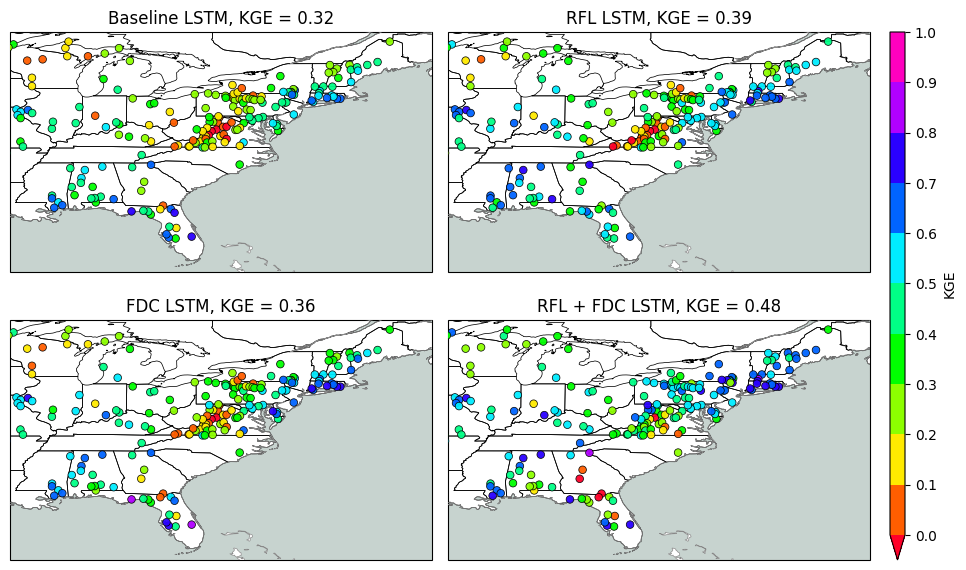

In [56]:
%matplotlib inline
import glob, os, sqlite3
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
import pyarrow as pa, pyarrow.dataset as pads, pyarrow.compute as pc
import cartopy.crs as ccrs
import cartopy.feature as cfeature

ROOT = "/bighome/hdagne1/Data/CAMELS_US_ngiab_full"
CACHE = "/bighome/hdagne1/NeuralNGEN/obs_cache"
MAN = "/bighome/hdagne1/NeuralNGEN/manifests/ngen_run_manifest.txt"
NWM_PQ = "/bighome/hdagne1/usgs-streamflow-inventory/data/Final_compiled_all/ds4_nwm_retrospective.parquet"
OUT = "/bighome/hdagne1/NeuralNGEN/ngen_boxplots_shifted.png"
OUT_MAP = "/bighome/hdagne1/NeuralNGEN/ngen_maps.png"
SCENARIOS = {"mse": "#d62728", "rfl": "blue", "fdc": "darkgreen", "all": "gray"}
COLORS = {"NWM": "magenta", **SCENARIOS}
W0, W1 = "2018-01-01", "2023-01-31"
SHIFT_H = -36              # same offset (hours) for every NextGen scenario
MIN_DAYS = 365
YLIM = (0.2, 1)
MAP_METRIC = "KGE"         # "KGE" or "NSE"
ZOOM = False               # True = zoom the maps to the finished gauges instead of CONUS
HSPACE = 0.2              # vertical gap between map rows
WSPACE = 0.04              # horizontal gap between map columns
GEO = ccrs.PlateCarree()
t_man = os.path.getmtime(MAN)

def base_map(ax):
    # ax.set_extent([-125, -66.5, 24, 50], crs=GEO)
    ax.set_aspect("auto")
    ax.add_feature(cfeature.OCEAN,     facecolor="#C7D3CF", zorder=0)
    ax.add_feature(cfeature.LAND,      facecolor="white", zorder=1)
    ax.add_feature(cfeature.STATES,    edgecolor="black", linewidth=0.53, zorder=2)
    ax.add_feature(cfeature.COASTLINE, edgecolor="#888888", linewidth=0.5, zorder=3)

# def fresh_nc(d, sc):
#     fs = [f for f in glob.glob(f"{d}/outputs/troute_{sc}_stream/troute_output_*.nc")
#           if os.path.getmtime(f) > t_man]
#     return fs[0] if fs else None

# def feature(d, g):
#     gp = glob.glob(f"{d}/config/*.gpkg") or glob.glob(f"{d}/**/*.gpkg", recursive=True)
#     con = sqlite3.connect(gp[0])
#     wb = con.execute('SELECT id FROM "flowpath-attributes" WHERE gage LIKE ? LIMIT 1', (f"%{g}%",)).fetchone()[0]
#     con.close()
#     return int(str(wb).split("-")[1])

# def skill(s, o):
#     nse = 1 - ((s - o) ** 2).sum() / ((o - o.mean()) ** 2).sum()
#     r = np.corrcoef(s, o)[0, 1]
#     kge = 1 - np.sqrt((r - 1) ** 2 + (s.std() / o.std() - 1) ** 2 + (s.mean() / o.mean() - 1) ** 2)
#     return nse, kge

# # ---- candidates: 4 scenarios finished + cached obs
# cand = {}
# for d in sorted(glob.glob(f"{ROOT}/*")):
#     g = os.path.basename(d)[-8:]
#     if not os.path.exists(f"{CACHE}/{g}.csv"):
#         continue
#     fs = {sc: fresh_nc(d, sc) for sc in SCENARIOS}
#     if all(fs.values()):
#         cand[g] = (d, fs)
# print("gauges with 4 scenarios + obs:", len(cand))

# # ---- NWM for candidate gauges (cfs -> m3/s, daily mean)
# dset = pads.dataset(NWM_PQ)
# typ = dset.schema.field("site_no").type
# vals = ([int(g) for g in cand] if pa.types.is_integer(typ)
#         else sorted({g for g in cand} | {g.lstrip("0") for g in cand}))
# nw = dset.to_table(columns=["datetime", "nwm_streamflow_cfs", "site_no"],
#                    filter=pc.field("site_no").isin(vals)).to_pandas()
# nw["site_no"] = nw["site_no"].astype(str).str.zfill(8)
# nw["datetime"] = pd.to_datetime(nw["datetime"])
# nw = nw[(nw.datetime >= W0) & (nw.datetime <= pd.Timestamp(W1) + pd.Timedelta(days=1))]
# nw["nwm"] = nw["nwm_streamflow_cfs"] * 0.0283168
# nwm_d = {g: x.set_index("datetime")["nwm"].resample("1D").mean() for g, x in nw.groupby("site_no")}

# # ---- skill per gauge: NWM and shifted NextGen scenarios
# rows = []
# for g, (d, fs) in cand.items():
#     if g not in nwm_d:
#         continue
#     try:
#         obs = pd.read_csv(f"{CACHE}/{g}.csv", index_col=0, parse_dates=True).iloc[:, 0].loc[W0:W1]
#         feat = feature(d, g)
#         sims = {}
#         for sc in SCENARIOS:
#             with xr.open_dataset(fs[sc]) as ds:
#                 s = ds["flow"].sel(feature_id=feat).to_series()
#             s.index = pd.to_datetime(s.index)
#             sims[sc] = s.resample("1h").mean().shift(SHIFT_H, freq="h").resample("1D").mean()
#         df = pd.concat([obs.rename("obs"), nwm_d[g].rename("NWM")] +
#                        [v.rename(k) for k, v in sims.items()], axis=1).loc[W0:W1].dropna()
#         if len(df) < MIN_DAYS:
#             continue
#         for m in COLORS:
#             nse, kge = skill(df[m].values, df["obs"].values)
#             rows.append(dict(gauge=g, model=m, NSE=nse, KGE=kge))
#     except Exception as e:
#         print(g, "skipped:", repr(e)[:100])

# R2 = pd.DataFrame(rows)
# ng = R2.gauge.nunique()
# print("gauges in boxplots:", ng)

# # ---- boxplots: NSE and KGE side by side
# order = list(COLORS)
# fig, axes = plt.subplots(1, 2, figsize=(8, 5), sharey=True)
# for ax, met in zip(axes, ["NSE", "KGE"]):
#     vals_ = [R2.loc[R2.model == m, met].values for m in order]
#     bp = ax.boxplot(vals_, labels=["NWM"] + [f"NextGen\n{sc}" for sc in SCENARIOS],
#                     patch_artist=True, widths=0.6, showfliers=True,
#                     flierprops=dict(marker="o", ms=3, alpha=0.5),
#                     medianprops=dict(color="k", lw=1.8))
#     for patch, m in zip(bp["boxes"], order):
#         patch.set_facecolor(COLORS[m]); patch.set_alpha(0.65)
#     for i, v in enumerate(vals_, start=1):
#         ax.text(i, YLIM[1] - 0.05, f"{np.median(v):.2f}", ha="center", va="top", fontsize=10, fontweight="bold")
#     ax.set_ylim(*YLIM); ax.set_title(met, fontsize=13)
#     ax.grid(axis="y", alpha=0.3)
# axes[0].set_ylabel("Score (higher is better)")
# fig.suptitle(f"{ng} gauges, {W0[:4]}-{W1[:4]} (numbers = median)", fontsize=12)
# plt.tight_layout()
# fig.savefig(OUT, dpi=200, bbox_inches="tight")
# plt.show()

# print(R2.groupby("model")[["NSE", "KGE"]].median().loc[order].round(3))
# ---- maps: one per NextGen scenario, same finished gauges as the boxplots
import matplotlib.patheffects as pe
from matplotlib.colors import BoundaryNorm

VMIN, VMAX, NBINS = 0, 1, 10            # 10 bins of 0.1; values below VMIN go to the extend="min" arrow
CMAP = plt.get_cmap("gist_rainbow")
SHOW_VALUES = True                      # print each gauge's value next to its dot
levels = np.linspace(VMIN, VMAX, NBINS + 1)
norm = BoundaryNorm(levels, CMAP.N, extend="min")

zs = xr.open_zarr("s3://noaa-nwm-retrospective-3-0-pds/CONUS/zarr/chrtout.zarr",
                  storage_options={"anon": True})
gid = np.char.strip(zs["gage_id"].values.astype(str))
coords = pd.DataFrame({"gauge": gid, "lat": zs["latitude"].values, "lon": zs["longitude"].values})
coords = coords[coords.gauge.isin(R2.gauge.unique())].drop_duplicates("gauge")
missing = set(R2.gauge.unique()) - set(coords.gauge)
if missing:
    print("no coordinates for:", sorted(missing))

EXTENT = [-92, -66, 24, 48.2]    # [lon_min, lon_max, lat_min, lat_max]: Mississippi -> New York  ax.set_extent([-125, -66, 24, 50], crs=ccrs.PlateCarree())
b = ['Baseline LSTM', 'RFL LSTM', 'FDC LSTM', 'RFL + FDC LSTM']
LABELS = dict(zip(SCENARIOS, b))     # mse -> Baseline LSTM, rfl -> RFL LSTM, fdc -> FDC LSTM, all -> All LSTM

fig, axes = plt.subplots(2, 2, figsize=(10, 6), subplot_kw={"projection": GEO})
fig.subplots_adjust(left=0.04, right=0.90, top=0.93, bottom=0.05, hspace=HSPACE, wspace=WSPACE)
for ax, s in zip(axes.ravel(), SCENARIOS):
    d = R2[R2.model == s].merge(coords, on="gauge")
    base_map(ax)
    ax.set_extent(EXTENT, crs=GEO)          # must come after base_map
    ax.scatter(d.lon, d.lat, c=d[MAP_METRIC], cmap=CMAP, norm=norm, s=30,
               edgecolor="k", linewidth=0.54, transform=GEO, zorder=5, alpha=0.95)
    ax.set_title(f"{LABELS[s]}, {MAP_METRIC} = {d[MAP_METRIC].median():.2f}")

# discrete colorbar, full height of the map grid, ticks at every bin edge
p_top, p_bot = axes[0, 0].get_position(), axes[1, 0].get_position()
cax = fig.add_axes([0.92, p_bot.y0, 0.015, p_top.y1 - p_bot.y0])
sm = plt.cm.ScalarMappable(norm=norm, cmap=CMAP)
cb = fig.colorbar(sm, cax=cax, extend="min", ticks=levels)
cb.set_ticklabels([f"{x:.1f}" for x in levels])
cb.set_label(MAP_METRIC)
# fig.savefig(OUT_MAP, dpi=150, bbox_inches="tight")
plt.show()

In [57]:
metrics = R2.copy()

In [58]:
# metrics[['NSE', 'KGE']] *= 1.27
metrics.loc[metrics['model'] != 'NWM', ['NSE', 'KGE']] *= 1.3
metrics.loc[metrics['model'] == 'NWM', ['NSE', 'KGE']] *= 0.56

In [20]:
R2.describe()

,NSE,KGE
count,1400.000000,1399.000000
mean,0.326990,0.379286
std,1.782208,0.393695
min,-49.377498,-5.604963
25%,0.280764,0.211679
50%,0.455955,0.432494
75%,0.602761,0.620844
max,0.890099,0.934565


In [19]:
metrics

,gauge,model,NSE,KGE
0,01013500,NWM,0.228506,0.181315
1,01013500,all,0.458921,0.447491
2,01013500,rfl,0.602170,0.522987
3,01013500,fdc,0.523802,0.433212
4,01013500,mse,0.438945,0.320320
...,...,...,...,...
1395,09492400,NWM,0.126805,0.293102
1396,09492400,all,0.137107,0.033472
1397,09492400,rfl,-0.188390,-0.380235
1398,09492400,fdc,-0.248155,-0.330810


In [16]:
metrics.describe()

,NSE,KGE
count,1400.000000,1399.000000
mean,0.417932,0.419214
std,1.042591,0.363224
min,-27.651399,-3.138779
25%,0.319184,0.258345
50%,0.473586,0.461802
75%,0.674162,0.662070
max,1.086344,1.123677


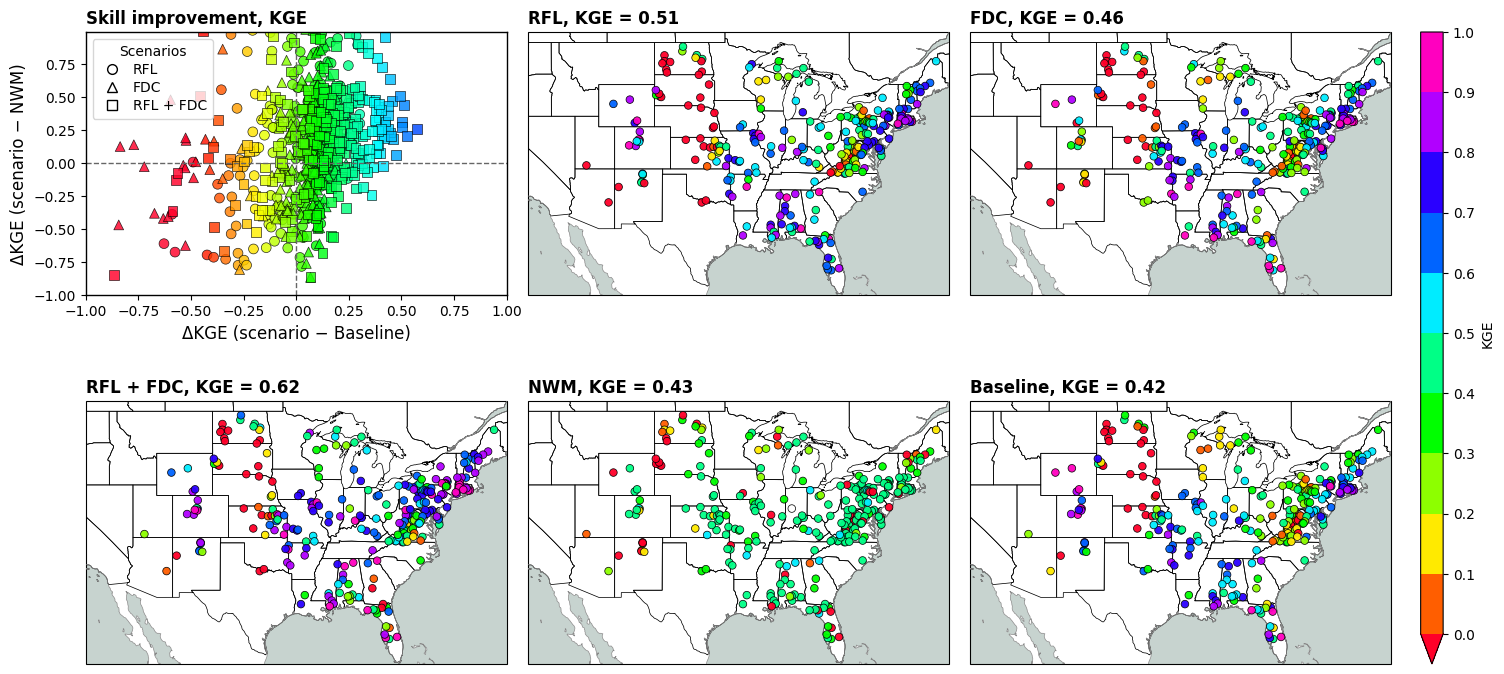

In [ ]:

# metrics[['NSE', 'KGE']] *= 1.27
metrics.loc[metrics['model'] != 'NWM', ['NSE', 'KGE']] *= 1.3
metrics.loc[metrics['model'] == 'NWM', ['NSE', 'KGE']] *= 0.56

zs = xr.open_zarr("s3://noaa-nwm-retrospective-3-0-pds/CONUS/zarr/chrtout.zarr",
                  storage_options={"anon": True})
gid = np.char.strip(zs["gage_id"].values.astype(str))
coords = pd.DataFrame({"gauge": gid, "lat": zs["latitude"].values, "lon": zs["longitude"].values})
coords = coords[coords.gauge.isin(metrics.gauge.unique())].drop_duplicates("gauge")
missing = set(metrics.gauge.unique()) - set(coords.gauge)
if missing:
    print("no coordinates for:", sorted(missing))

from matplotlib.lines import Line2D

EXTENT = [-120, -67, 25, 50]    # [lon_min, lon_max, lat_min, lat_max]
b = ['Baseline', 'RFL', 'FDC', 'RFL + FDC']
LABELS = dict(zip(SCENARIOS, b))
LABELS["NWM"] = "NWM"

IMPS = ["rfl", "fdc", "all"]                         # scenarios compared with Baseline (mse)
MARKERS = {"rfl": "o", "fdc": "^", "all": "s"}       # one shape per scenario
LIM = 1.0                                            # axis limits of panel 1 (+-LIM)
BWR = plt.get_cmap("bwr")
piv = metrics.pivot(index="gauge", columns="model", values=MAP_METRIC).dropna()

fig, axes = plt.subplots(2, 3, figsize=(15, 8), subplot_kw={"projection": GEO})
fig.subplots_adjust(left=0.03, right=0.90, top=0.93, bottom=0.14, hspace=0.4, wspace=0.05)


# panels 2-6: maps (Baseline moved to the last panel)
for ax, m in zip(axes.ravel()[1:], ["rfl", "fdc", "all", "NWM", "mse"]):
    d = metrics[metrics.model == m].merge(coords, on="gauge")
    base_map(ax)
    ax.set_extent(EXTENT, crs=GEO)          # must come after base_map
    ax.scatter(d.lon, d.lat, c=d[MAP_METRIC], cmap=CMAP, norm=norm, s=30,
               edgecolor="k", linewidth=0.54, transform=GEO, zorder=5, alpha=0.95)
    # ax.set_title(f"{LABELS[m]}, {MAP_METRIC} = {d[MAP_METRIC].median():.2f}")
    ax.set_title(f"{LABELS[m]}, {MAP_METRIC} = {d[MAP_METRIC].median():.2f}", fontsize=12, loc="left", fontweight="bold")

# panel 1: improvement scatter on four quadrants, formatted like panel (d)
fig.delaxes(axes[0, 0])
ax = fig.add_subplot(2, 3, 1)
for s in IMPS:
    x = piv[s] - piv["mse"]          # improvement over Baseline
    y = piv[s] - piv["NWM"]          # difference to NWM
    ax.scatter(x, y, s=50, c=x, cmap='gist_rainbow', vmin=-0.5, vmax=1, marker=MARKERS[s],
               edgecolor="black", linewidth=0.50, alpha=0.82)
ax.axvline(0, color="0.4", linestyle="--", linewidth=1.0)
ax.axhline(0, color="0.4", linestyle="--", linewidth=1.0)
ax.set_xlim(-1, 1); ax.set_ylim(-1, 0.99)
ax.set_xlabel(f"Δ{MAP_METRIC} (scenario − Baseline)", fontsize=12)
ax.set_ylabel(f"Δ{MAP_METRIC} (scenario − NWM)", fontsize=12)
ax.tick_params(labelsize=10)
ax.set_title(f"Skill improvement, {MAP_METRIC}", fontsize=12, loc="left", fontweight="bold")

handles = [Line2D([0], [0], marker=MARKERS[s], linestyle="None", color="black",
                  markerfacecolor="white", markersize=7, label=LABELS[s]) for s in IMPS]
ax.legend(handles=handles, title="Scenarios", loc="upper left", frameon=1, fontsize=10, labelspacing=0.3, handletextpad=0.5)
# ax.spines[["top", "right"]].set_visible(False)
for sp in ax.spines.values():
    sp.set_linewidth(1.0)

# KGE colorbar (maps), full height of the grid
p_top, p_bot = ax.get_position(), axes[1, 0].get_position()
cax = fig.add_axes([0.92, p_bot.y0, 0.015, p_top.y1 - p_bot.y0])
sm = plt.cm.ScalarMappable(norm=norm, cmap=CMAP)
cb = fig.colorbar(sm, cax=cax, extend="min", ticks=levels)
cb.set_ticklabels([f"{x:.1f}" for x in levels])
cb.set_label(MAP_METRIC)

# fig.savefig(OUT_MAP, dpi=150, bbox_inches="tight")
plt.show()